# APRAU 2026/27 - Assignment 1
## Group 22 - complete notebook

**Dataset:** `dataset_grupo_22.csv`, 2000 patient profiles, 33 *features* and 2 target variables,
`target_regression` (continuous) and `target_class` (three categories: `DI_HY`, `HT`, `DI_HT`).

This notebook brings together the four parts of the assignment in the order of the brief. The sections are
numbered continuously, from 0 to 26, and the cross-references in the text use that numbering.

### Contents

**Part 1 - Exploratory Data Analysis** *(assignment, section 2)*
| | |
|---|---|
| 0 | Variable dictionary |
| 1 | Descriptive statistics |
| 2 | Univariate analysis |
| 3 | Bivariate analysis |
| 4 | Synthesis and preparation for the next stages |

**Part 2 - Linear Regression** *(assignment, section 3)*
| | |
|---|---|
| 5 | Data preparation |
| 6 | Simple Linear Regression |
| 7 | Multiple Linear Regression |
| 8 | Final evaluation on the test set |
| 9 | Comparison, discussion and conclusions |

**Part 3 - Classification** *(assignment, section 4)*
| | |
|---|---|
| 10 | Data preparation |
| 11 | Logistic Regression vs LDA |
| 12 | Resampling methods |
| 13 | How does the resampling method affect the variance? |
| 14 | Which method is most appropriate? |
| 15 | Conclusions and choice of method |

**Part 4 - Feature Selection** *(assignment, section 5)*
| | |
|---|---|
| 16 | Framework |
| 17 | Data preparation |
| 18 | The three regularized models |
| 19 | Exploring different values of C |
| 20 | Choosing C by cross-validation |
| 21 | Refining C in the most favourable interval |
| 22 | Coefficients and selected variables |
| 23 | Full set vs. reduced sets |
| 24 | Effect of class balancing |
| 25 | Discussion |
| 26 | References |

### Conventions used throughout the assignment

- **Random seed 22** in every part, so that the results are reproducible.
- **Four columns removed from the outset** in every part that fits models: `calcium_baseline` (constant),
  `systolic_index` and `age_normalized` (exact reproductions of other columns) and `ldl_alternative` (values of
  `ldl` shuffled across rows). The reasons are demonstrated in section 3.2.
- **Standardization is always fitted inside each training fold** and only then applied to the validation or test
  fold. The cross-validation loops are written out explicitly, without `Pipeline`, so that this point is visible
  in the code.
- **Each part reloads the dataset and builds its own predictor matrix**, so it can be run and read independently.
  The notebook runs top to bottom in a single kernel.
- **Every block of code is preceded by its intent and followed by its conclusions**, with the numbers quoted
  always matching the values actually produced by the cell above.

# Part 1: Exploratory Data Analysis (EDA)

**Dataset:** `dataset_grupo_22.csv` - 2000 patient profiles, 33 *features* and 2 target variables.

### Objective

1. **Descriptive statistics**: data quality, types, measures of central tendency and dispersion.
2. **Univariate analysis**: distribution of each feature and of the two target variables.
3. **Bivariate analysis**: correlation between features and the relationship of each feature with `target_regression` (regression) and `target_class` (classification).
4. **Identify uninformative, constant or redundant features**, with justification.

## 0. Variable dictionary

**Demographic and socioeconomic**

| Variable | Definition in the assignment |
|---|---|
| `age` | Patient chronological age, in years |
| `age_normalized` | Standardized min-max scaling of age |
| `age_level` | Derived age category (Young, Middle, Mature, Senior) |
| `gender` | Biological sex (Male, Female) |
| `education_level` | Highest educational attainment (Primary, Secondary, Tertiary) |
| `employment_status` | Current professional status (Employed, Unemployed, Retired) |

**Anthropometric**

| Variable | Definition in the assignment |
|---|---|
| `bmi` | Body Mass Index, in kg/m² |
| `bmi_level` | WHO-standardized nutritional status (Underweight, Normal, Overweight, Obese) |

**Lifestyle**

| Variable | Definition in the assignment |
|---|---|
| `smoking` | Tobacco consumption status (Never, Former, Current) |
| `physical_activity` | Self-reported weekly exercise intensity (Low, Moderate, High) |
| `stress_level` | Quantified psychological stress tier (Low, Medium, High) |
| `sleep_hours` | Average self-reported daily sleep duration |
| `alcohol_intake` | Metric of habitual alcohol consumption |
| `salt_intake` | Dietary sodium and salt intake estimate |
| `sugar_consumption` | Frequency of refined sugar intake (Low, Medium, High) |
| `family_history` | Familial predisposition to chronic cardiometabolic conditions (Yes, No) |

**Vital signs and haemodynamics**

| Variable | Definition in the assignment |
|---|---|
| `systolic_bp` | Systolic blood pressure, in mmHg |
| `diastolic_bp` | Diastolic blood pressure, in mmHg |
| `blood_pressure` | Aggregated arterial tension measurement |
| `heart_rate` | Resting cardiac frequency, in bpm |
| `systolic_index` | Secondary index capturing haemodynamic pressure dynamics |

**Laboratory biomarkers**

| Variable | Definition in the assignment |
|---|---|
| `HbA1c_level` | Glycated haemoglobin percentage (medium-term glycaemic control) |
| `cholesterol` | Total serum cholesterol |
| `triglycerides` | Serum triglyceride level |
| `hdl` | High-Density Lipoprotein ("good" cholesterol) |
| `ldl` | Low-Density Lipoprotein ("bad" cholesterol) |
| `low_hdl_cholesterol` | Binary indicator for sub-optimal HDL |
| `high_ldl_cholesterol` | Binary indicator for elevated LDL risk |
| `crp_level` | Serum C-Reactive Protein (systemic vascular inflammation marker) |
| `homocysteine_level` | Plasma homocysteine (vascular and metabolic risk indicator) |
| `calcium_baseline` | Biochemical electrolyte baseline recording |
| `plasma_value` | Plasma viscosity variance indicator |
| `ldl_alternative` | Alternative lipid particle profile representation |

## 1. Descriptive statistics

### 1.1 Loading the data and setting up the environment

We start by loading the dataset and fixing the execution environment. We fix the random seed at **22**
so that every result involving randomness is reproducible. The file path is looked up both in the
project root and in the `notebooks` folder, so the notebook works from either of them.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22

dataset_name = 'dataset_grupo_22.csv'
dataset_candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f'Could not find {dataset_name}. Run the notebook from the project root '
        'or from the notebooks folder.'
    )

df = pd.read_csv(dataset_path)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Normal,Never,87,0.977,23.600,7.080,176.000,6.500,165.000,High,No,Medium,No,No,146.239,Low,7.897,12.253,113.000,104.000,24.600,14.300,89.000,72.000,92.000,Tertiary,Retired,113.000,9.420,1.415,166.000,90.000,DI_HY
1,Mature,Female,Obese,Never,56,0.621,36.700,8.200,225.756,6.859,254.443,High,No,High,Yes,Yes,149.058,Low,7.313,11.922,133.613,89.786,14.889,8.461,74.660,64.331,127.944,Tertiary,Unemployed,133.613,9.420,0.953,188.000,220.000,DI_HY
2,Mature,Male,Obese,Current,67,0.747,39.800,6.862,290.000,6.300,144.000,High,Yes,Low,No,Yes,148.563,Low,7.561,12.723,119.000,106.000,17.100,7.700,54.000,81.000,161.000,Tertiary,Employed,119.000,9.420,1.077,71.000,172.000,DI_HY
3,Middle,Female,Normal,Current,39,0.425,21.400,6.900,159.000,9.800,193.000,Low,No,Low,Yes,No,150.420,Medium,7.440,12.269,123.000,106.000,2.700,6.400,96.000,35.000,120.000,Secondary,Employed,123.000,9.420,1.579,185.000,92.000,DI_HY
4,Senior,Female,Normal,Never,74,0.828,23.000,7.080,163.000,6.500,88.000,High,No,Low,No,Yes,146.239,Low,7.897,12.253,133.000,96.000,6.400,7.000,99.000,45.000,172.000,Secondary,Retired,133.000,9.420,0.965,131.338,152.000,DI_HY


**Conclusions:** the dataset has **2000 rows and 35 columns** (33 *features* and the 2 target
variables), which matches the 2000-record subset described in the assignment. The first rows already
show a mixture of integer values, decimals and text categories.

### 1.2 Structure, data types and quality

Before any statistical analysis we need to know **what kind of data we are dealing with** and whether
the data is in a fit state to be analysed. We separate the numeric *features* from the categorical
ones, because they require different descriptive techniques.

In [2]:
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

num_cols = [c for c in df.select_dtypes(include='number').columns if c != TARGET_REG]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

print(f'Numeric features ({len(num_cols)}): {num_cols}\n')
print(f'Categorical features ({len(cat_cols)}): {cat_cols}\n')
print('Missing values (total):', df.isna().sum().sum())
print('Duplicated rows:', df.duplicated().sum())

pd.DataFrame({'dtype': df.dtypes.astype(str),
              'n_unique': df.nunique(),
              'missing': df.isna().sum()})

Numeric features (21): ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']

Categorical features (12): ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Missing values (total): 0
Duplicated rows: 0


,dtype,n_unique,missing
age_level,object,4,0
gender,object,2,0
bmi_level,object,4,0
smoking,object,3,0
age,int64,72,0
age_normalized,float64,131,0
bmi,float64,487,0
HbA1c_level,float64,110,0
cholesterol,float64,211,0
sleep_hours,float64,217,0


**Conclusions:** there are **21 numeric *features*** and **12 categorical ones**, plus the two target
variables.

There are no **missing values** and no **duplicated rows**, so there will be no need to impute values
or to remove records.

The categorical *features* are stored as text and will have to be **encoded** (ordinal or one-hot)
before any modelling, because linear regression, logistic regression and LDA all operate on numeric
matrices.

### 1.3 Numeric features

For the numeric variables we compute the usual measures of central tendency (mean, median) and of
dispersion (standard deviation, quartiles, minimum and maximum).

The number of distinct values is used to detect constant or near-constant variables.

In [3]:
desc = df[num_cols + [TARGET_REG]].describe().T
desc['cv'] = desc['std'] / desc['mean']
desc['skew'] = df[num_cols + [TARGET_REG]].skew()
desc['kurtosis'] = df[num_cols + [TARGET_REG]].kurt()
desc['n_unique'] = df[num_cols + [TARGET_REG]].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,cv,skew,kurtosis,n_unique
age,2000.000,55.191,20.286,18.000,38.000,57.000,73.000,89.000,0.368,-0.160,-1.146,72
age_normalized,2000.000,0.611,0.233,0.184,0.414,0.632,0.816,1.000,0.381,-0.160,-1.146,131
bmi,2000.000,27.807,7.180,15.000,21.800,27.535,33.700,59.450,0.258,0.107,-0.701,487
HbA1c_level,2000.000,6.846,0.573,3.500,6.817,6.943,7.011,9.000,0.084,-1.416,9.654,110
cholesterol,2000.000,225.051,41.294,150.000,191.000,225.373,258.000,299.000,0.183,-0.011,-1.017,211
sleep_hours,2000.000,7.047,1.631,4.000,5.700,7.012,8.400,10.000,0.231,-0.014,-1.011,217
triglycerides,2000.000,158.239,65.382,50.000,104.000,151.000,209.000,399.000,0.413,0.436,0.021,310
blood_pressure,2000.000,150.145,5.221,120.000,149.058,149.974,151.266,180.000,0.035,-0.584,14.173,140
crp_level,2000.000,7.375,1.100,0.011,7.277,7.458,7.706,14.615,0.149,-0.306,14.981,191
homocysteine_level,2000.000,12.379,1.123,5.110,12.253,12.417,12.621,19.874,0.091,-0.683,19.018,191


**Conclusions.**

- **`calcium_baseline` is a constant *feature***, with a standard deviation of exactly 0, a coefficient
  of variation of 0 and **a single distinct value** (9.42) across the 2000 rows. A variable that does
  not vary cannot explain the variation of anything.
- **There are signs of redundancy.** `systolic_bp` and `systolic_index` have exactly the same
  descriptive statistics. The same happens between `ldl` and `ldl_alternative`, and between `age` and
  `age_normalized` (which, by the assignment's definition, is a rescaling of age). We will confirm in
  the bivariate analysis whether they are **redundant**.
- `HbA1c_level`, `blood_pressure`, `crp_level` and `homocysteine_level` have a very narrow IQR relative
  to their full range (for example `blood_pressure`: IQR ≈ 149–151, range 120–180). This indicates
  highly concentrated distributions, with long tails and high kurtosis.
- **The scales are very heterogeneous**, from values around 1 in `plasma_value` up to roughly 400 in
  `triglycerides`. Regularization-based methods (Ridge and Lasso) penalize the magnitude of the
  coefficients and are therefore **scale-sensitive**, so it will be necessary to **normalize** the
  *features* before applying them.

### 1.4 Categorical features

For categorical variables, measures of central tendency do not apply. What matters is **how many
distinct categories exist**, which one is the most frequent and **how the records are split** across
each category. This last piece of information is decisive, since rare categories become problematic
for encoding and for stratified resampling, and it is here that we find out whether the classification
target variable is balanced.

In [4]:
cat_summary = pd.DataFrame({
    'n_categories': df[cat_cols + [TARGET_CLS]].nunique(),
    'mode': df[cat_cols + [TARGET_CLS]].mode().iloc[0],
    'mode_freq_%': [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in cat_cols + [TARGET_CLS]],
})
cat_summary

,n_categories,mode,mode_freq_%
age_level,4,Senior,33.000
gender,2,Male,51.350
bmi_level,4,Obese,40.200
smoking,3,Never,35.650
physical_activity,3,Moderate,34.150
family_history,2,No,51.700
stress_level,3,High,35.350
low_hdl_cholesterol,2,No,82.350
high_ldl_cholesterol,2,Yes,51.100
sugar_consumption,3,Low,36.850


In [5]:
ORDERS = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}

def order_of(c):
    return ORDERS.get(c, df[c].value_counts().index.tolist())

table_rows = []
for c in cat_cols + [TARGET_CLS]:
    vc = df[c].value_counts().reindex(order_of(c))
    for category, n in vc.items():
        table_rows.append({'variable': c, 'category': str(category), 'n': int(n),
                           '% of total': n / len(df) * 100,
                           'proportion': n / len(df) * 100})

distribution = pd.DataFrame(table_rows).set_index(['variable', 'category'])

variables = distribution.index.get_level_values('variable').to_series()
starts = [k + 1 for k, changed in enumerate(variables.ne(variables.shift()).values) if changed]
styles = [{'selector': '', 'props': 'border-collapse: collapse;'},
          {'selector': 'caption', 'props': 'font-weight: 600; padding-bottom: 8px;'},
          {'selector': 'th, td', 'props': 'padding: 3px 10px;'}]
styles += [{'selector': f'tbody tr:nth-child({k}) th, tbody tr:nth-child({k}) td',
            'props': 'border-top: 2px solid #8a94a6;'} for k in starts[1:]]

(distribution.style
    .format({'n': '{:,.0f}', '% of total': '{:.2f}%', 'proportion': lambda v: ''})
    .bar(subset=['proportion'], color='#a8c8e8', vmin=0, vmax=100)
    .set_table_styles(styles)
    .set_properties(subset=['proportion'], **{'width': '180px'})
    .set_properties(**{'font-size': '11px'})
    .set_caption('Distribution of categories within each categorical variable (n = 2000)'))

**Conclusions:** every categorical variable has between 2 and 4 categories and none has high
cardinality, so one-hot encoding will not blow up the number of columns.

The table shows that **almost all variables are practically balanced**, with the categories splitting
the 2000 records into similar proportions.

Only three variables depart from this pattern:
- `low_hdl_cholesterol` (82.35% `No`)
- `bmi_level` (40.20% `Obese` against 12.20% `Underweight`)
- `age_level` (only 7.25% `Young`, against 33.00% `Senior`).

None of them, however, has categories so rare that they would compromise stratification during the
modelling stage.

**`target_class` is the only one whose split is imbalanced**: 1798 `DI_HY` records (89.90%), against
117 `HT` (5.85%) and only 85 `DI_HT` (4.25%). This imbalance conditions every decision in the
classification stage and is analysed in detail in the next section.

## 2. Univariate analysis

### 2.1 Target variables

We start the univariate analysis with the two target variables, because they condition all the
methodological decisions that follow.

For `target_class` what matters is the **class distribution**: if it is imbalanced, *accuracy* stops
being a reliable metric and stratification becomes mandatory in the resampling methods. For
`target_regression` what matters is the **shape of the distribution**: the histogram shows us the
general shape and the Q-Q plot compares it against a normal distribution.

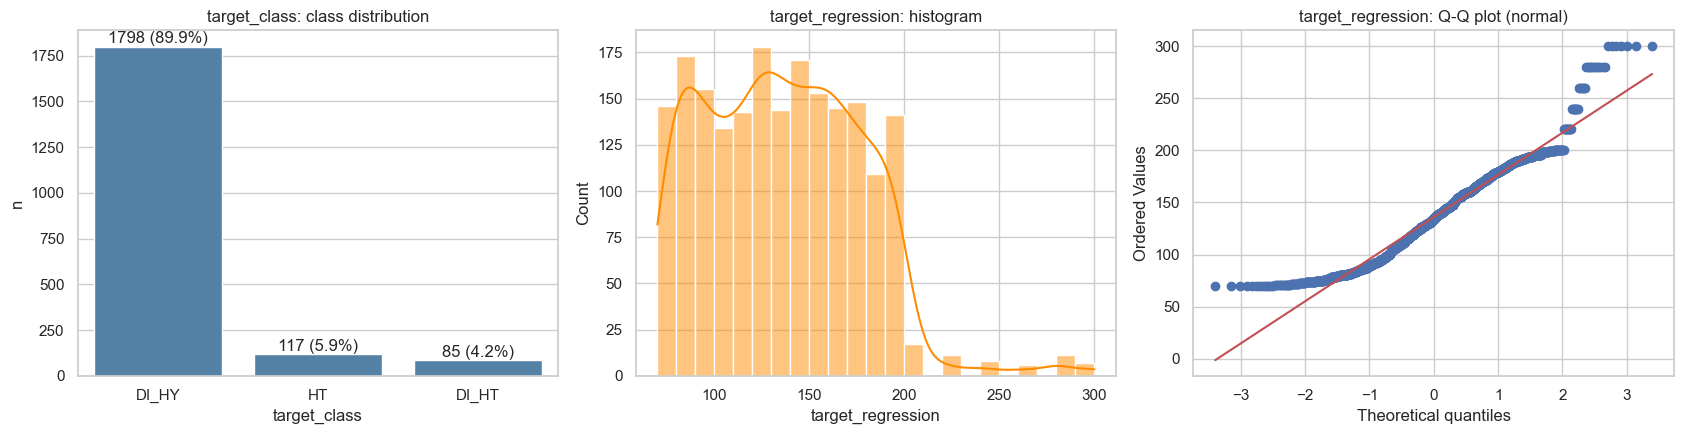

Imbalance ratio (majority / minority): 21.2
target_regression -> skew = 0.52, kurtosis = 0.42


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df[TARGET_CLS].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color='steelblue')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v} ({v/len(df):.1%})', ha='center')
axes[0].set_title('target_class: class distribution'); axes[0].set_ylabel('n')

sns.histplot(df[TARGET_REG], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('target_regression: histogram')

stats.probplot(df[TARGET_REG], dist='norm', plot=axes[2])
axes[2].set_title('target_regression: Q-Q plot (normal)')
plt.tight_layout(); plt.show()

print(f'Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f}')
print(f'target_regression -> skew = {df[TARGET_REG].skew():.2f}, '
      f'kurtosis = {df[TARGET_REG].kurt():.2f}')

**Conclusions:**

- **`target_class` is heavily imbalanced**: `DI_HY` accounts for about 90% of the records, against
  roughly 6% for `HT` and 4% for `DI_HT`. A classifier that always predicts `DI_HY` would already
  reach about 90% *accuracy*. For this reason, in classification we should use metrics such as **macro
  F1, *balanced accuracy*, per-class recall and the confusion matrix**, with **stratification** in the
  resampling methods and, possibly, `class_weight='balanced'`.
- **`target_regression`** ranges between 70 and 300 and shows a slight positive skew (right tail).

### 2.2 Numeric features: histograms and boxplots

The **histograms** show the shape of each distribution: whether it is symmetric or skewed, whether it
has one or several peaks, and whether it is approximately uniform or concentrated. The ***boxplots***
show the same information from another angle, the median, the quartiles and the distant values, and
allow the dispersion of different variables to be compared.

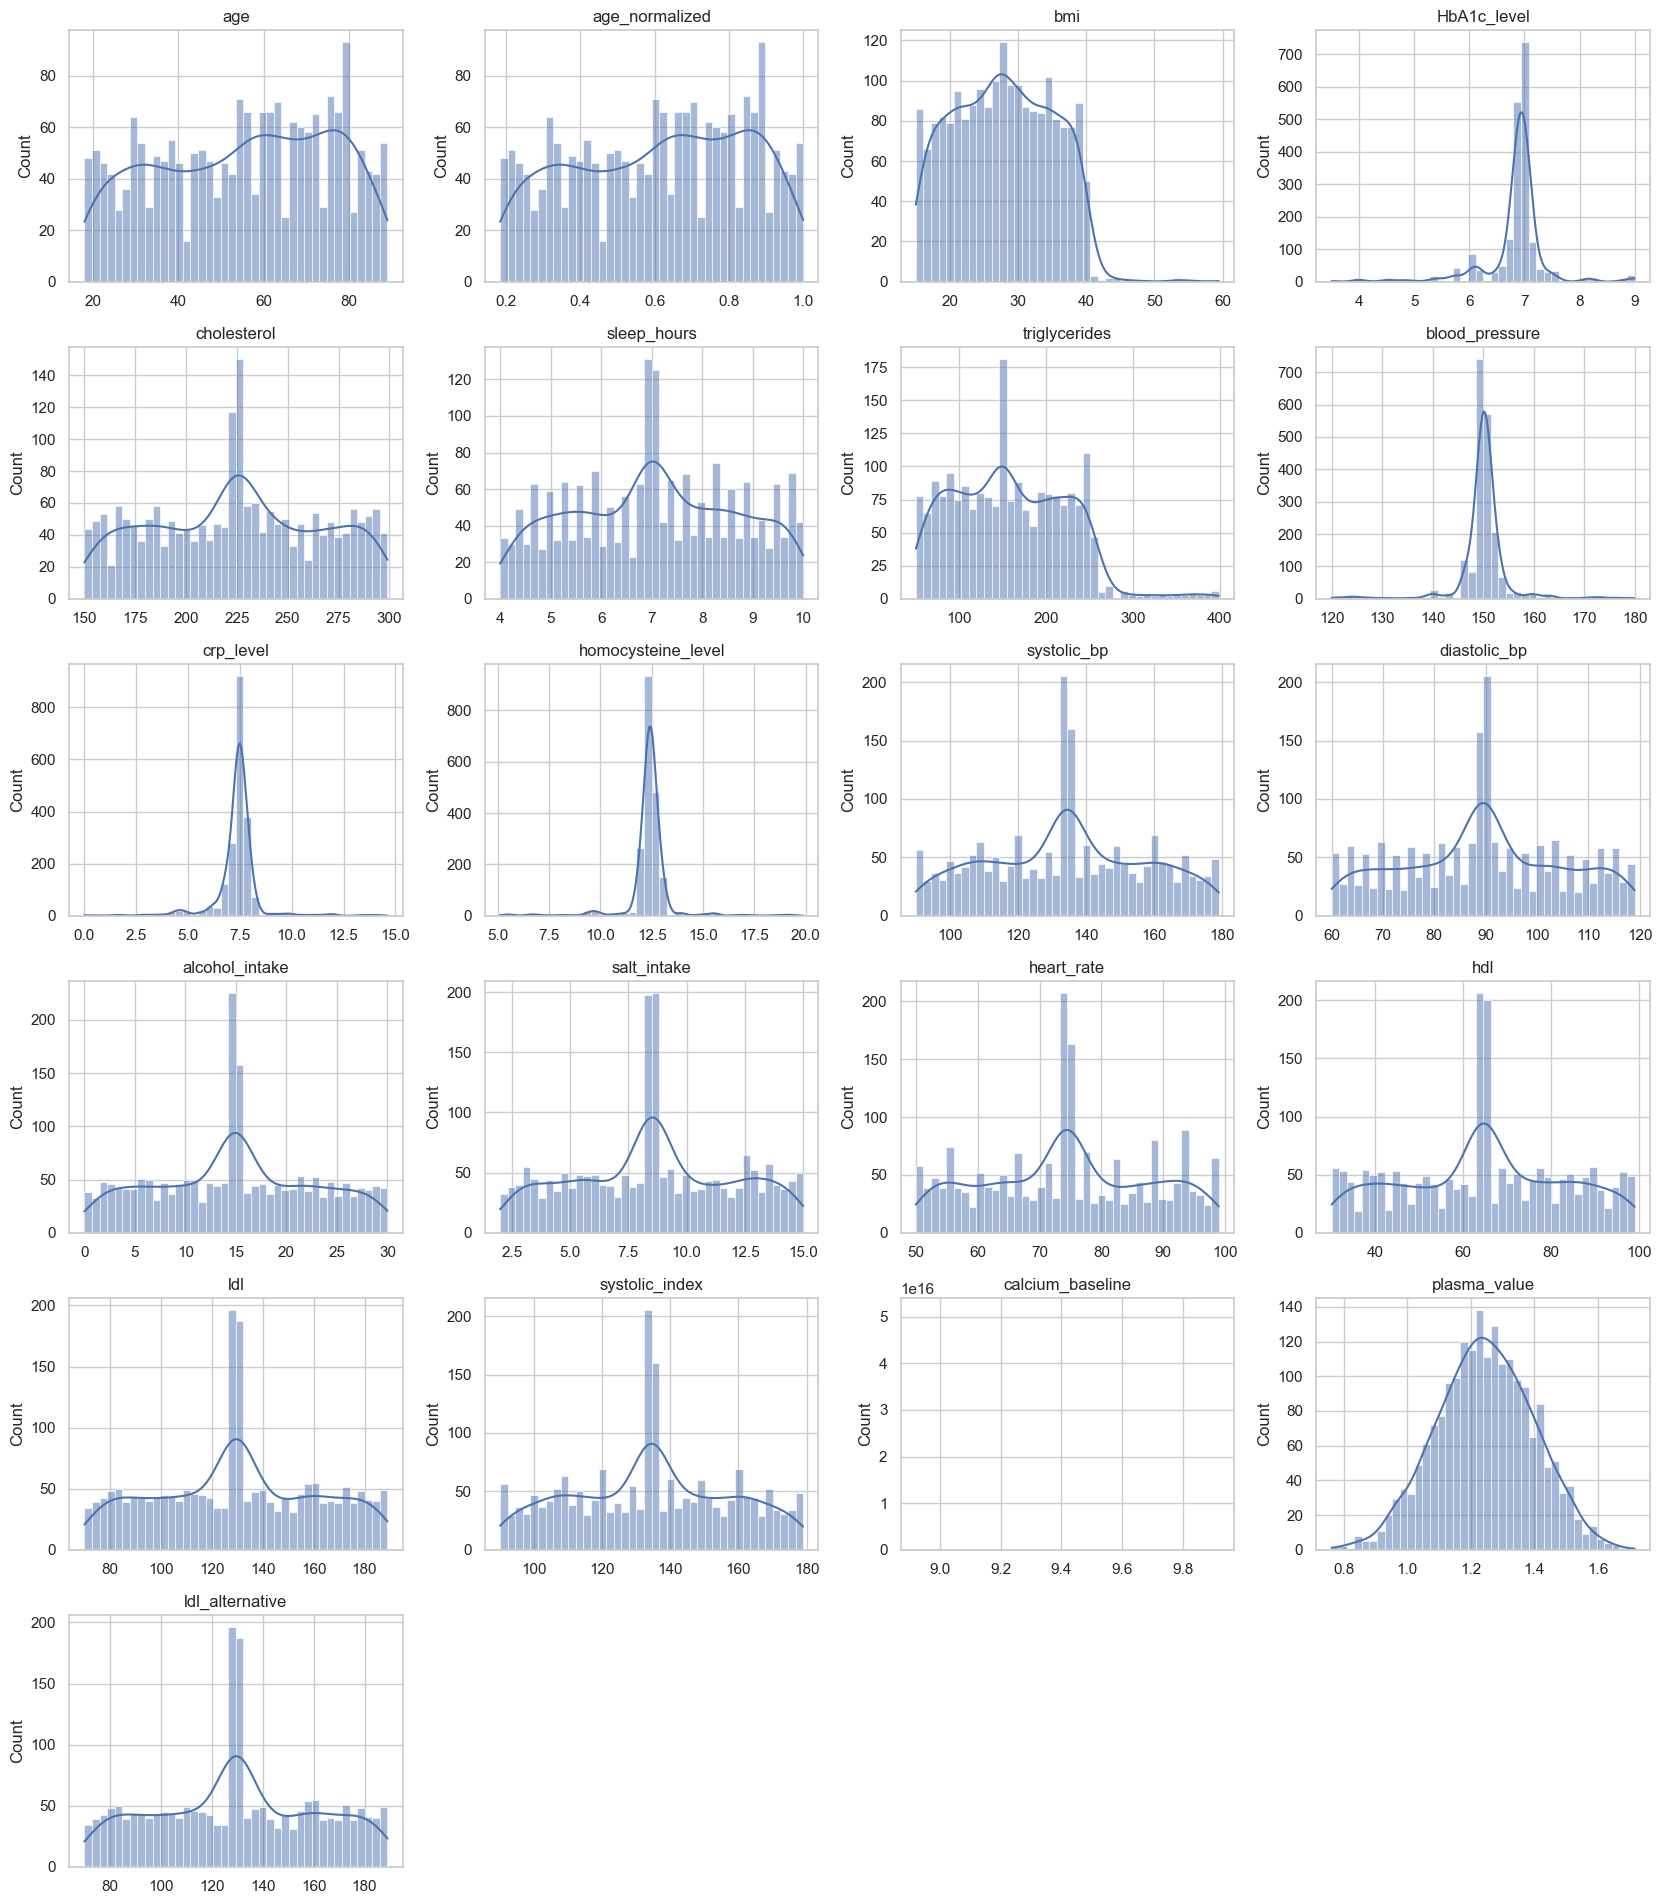

In [7]:
def grid_plot(cols, kind, ncols=4, size=(4.2, 3.2)):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == 'hist':
            sns.histplot(df[c], kde=True, ax=ax, bins=40)
        else:
            sns.boxplot(x=df[c], ax=ax, color='lightsteelblue')
        ax.set_title(c); ax.set_xlabel('')
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

grid_plot(num_cols, 'hist')

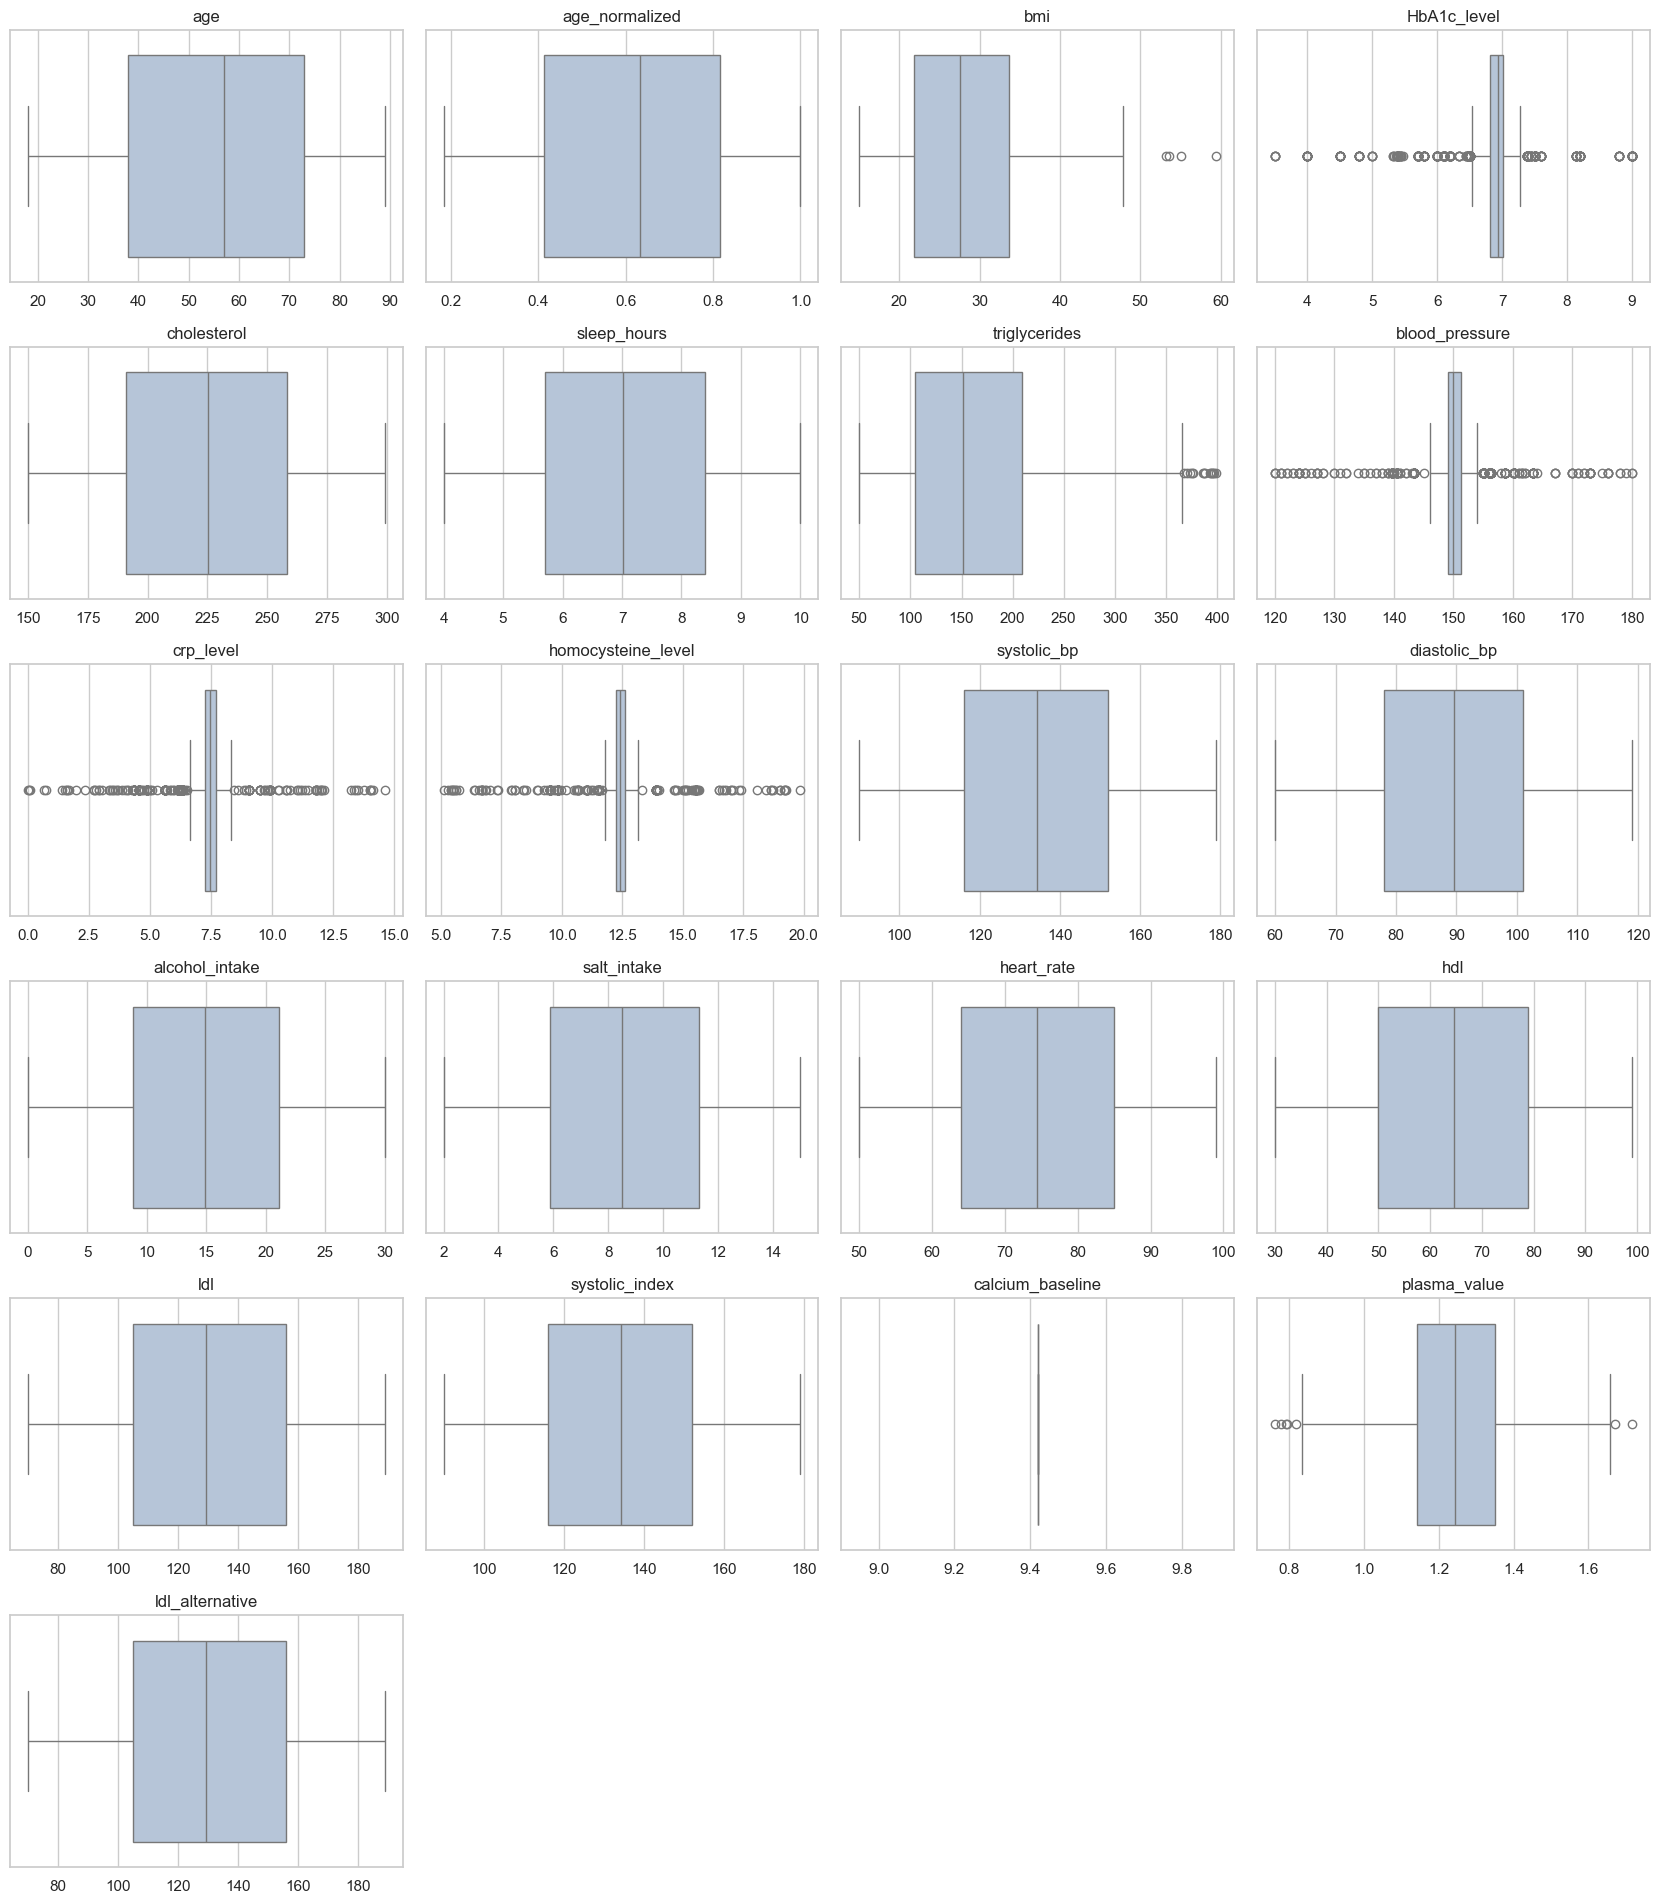

In [8]:
grid_plot(num_cols, 'box')

**Conclusions:** the distributions fall into four distinct patterns:

- **Approximately uniform**: `age`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`,
  `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` and `ldl`. These are almost "flat"
  distributions, with similar frequencies across the whole range.
- **Highly concentrated, with long tails**: `HbA1c_level`, `blood_pressure`, `crp_level` and
  `homocysteine_level`. They confirm the high kurtosis observed in 1.3.
- **Positively skewed**: `bmi` and `triglycerides`.
- **Approximately normal**: `plasma_value`.
- **Constant**: `calcium_baseline`, which appears as a single bar.

### 2.3 Outlier detection

The interquartile range rule flags as an *outlier* any observation lying more than 1.5 × IQR below the
first quartile or above the third. It is the criterion implicit in the *boxplots* of the previous
section.

We apply it to every numeric variable in order to quantify the number of **outliers**.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({'n_outliers': {c: iqr_outliers(df[c]) for c in num_cols + [TARGET_REG]}})
out['%'] = out['n_outliers'] / len(df) * 100
out.sort_values('n_outliers', ascending=False)

,n_outliers,%
HbA1c_level,372,18.600
crp_level,228,11.400
blood_pressure,212,10.600
homocysteine_level,170,8.500
target_regression,18,0.900
triglycerides,14,0.700
plasma_value,7,0.350
bmi,4,0.200
heart_rate,0,0.000
ldl_alternative,0,0.000


**Conclusions:**
The *outliers* are concentrated in the leptokurtic features. Because the IQR of these variables is very
narrow, the 1.5 × IQR rule flags as *outliers* many values that are clinically plausible (for example
an HbA1c of 5.4%). For that reason **we do not remove them automatically**. In section 3 we will see
that, in the case of `HbA1c_level`, these "extreme" values are associated with a specific class (`HT`)
and are informative.

### 2.4 Categorical features

The univariate analysis of the ***categorical features*** is developed in section 1.4.

## 3. Bivariate analysis

### 3.1 Correlation between numeric features

We now move on to studying **relationships between pairs of variables**. We start with the correlation
matrix between the numeric *features*, which serves two distinct purposes:

- **detecting redundancy** - pairs with a correlation close to 1 carry the same information;
- **anticipating collinearity problems** in multiple regression.

We compute both **Pearson** and **Spearman** correlations. We exclude `calcium_baseline`, whose
correlation is undefined because it has zero variance.

We include **both target variables** in the matrix. `target_regression` enters directly, since it is
continuous. `target_class` is categorical, so it enters as three binary indicators, one per class. The
correlation between a continuous variable and a binary indicator is the **point-biserial
correlation**, which is interpreted in the same way. The matrix therefore also shows how much each
*feature* relates to each of the targets, and the two targets to each other.

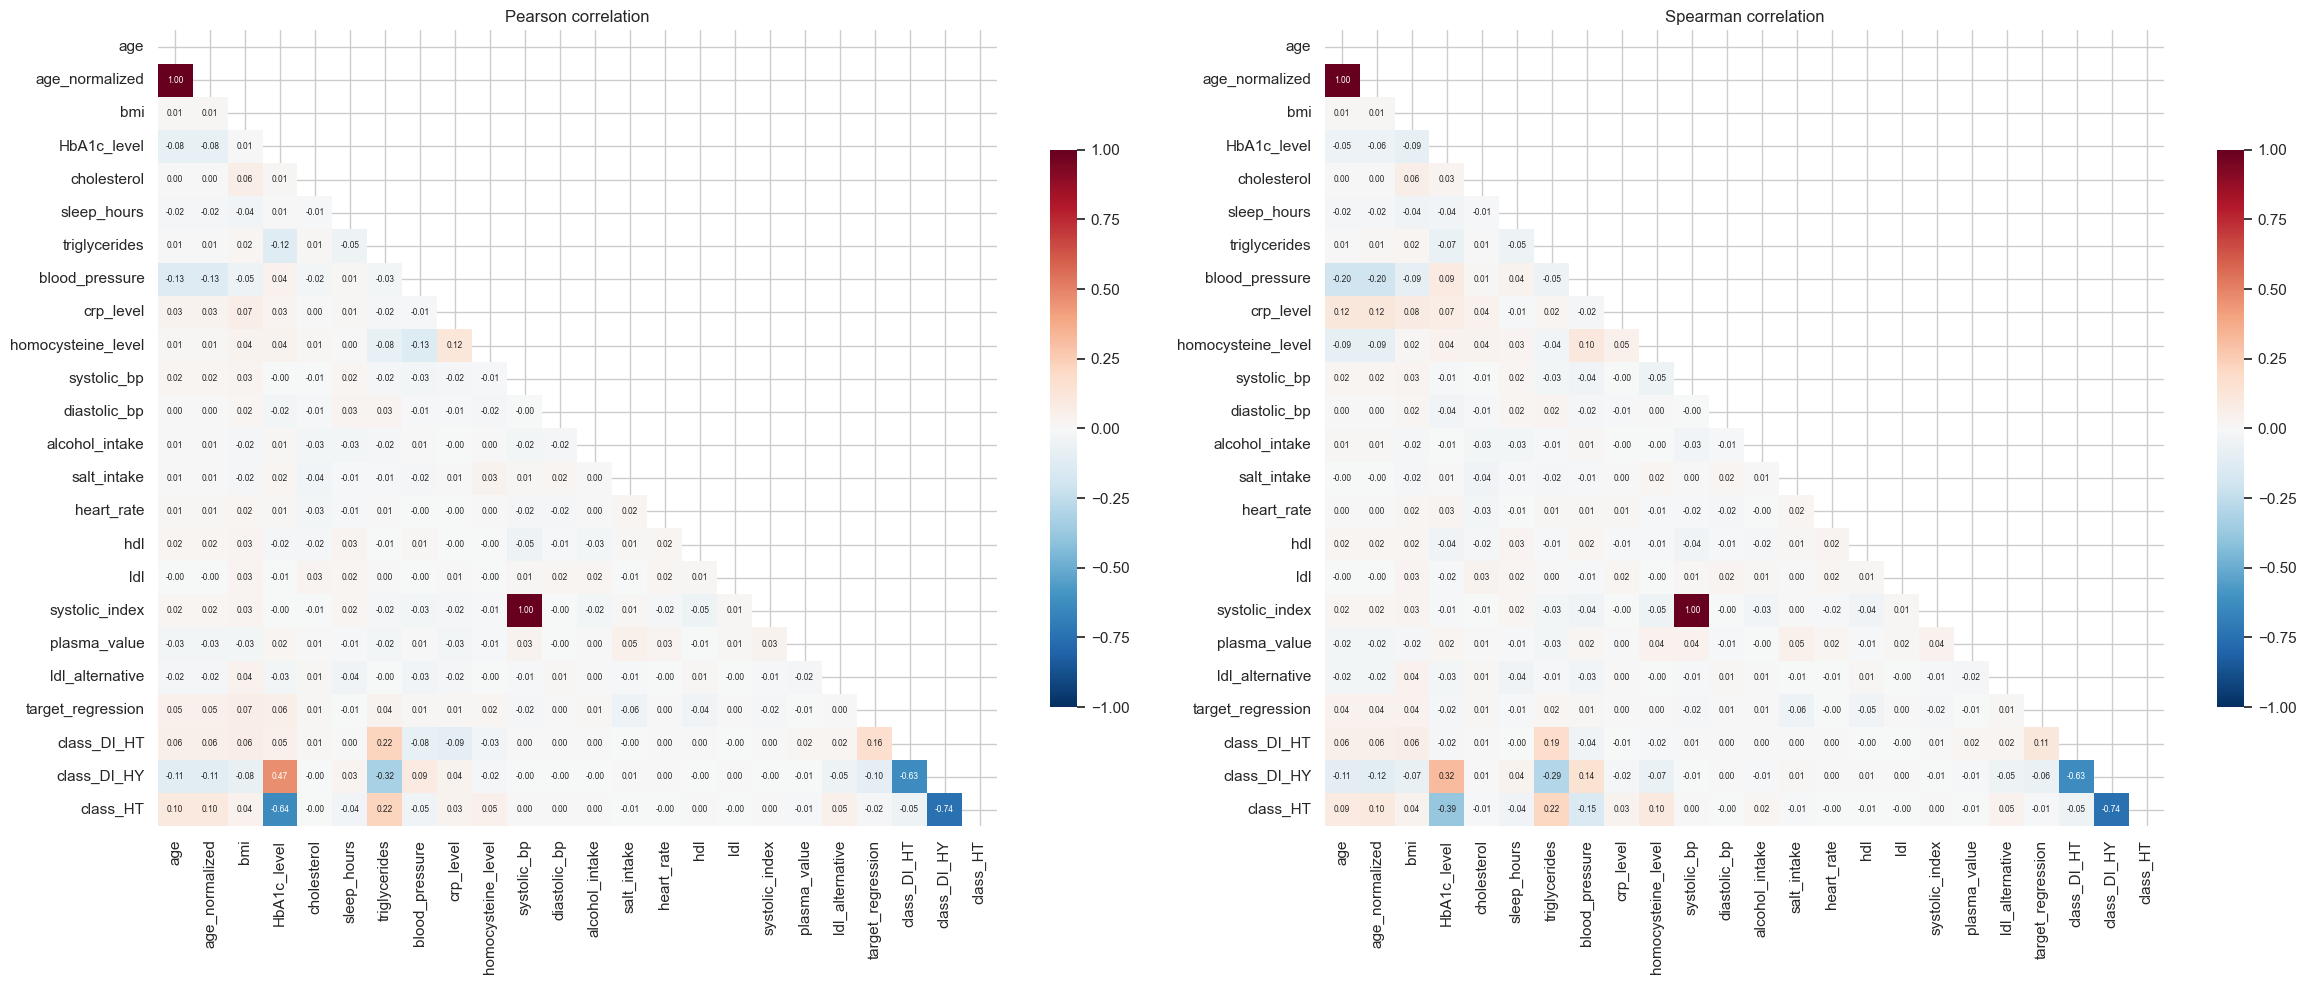

In [10]:
# Binary indicators of target_class, so that the relationship of each numeric
# variable with the classes can be read in the same matrix (point-biserial correlation)
class_indicators = pd.get_dummies(df[TARGET_CLS], prefix='class').astype(int)

corr_base = pd.concat([df[num_cols].drop(columns='calcium_baseline'),
                       df[[TARGET_REG]], class_indicators], axis=1)

corr_p = corr_base.corr(method='pearson')
corr_s = corr_base.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, m, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1,
                center=0, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax,
                cbar_kws={'shrink': .7})
    ax.set_title(f'{t} correlation')
plt.tight_layout(); plt.show()

In [11]:
upper = corr_p.where(np.triu(np.ones(corr_p.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > 0.3].sort_values(key=abs, ascending=False).to_frame('pearson')
high_pairs

,,pearson
systolic_bp,systolic_index,1.000
age,age_normalized,1.000
class_DI_HY,class_HT,-0.744
HbA1c_level,class_HT,-0.640
class_DI_HT,class_DI_HY,-0.629
HbA1c_level,class_DI_HY,0.466
triglycerides,class_DI_HY,-0.323


**Conclusions:** only **two pairs** of *features* show a high correlation, `age` with `age_normalized`
and `systolic_bp` with `systolic_index`, in both cases with a correlation equal or practically equal
to 1.

Outside these two pairs, **the correlations between *features* are practically null**, almost all of
them below 0.05 in absolute value.

As for the targets, the reading is quite asymmetric. No *feature* exceeds |r| = 0.07 with
`target_regression`, which anticipates how difficult the regression task will be. With the indicators
of `target_class`, on the other hand, clearly larger values appear, with `HbA1c_level` reaching
|r| = 0.64 and `triglycerides` 0.32, which indicates there is usable signal for classification.

The two targets show a moderate correlation with each other, with |r| = 0.16 between
`target_regression` and the indicator of class `DI_HT`. The relationship exists but is weak, and is
quantified appropriately in section 3.5.

### 3.2 Empirical confirmation of redundancy

The correlation matrix **suggests** redundancy, but does not prove it. Two variables can have a
correlation of 1 and not be the same column, and can have a correlation of 0 and still be related.
Before removing any *feature* we need to verify exactly **what kind of relationship** exists.

We test three hypotheses:
- whether `age_normalized` is a monotone transformation of `age`;
- whether `systolic_index` is an exact row-by-row copy of `systolic_bp`;
- and whether `ldl_alternative` contains the same values as `ldl` in a different order.

To close the section, we measure the joint effect of the redundancy on the data matrix.

In [12]:
print('--- age vs age_normalized ---')
print('  Spearman:', round(stats.spearmanr(df.age, df.age_normalized)[0], 6))
print('  Pearson :', round(df.age.corr(df.age_normalized), 6))
expected = (df.age - 2) / 87
print('  formula (age - 2) / 87 -> maximum residual:',
      f'{float((df.age_normalized - expected).abs().max()):.2e}')

print('\n--- systolic_bp vs systolic_index ---')
print('  equal on every row:', (df.systolic_bp == df.systolic_index).all())

print('\n--- ldl vs ldl_alternative ---')
print('  same set of values (sorted):',
      np.allclose(np.sort(df.ldl), np.sort(df.ldl_alternative)))
print('  rows where they match:', int(df.ldl.eq(df.ldl_alternative).sum()), 'of', len(df))
print('  Pearson correlation:', round(df.ldl.corr(df.ldl_alternative), 4))

--- age vs age_normalized ---
  Spearman: 0.999951
  Pearson : 1.0
  formula (age - 2) / 87 -> maximum residual: 9.89e-07

--- systolic_bp vs systolic_index ---
  equal on every row: True

--- ldl vs ldl_alternative ---
  same set of values (sorted): True
  rows where they match: 18 of 2000
  Pearson correlation: -0.0049


**Conclusions:**

- **`age_normalized` is a deterministic rescaling of `age`.** **It is redundant**: the two columns
  carry literally the same information, so it is enough to keep `age`.
- **`systolic_index` is an exact copy of `systolic_bp`**, equal on all 2000 rows. The vague definition
  in the assignment ("secondary index capturing haemodynamic pressure dynamics") corresponds to nothing
  new in the data. **It is redundant.**
- `ldl_alternative` has exactly the same set of values as `ldl`, but matches it on only 18 of the 2000
  rows, and the correlation between the two is practically null. This is consistent with a **random
  permutation of the rows of `ldl`**, meaning the column has the right distribution but each patient's
  value does not belong to them.

There is still a fourth check to make, of a different nature. The three above look at pairs of columns;
this one measures the **joint** effect of the redundancy on the data matrix.

We use two measures. The **condition number** of the standardized matrix grows as the columns become
linearly dependent, and serves as a global alarm. The **VIF**, or variance inflation factor, tells us,
for each variable, how many times the variance of its coefficient is inflated by collinearity with the
others, and is obtained from the diagonal of the inverse correlation matrix. A VIF of 1 means a
complete absence of collinearity.

In [13]:
def condition_number(data):
    """Condition number of the standardized matrix: grows with collinearity."""
    standardized = (data - data.mean()) / data.std()
    return float(np.linalg.cond(standardized.values))

def vif_of_columns(data):
    """VIF of each column, from the diagonal of the inverse correlation matrix."""
    R = np.corrcoef(data.values, rowvar=False)
    if np.linalg.matrix_rank(R) < R.shape[0]:
        return None          # there is an exact dependency, the inverse does not exist
    return pd.Series(np.diag(np.linalg.inv(R)), index=data.columns)

REDUNDANT = ['age_normalized', 'systolic_index', 'ldl_alternative']
num_without_constant = [c for c in num_cols if c != 'calcium_baseline']   # zero variance
before = df[num_without_constant]
after = df[[c for c in num_without_constant if c not in REDUNDANT]]

R_before = np.corrcoef(before.values, rowvar=False)
print(f'With the redundant columns ({before.shape[1]} variables):')
print(f'  rank of the correlation matrix: {np.linalg.matrix_rank(R_before)} of {before.shape[1]}')
print(f'  condition number: {condition_number(before):.3g}')
print(f'  VIF computable: {vif_of_columns(before) is not None}')

print('\nVIF of each suspect pair, computed pairwise:')
for a, b in [('age', 'age_normalized'), ('systolic_bp', 'systolic_index'),
             ('ldl', 'ldl_alternative')]:
    r = df[a].corr(df[b])
    print(f'  {a:12} vs {b:16} r = {r: .6f}  ->  VIF = {1 / (1 - r ** 2):.6g}')

print(f'\nWithout the redundant columns ({after.shape[1]} variables):')
print(f'  condition number: {condition_number(after):.3g}')
vif_after = vif_of_columns(after).sort_values(ascending=False)
print(f'  max VIF: {vif_after.max():.4f}'
      f'  |  all below 1.05: {bool((vif_after < 1.05).all())}')
vif_after.round(4).to_frame('VIF').T

With the redundant columns (20 variables):
  rank of the correlation matrix: 19 of 20
  condition number: 1.75e+15
  VIF computable: False

VIF of each suspect pair, computed pairwise:
  age          vs age_normalized   r =  1.000000  ->  VIF = 5.08766e+11
  systolic_bp  vs systolic_index   r =  1.000000  ->  VIF = 4.5036e+15
  ldl          vs ldl_alternative  r = -0.004942  ->  VIF = 1.00002

Without the redundant columns (17 variables):
  condition number: 1.29
  max VIF: 1.0441  |  all below 1.05: True


,homocysteine_level,blood_pressure,triglycerides,HbA1c_level,age,crp_level,bmi,cholesterol,sleep_hours,systolic_bp,plasma_value,hdl,salt_intake,alcohol_intake,diastolic_bp,heart_rate,ldl
VIF,1.044,1.041,1.027,1.026,1.025,1.023,1.019,1.010,1.008,1.008,1.008,1.007,1.007,1.005,1.005,1.004,1.004


**Conclusions:**

With the twenty original numeric columns, the correlation matrix has **rank 19 out of 20**. It is
missing a dimension, which means there is an **exact linear dependency** between columns. The matrix is
therefore not invertible and **the VIF cannot even be computed**. The condition number, 1.75e+15,
confirms the diagnosis: values above 30 are already considered problematic.

Computed pairwise, the suspect pairs separate clearly:

- `age` and `age_normalized`, with a VIF of the order of 1e+11;
- `systolic_bp` and `systolic_index`, with a VIF of the order of 1e+15, because they are exactly equal;
- `ldl` and `ldl_alternative`, with a **VIF of 1.00002**, that is, no collinearity at all.

This last result is important and deserves careful reading. **`ldl_alternative` is not removed because
of collinearity**, unlike the other two. Its problem is a different one and was demonstrated above: it
contains the values of `ldl` in another order, so the value appearing in each row does not belong to
that patient.

Once the three columns are removed, the picture changes completely. The condition number falls from
1.75e+15 to **1.29**, and **all the VIF values stay below 1.05**, with the maximum at 1.0441
(`homocysteine_level`). There is no multicollinearity whatsoever between the retained variables.

This has a practical consequence for Part 4 of this assignment: the reason for being of **Ridge** is to
stabilize coefficients when the predictors are correlated, and here there is nothing to stabilize. It
is predictable that Ridge will bring no gain over an unregularized solution, and this is the evidence
that allows us to say so.

### 3.3 Consistency between derived features and their source variables

The assignment states that `age_level` and `bmi_level` are categories derived from `age` and `bmi`.
Judging by their names, `low_hdl_cholesterol` and `high_ldl_cholesterol` are *flags* built from `hdl`
and `ldl`.

It is worth checking whether that correspondence holds in the data. We compare each *flag* against the
usual clinical threshold (HDL < 40 and LDL ≥ 130) to assess how sharp it is.

We add a fifth panel that serves a different purpose. If `high_ldl_cholesterol` was built from the
patient's LDL values, then it must relate to `ldl`, but it has no reason to relate to
`ldl_alternative` if the latter is, as section 3.2 suggests, a random permutation of the rows.
Comparing the two panels side by side is a direct test of that hypothesis.

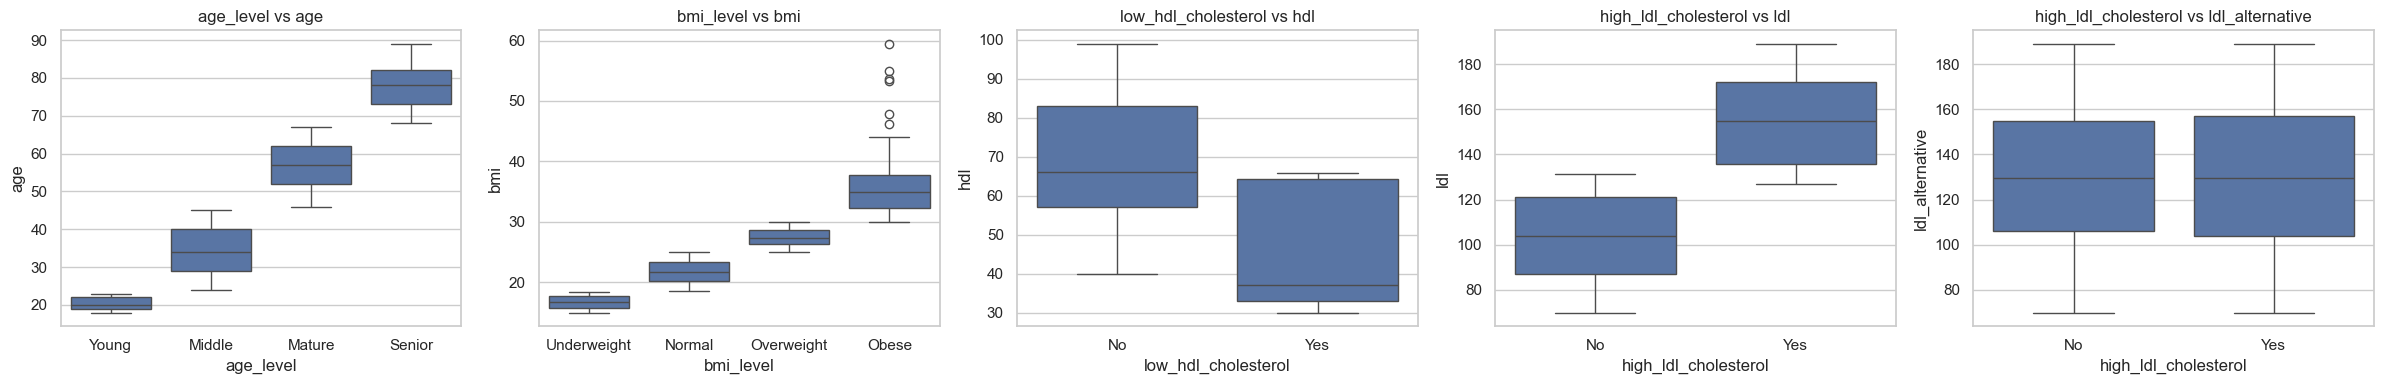

hdl < 40             False  True 
low_hdl_cholesterol              
No                    1647      0
Yes                    105    248

ldl >= 130            False  True 
high_ldl_cholesterol              
No                      940     38
Yes                     116    906

ldl_alternative >= 130  False  True 
high_ldl_cholesterol                
No                        521    457
Yes                       535    487

ldl              mean No= 103.56  Yes= 155.01

ldl_alternative  mean No= 129.73  Yes= 129.97


In [14]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
sns.boxplot(data=df, x='age_level', y='age',
            order=['Young','Middle','Mature','Senior'], ax=axes[0])
sns.boxplot(data=df, x='bmi_level', y='bmi',
            order=['Underweight','Normal','Overweight','Obese'], ax=axes[1])
sns.boxplot(data=df, x='low_hdl_cholesterol', y='hdl', ax=axes[2])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl', ax=axes[3])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl_alternative', ax=axes[4])
for ax in axes: ax.set_title(f'{ax.get_xlabel()} vs {ax.get_ylabel()}')
plt.tight_layout(); plt.show()

print(pd.crosstab(df.low_hdl_cholesterol, df.hdl < 40, colnames=['hdl < 40']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl >= 130, colnames=['ldl >= 130']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl_alternative >= 130,
                  colnames=['ldl_alternative >= 130']))

for column in ('ldl', 'ldl_alternative'):
    groups = [df.loc[df.high_ldl_cholesterol == k, column] for k in ('No', 'Yes')]
    print(f'\n{column:16s} mean No={groups[0].mean():7.2f}  Yes={groups[1].mean():7.2f}')

**Conclusions:** `age_level` and `bmi_level` correspond to **sharp discretizations** of `age` and
`bmi`.

In the variables `low_hdl_cholesterol` and `high_ldl_cholesterol` there is some overlap, that is, the
threshold is not perfectly sharp, but the association is strong. The contingency table confirms it: of
the 1022 records marked `Yes` in `high_ldl_cholesterol`, 906 do in fact have `ldl` equal to or above
130.

**The fifth panel is the most relevant result of this section.** While `ldl` clearly separates the two
levels of the *flag*, with means of 103.6 and 155.0, `ldl_alternative` **shows no relationship with it
at all**. Its means are 129.7 and 130.0, that is, the two distributions are indistinguishable.

This is the independent confirmation that `ldl_alternative` **does not belong to the patient**. Since
it shows no relationship, it is demonstrated that its values are disconnected from the record in which
they appear, which makes it a candidate for removal and not merely a suspicious variable.

In either case, the four derived variables are **partially redundant** with their source variables. In
a linear model, the usual practice is to keep the continuous variable, which preserves more
information than its binned version.

### 3.4 Numeric features vs `target_regression`

This analysis will guide us in choosing the predictor for the simple linear regression and the set of
predictors for the multiple one.

We compute two complementary measures, so as not to depend on a single one:

- the **Pearson correlation**, which measures the strength of the **linear** relationship, the one
  that linear regression models can actually exploit;
- the **Spearman correlation**, which measures monotone relationships even if curved, and which serves
  to rule out the hypothesis of a strong but non-linear relationship that the Pearson coefficient
  would be underestimating.

We add the **p-value** of the Pearson test, which tests the null hypothesis of no relationship (β₁ = 0).

In [15]:
# Working set: excludes the constant feature and the two redundant ones confirmed in 3.2
num_feats = [c for c in num_cols
             if c not in ('calcium_baseline', 'age_normalized', 'systolic_index')]

rel_reg = pd.DataFrame({
    'pearson': [df[c].corr(df[TARGET_REG]) for c in num_feats],
    'spearman': [df[c].corr(df[TARGET_REG], method='spearman') for c in num_feats],
    'p_value_pearson': [stats.pearsonr(df[c], df[TARGET_REG])[1] for c in num_feats],
}, index=num_feats)
rel_reg = rel_reg.sort_values('pearson', key=abs, ascending=False)
rel_reg

,pearson,spearman,p_value_pearson
bmi,0.070,0.044,0.002
salt_intake,-0.062,-0.062,0.005
HbA1c_level,0.055,-0.023,0.013
age,0.054,0.043,0.017
hdl,-0.040,-0.046,0.074
triglycerides,0.037,0.019,0.096
systolic_bp,-0.018,-0.016,0.426
homocysteine_level,0.016,0.002,0.474
blood_pressure,0.015,0.011,0.509
cholesterol,0.011,0.011,0.616


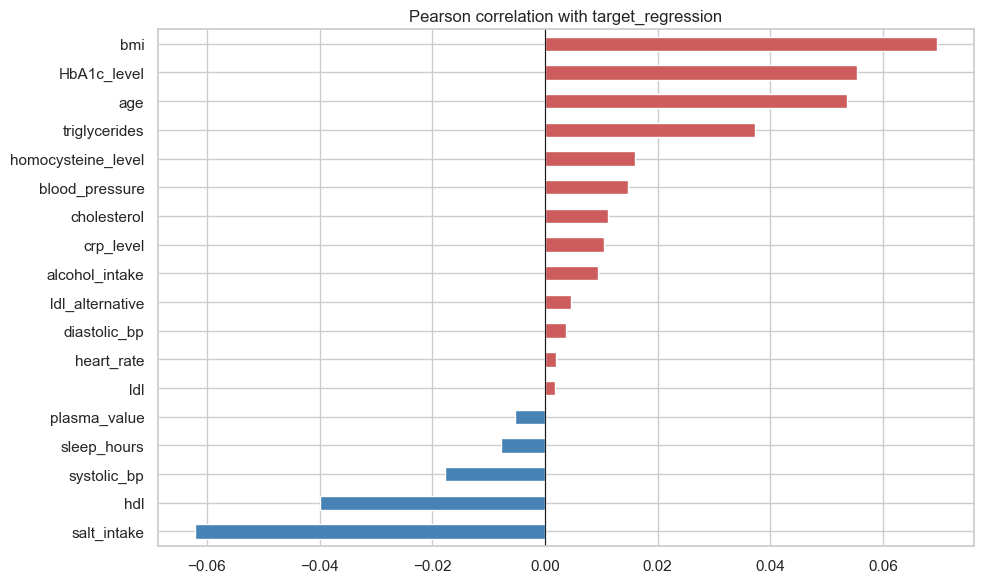

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
series = rel_reg['pearson'].sort_values()
series.plot.barh(ax=ax, color=np.where(series > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='k', lw=.8)
ax.set_title('Pearson correlation with target_regression')
plt.tight_layout(); plt.show()

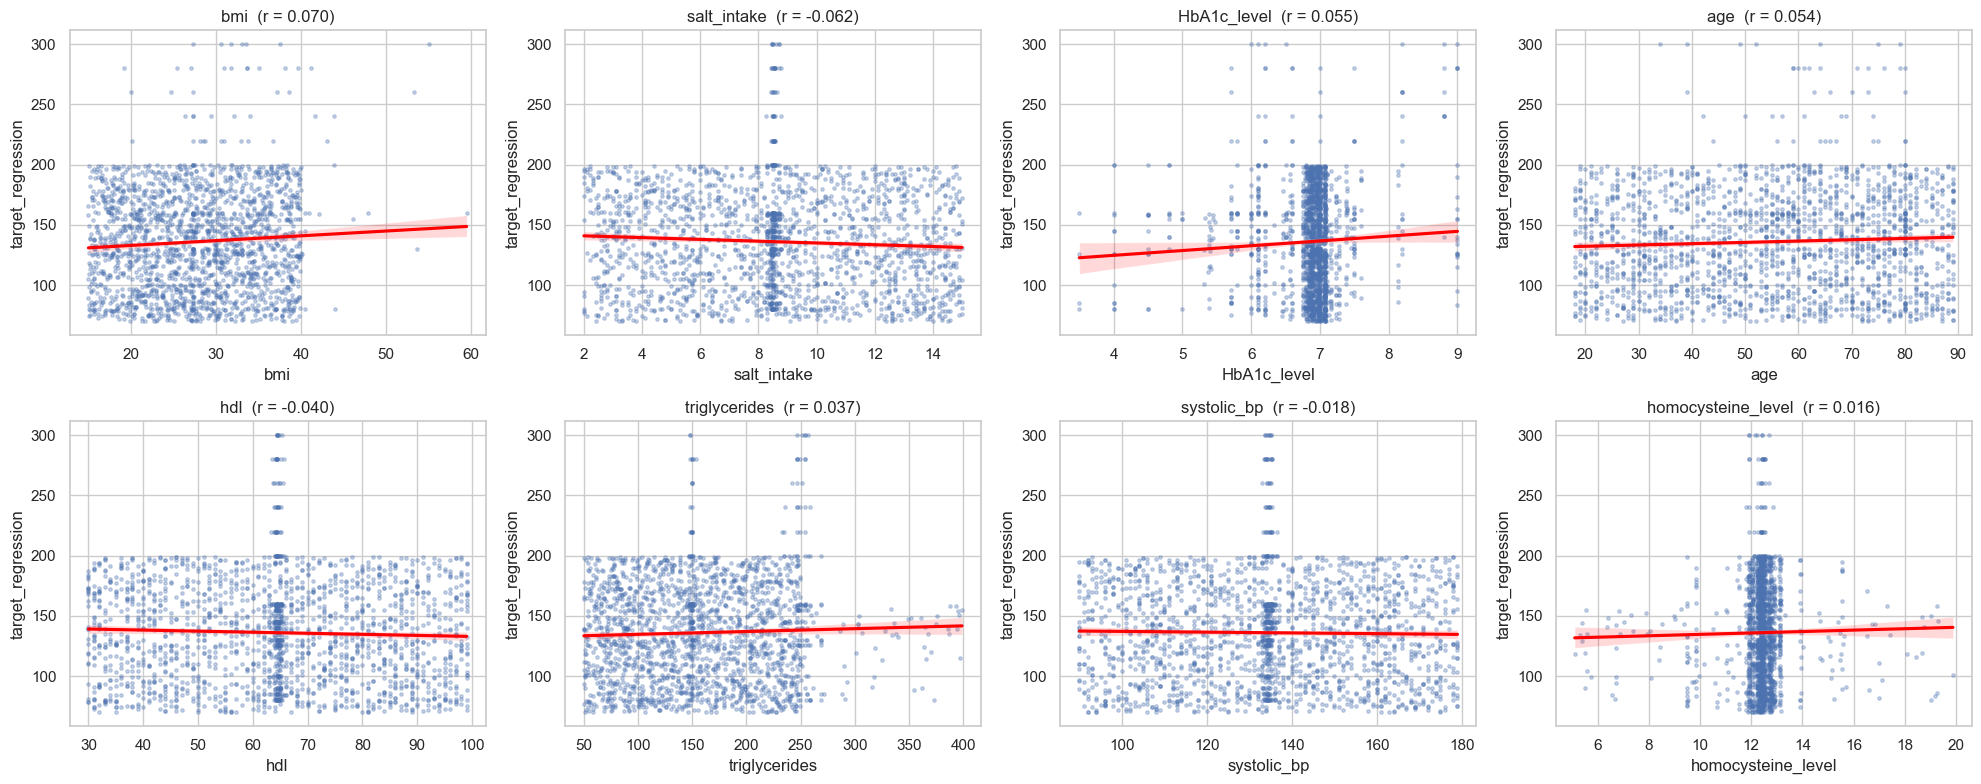

In [17]:
top = rel_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top):
    sns.regplot(data=df, x=c, y=TARGET_REG, ax=ax,
                scatter_kws={'s': 6, 'alpha': .3}, line_kws={'color': 'red'})
    ax.set_title(f'{c}  (r = {rel_reg.loc[c, "pearson"]:.3f})')
plt.tight_layout(); plt.show()

**Conclusions:**

**No numeric *feature* has a relevant linear relationship with `target_regression`.** The largest
absolute correlation is that of `bmi`, with r ≈ 0.070. It is followed by `salt_intake` (−0.062),
`HbA1c_level` (0.055) and `age` (0.054), which are statistically significant (p < 0.05) because of the
sample size (n = 2000). All the remaining ones are even closer to zero. In the fitted lines of the
scatter plots this is visible to the naked eye, the point clouds are practically horizontal.

The **Spearman correlations are very similar to the Pearson ones**, which rules out the hypothesis of a
strong but curved relationship that the Pearson coefficient was underestimating. The association is
genuinely weak, and not an artefact of how it was measured.

A **very low R²** is to be expected, both in simple and in multiple linear regression. The variable
with the largest effect on `target_regression` is, as we will see next, `target_class` itself. Since it
is the target of the other task, and not a target of this one, nothing prevents it from being used as a
predictor in the regression, and that is why we include it in these comparisons.

### 3.5 Categorical features vs `target_regression`

To assess the relationship between a categorical variable and a continuous one, we apply two tests:

- the **ANOVA** (F test), which is parametric and assumes normality and homogeneity of variances;
- the **Kruskal-Wallis**, which is the non-parametric alternative, based on ranks.

We also compute **η² (eta squared)**, which measures the **proportion of the variance** of
`target_regression` explained by each categorical variable. It is this effect-size measure, and not the
p-value, that tells us whether the variable is **practically** useful.

In [18]:
rows = []
for c in cat_cols + [TARGET_CLS]:
    groups = [g[TARGET_REG].values for _, g in df.groupby(c)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - df[TARGET_REG].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET_REG] - df[TARGET_REG].mean())**2).sum()
    rows.append({'feature': c, 'F_anova': F, 'p_anova': p_anova,
                 'p_kruskal': p_kw, 'eta2': eta2})
cat_reg = pd.DataFrame(rows).set_index('feature').sort_values('eta2', ascending=False)
cat_reg_show = cat_reg.copy()
for col in ['p_anova', 'p_kruskal']:
    cat_reg_show[col] = cat_reg_show[col].map('{:.3g}'.format)
cat_reg_show

,F_anova,p_anova,p_kruskal,eta2
feature,,,,
target_class,27.881,1.14e-12,5.31e-06,0.027
smoking,6.043,0.00242,0.00447,0.006
age_level,3.593,0.0131,0.0391,0.005
bmi_level,2.245,0.0812,0.33,0.003
physical_activity,3.068,0.0467,0.333,0.003
sugar_consumption,0.926,0.396,0.485,0.001
family_history,1.842,0.175,0.187,0.001
high_ldl_cholesterol,1.541,0.215,0.356,0.001
education_level,0.700,0.496,0.431,0.001


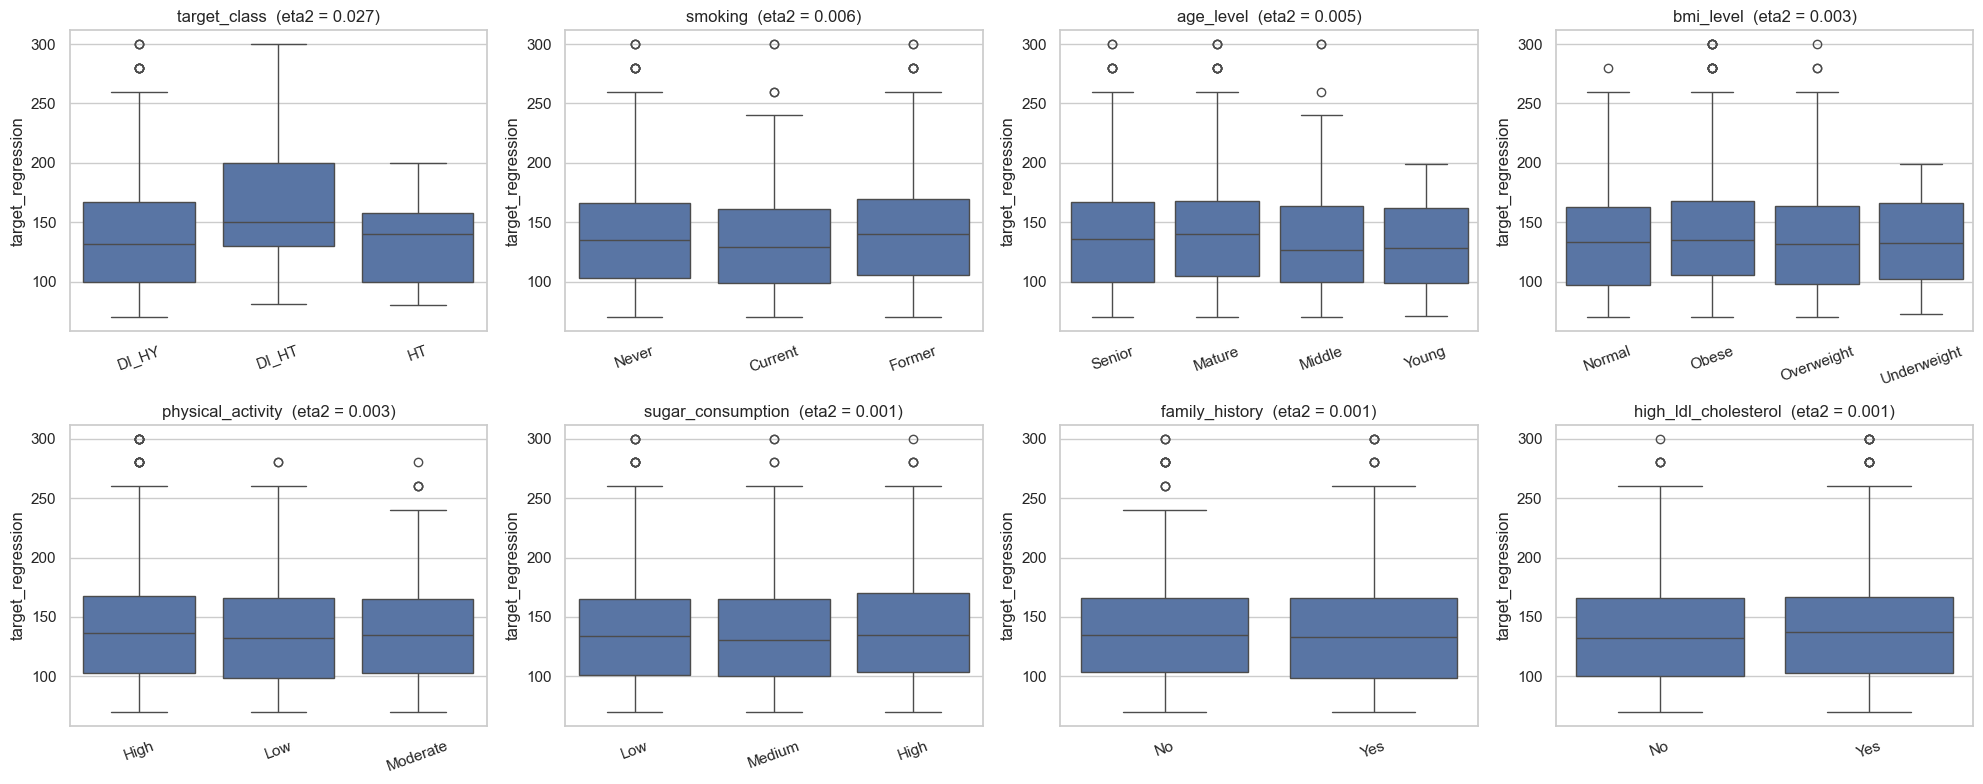

In [19]:
plot_cats = cat_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, plot_cats):
    sns.boxplot(data=df, x=c, y=TARGET_REG, ax=ax)
    ax.set_title(f'{c}  (eta2 = {cat_reg.loc[c, "eta2"]:.3f})')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Conclusions:** the categorical variable with the largest effect on `target_regression` is
**`target_class`** itself, with η² = 0.027 and p ≈ 1e-12 in the ANOVA. The effect is small, but it is
the largest of all, and, since it is the target of the other task and not a target of this one, it can
be used as a predictor in the regression. That is why we include it in this comparison.

All the remaining categorical variables have a **practically null η²** (≤ 0.006, with `smoking` as the
largest of them). Some do reach a p-value below 0.05, but without any practical relevance.

This confirms the diagnosis of the previous section: the available *features* explain practically
nothing of the variability of `target_regression`.

### 3.6 Numeric features vs `target_class`

We use the **Kruskal-Wallis test** to compare the distribution of each *feature* across the three
classes. We choose the non-parametric version because, as we have seen, the distributions are far from
normal and the classes have very different sizes.

We add **η²** as an effect-size measure, which indicates the proportion of the variance of each
*feature* explained by the class.

We also include `target_regression` in the list of variables tested. Being the target of the other task,
and not a target of this one, it can be used as a predictor in the classification, so it is of interest
to know how much the continuous target relates to the categorical one, symmetrically to what was done in
section 3.5.

In [20]:
classes = df[TARGET_CLS].value_counts().index.tolist()
rows = []
for c in num_feats + [TARGET_REG]:
    groups = [df.loc[df[TARGET_CLS] == k, c] for k in classes]
    H, p = stats.kruskal(*groups)
    ss_b = sum(len(g) * (g.mean() - df[c].mean())**2 for g in groups)
    eta2 = ss_b / ((df[c] - df[c].mean())**2).sum()
    rows.append({'feature': c, **{f'mean_{k}': g.mean() for k, g in zip(classes, groups)},
                 'kruskal_H': H, 'p_value': p, 'eta2': eta2})
num_cls = pd.DataFrame(rows).set_index('feature')
num_cls = num_cls.sort_values('eta2', ascending=False)
num_cls_show = num_cls.copy()
num_cls_show['p_value'] = num_cls_show['p_value'].map('{:.3g}'.format)
num_cls_show

,mean_DI_HY,mean_HT,mean_DI_HT,kruskal_H,p_value,eta2
feature,,,,,,
HbA1c_level,6.936,5.374,6.979,307.152,2.01e-67,0.410
triglycerides,151.159,217.040,227.074,170.839,7.99e-38,0.105
target_regression,134.676,132.812,168.190,24.290,5.31e-06,0.027
age,54.419,63.060,60.706,23.972,6.23e-06,0.013
crp_level,7.390,7.514,6.881,2.422,0.298,0.010
blood_pressure,150.299,149.190,148.195,48.963,2.33e-11,0.009
bmi,27.623,29.051,29.987,11.401,0.00334,0.006
homocysteine_level,12.373,12.606,12.194,20.806,3.03e-05,0.004
ldl_alternative,129.270,136.217,133.376,5.109,0.0777,0.003


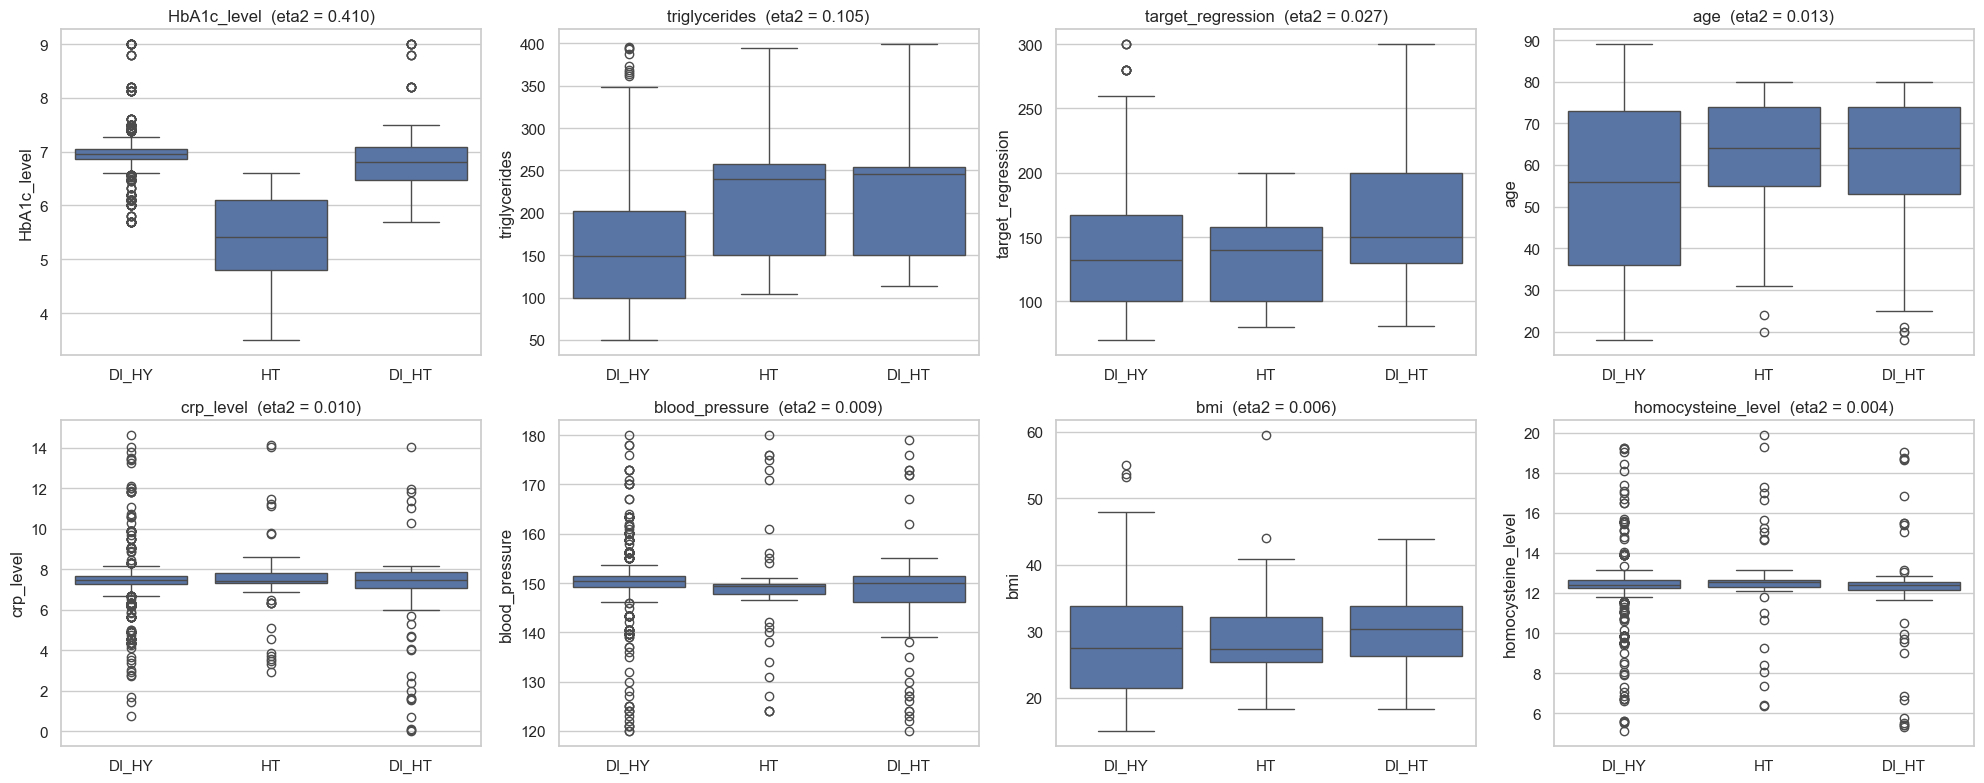

In [21]:
top_cls = num_cls.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_cls):
    sns.boxplot(data=df, x=TARGET_CLS, y=c, order=classes, ax=ax)
    ax.set_title(f'{c}  (eta2 = {num_cls.loc[c, "eta2"]:.3f})'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

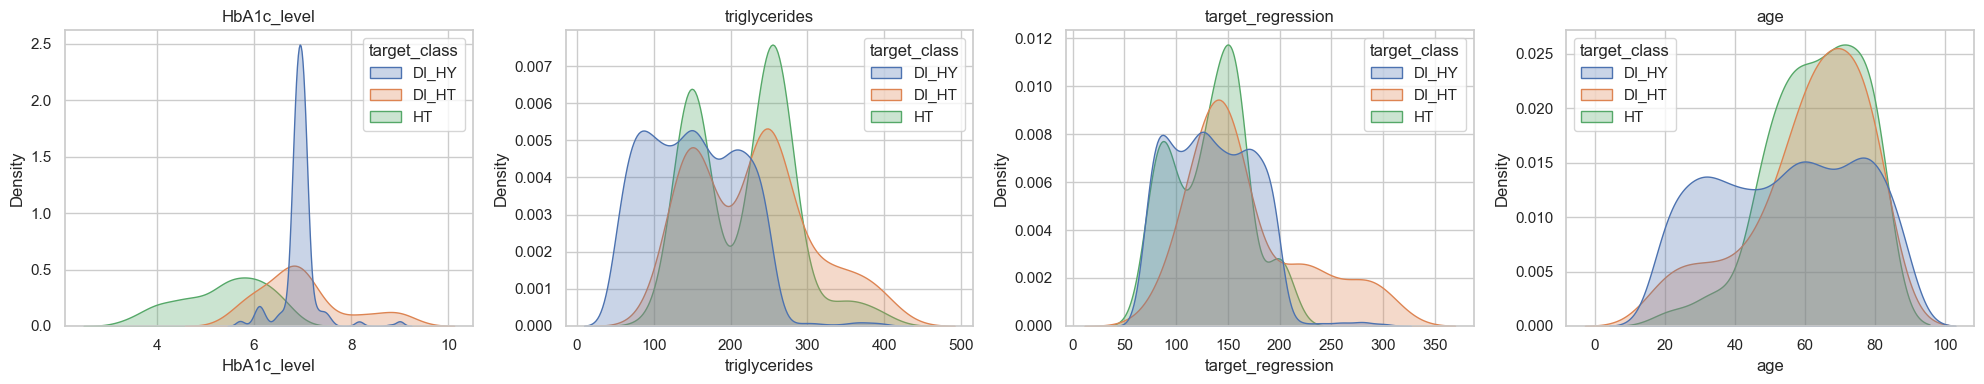

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, num_cls.index[:4]):
    sns.kdeplot(data=df, x=c, hue=TARGET_CLS, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Conclusions:**

Ordered by effect size, the following stand out:

- **`HbA1c_level` (η² = 0.41, Kruskal-Wallis H = 307, p ≈ 2e-67)** is the most discriminative
  *feature*, explaining about **41% of the variance** of its own distribution across classes. This
  makes clinical sense, because `HbA1c` is the marker of diabetes and `HT` is the only class without a
  diabetic component. It is the feature that best separates `HT` from the others.
- **`triglycerides` (η² = 0.105, p ≈ 8e-38)**: substantially higher values in `DI_HT` (≈ 227) and `HT`
  (≈ 217) than in `DI_HY` (≈ 151).
- With much smaller but still statistically detectable effects: `age` (η² = 0.013), `blood_pressure`
  (0.009), `bmi` (0.006) and `homocysteine_level` (0.004).
- **Only 6 of the 18 numeric *features*** show significant differences between classes. The remaining
  ones, including `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake` and
  `salt_intake`, have practically identical distributions across the three classes and are, from the
  point of view of their clinical value, **uninformative**.

- As for the continuous target variable, `target_regression` shows η² = 0.027, with p ≈ 5e-06. The
  relationship between the two targets is real but modest, and coincides with the value obtained in
  section 3.5, as would be expected since it is the same association measured from the other side.

### 3.7 Categorical features vs `target_class` (χ² and Cramér's V)

To measure the association between two categorical variables we use the **chi-squared test** on the
contingency table, which tests their independence.

The χ² has, however, a known limitation: its value grows with the sample size, so with n = 2000 almost
everything ends up being "significant". To measure the **strength** of the association we therefore use
**Cramér's V**, which normalizes the χ² to a value between 0 and 1 and is interpretable as an effect
size (values below 0.1 correspond to weak associations).

In [23]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), chi2, p

rows = []
for c in cat_cols:
    v, chi2, p = cramers_v(df[c], df[TARGET_CLS])
    rows.append({'feature': c, 'chi2': chi2, 'p_value': p, 'cramers_v': v})
cat_cls = pd.DataFrame(rows).set_index('feature').sort_values('cramers_v', ascending=False)
cat_cls_show = cat_cls.copy()
cat_cls_show['p_value'] = cat_cls_show['p_value'].map('{:.3g}'.format)
cat_cls_show

,chi2,p_value,cramers_v
feature,,,
low_hdl_cholesterol,31.042,1.82e-07,0.125
age_level,50.711,3.39e-09,0.113
bmi_level,46.506,2.35e-08,0.108
physical_activity,19.793,0.000549,0.070
education_level,15.257,0.0042,0.062
sugar_consumption,13.796,0.00797,0.059
employment_status,13.748,0.00814,0.059
smoking,13.380,0.00956,0.058
family_history,6.147,0.0462,0.055


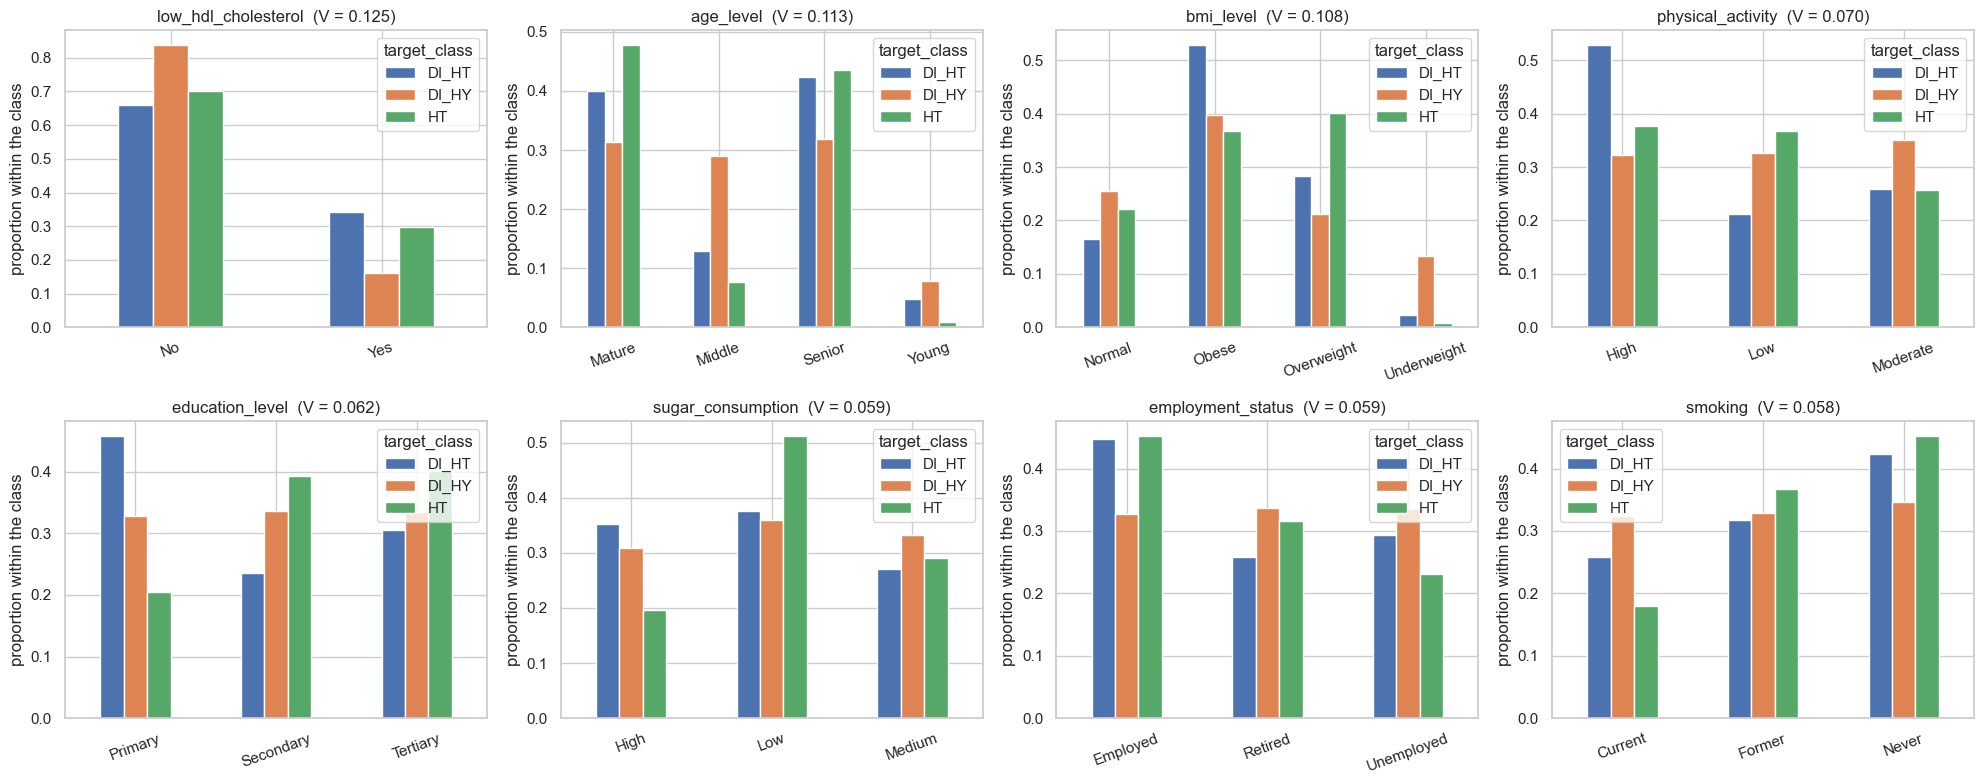

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cls.index[:8]):
    ct = pd.crosstab(df[c], df[TARGET_CLS], normalize='columns')   # profile of each class
    ct.plot.bar(ax=ax, rot=20)
    ax.set_title(f'{c}  (V = {cat_cls.loc[c, "cramers_v"]:.3f})')
    ax.set_xlabel(''); ax.set_ylabel('proportion within the class')
plt.tight_layout(); plt.show()

**Conclusions:** the strongest associations are those of `low_hdl_cholesterol`, `age_level` and
`bmi_level`, but **all of them are weak in absolute terms** (V = 0.125, 0.113 and 0.108 respectively).
`age_level` and `bmi_level` confirm the effect of `age` and `bmi` already detected in 3.6.

**`low_hdl_cholesterol` is associated with the class even though `hdl` is not.** A *flag* derived from
a variable without signal should not, in principle, carry signal.

Several variables, `physical_activity`, `education_level`, `smoking` and `employment_status`, have a
p-value below 0.05 but V ≈ 0.06. The pattern already seen repeats itself: with n = 2000, tiny effects
become statistically significant without having any **practical relevance**.

Finally, **`gender` and `stress_level` show no association at all** with the class (p > 0.2). They are
the two clearest candidates for uninformative *features* among the categorical ones.

### 3.8 Relationship between the two targets and pairplot of the most relevant features

We close the bivariate analysis with a joint view of the most promising *features*. The *pairplot*
shows, in one go, the distribution of each variable by class (on the diagonal) and all the pairwise
relationships (off the diagonal), with the points coloured by class.

The goal is to understand whether any **combination** of *features* separates the classes better than
any of them on its own.

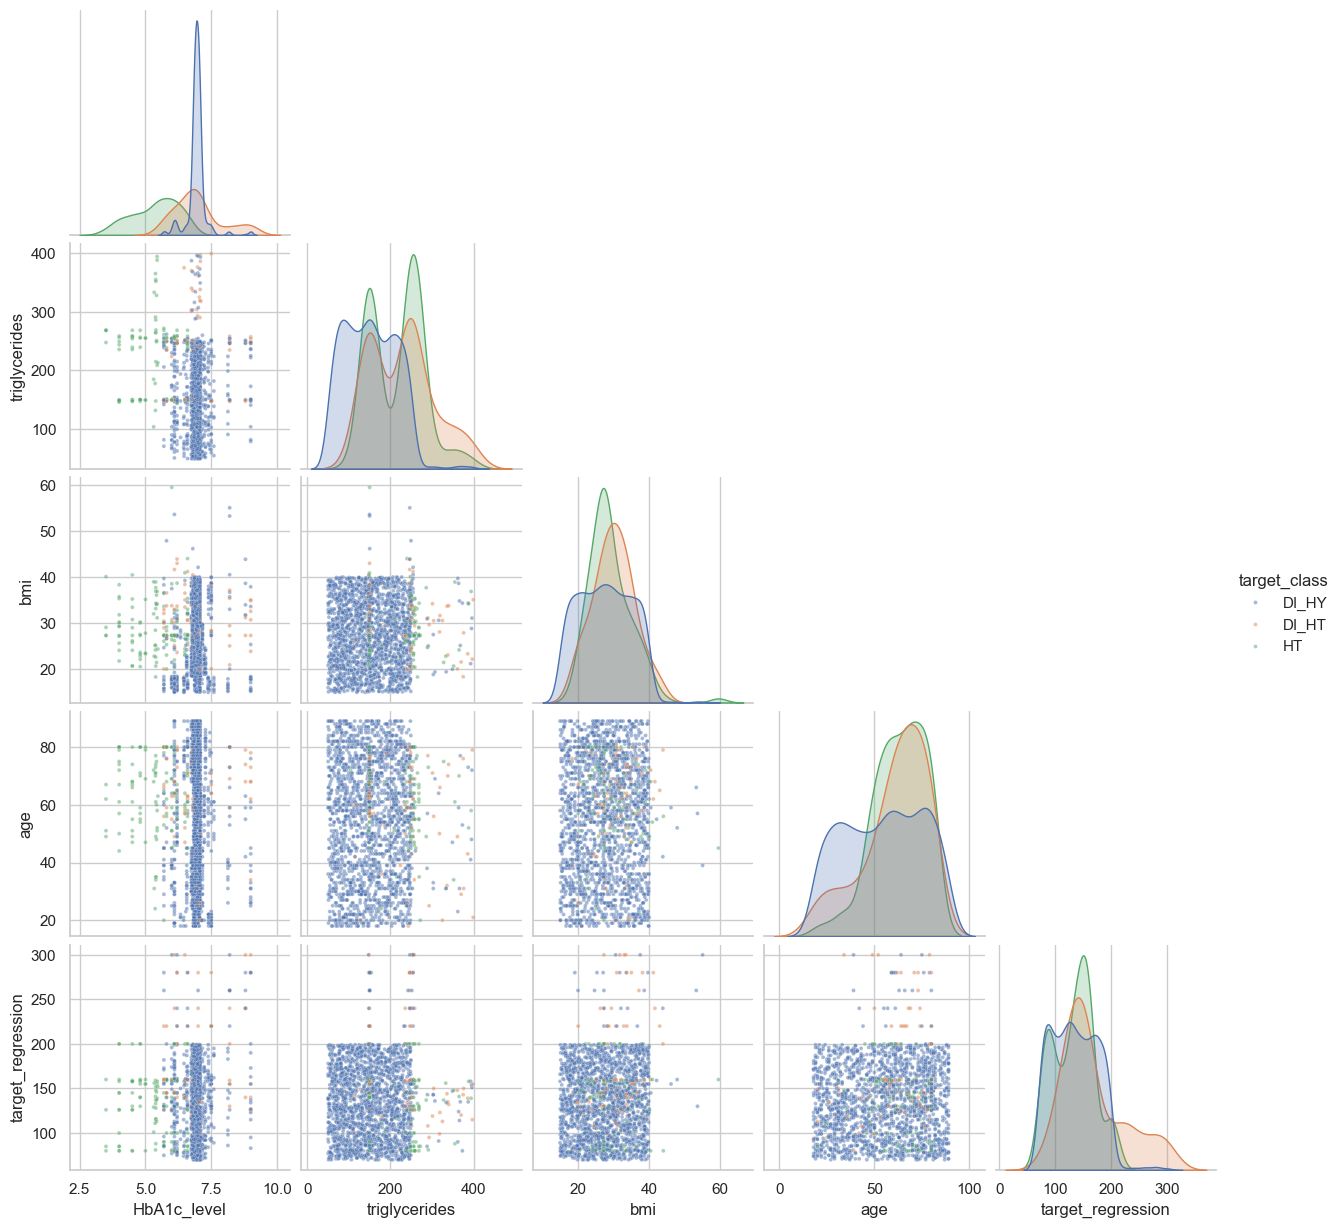

In [25]:
key = ['HbA1c_level', 'triglycerides', 'bmi', 'age', TARGET_REG]
sns.pairplot(df[key + [TARGET_CLS]], hue=TARGET_CLS, corner=True,
             plot_kws={'s': 8, 'alpha': .5}, diag_kws={'common_norm': False})
plt.show()

**Conclusions:** the *pairplot* confirms and enriches what we already knew, the *feature*
**`HbA1c_level` isolates class `HT` well**, forming a group clearly shifted to the left, and its
**combination with `triglycerides`** helps separate `DI_HT` and `HT` from `DI_HY`.

There remains, however, a **considerable overlap between `DI_HT` and `DI_HY`**. No combination of the
most relevant *features* distinguishes them sharply. It is predictable that this will be the hardest
distinction for the classifiers and the main source of error. Combining that with the fact that
`DI_HT` has only 85 records, it is to be expected that this will be the class with the worst *recall*.

### 3.9 Artefact detected: the decimal precision of the values depends on the class
Looking at the rows of the dataset, some values are "round" numbers (`hdl = 72.0`) and others have many
decimal places (`hdl = 64.3313679245283`), which suggests they were imputed or synthetically generated.
Let us check whether this is related to the class.

In [26]:
def not_rounded(s):
    return ((s * 10).round(6) % 1 != 0)

frac = pd.DataFrame({c: df.groupby(TARGET_CLS)[c].apply(lambda s: not_rounded(s).mean())
                     for c in num_feats}).T[classes]
frac.sort_values('DI_HY')

target_class,DI_HY,HT,DI_HT
age,0.000,0.000,0.000
cholesterol,0.031,0.812,0.671
triglycerides,0.031,0.812,0.671
bmi,0.049,0.923,0.953
systolic_bp,0.053,1.000,0.941
ldl,0.056,1.000,1.000
sleep_hours,0.056,1.000,1.000
hdl,0.056,1.000,1.000
heart_rate,0.056,1.000,1.000
salt_intake,0.056,1.000,1.000


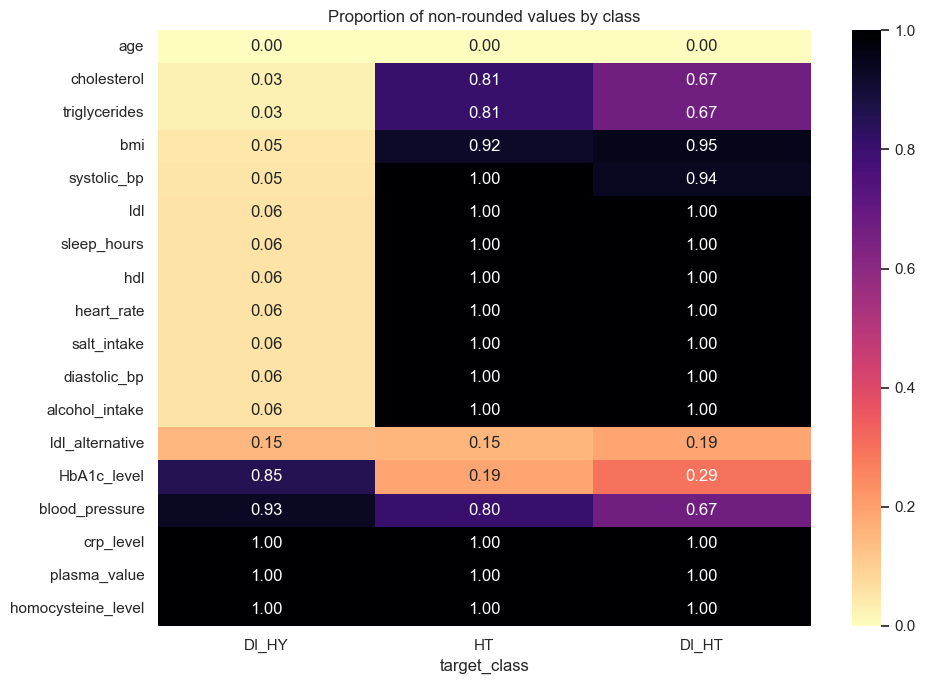

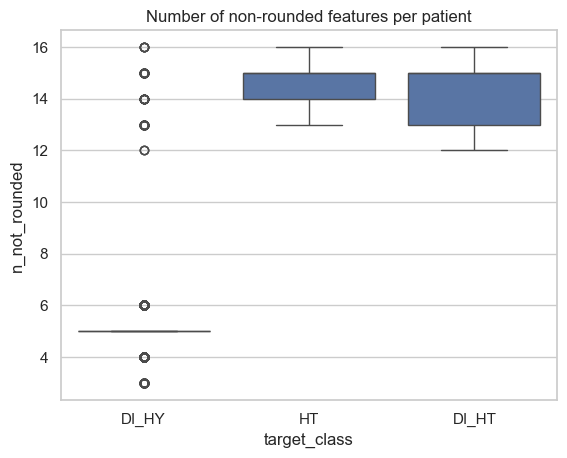

In [27]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(frac.sort_values('DI_HY'), annot=True, fmt='.2f', cmap='magma_r', ax=ax)
ax.set_title('Proportion of non-rounded values by class')
plt.tight_layout(); plt.show()

df_tmp = df.assign(n_not_rounded=sum(not_rounded(df[c]).astype(int) for c in num_feats))
sns.boxplot(data=df_tmp, x=TARGET_CLS, y='n_not_rounded', order=classes)
plt.title('Number of non-rounded features per patient'); plt.show()

**Conclusions:**

In the minority classes (`HT` and `DI_HT`), practically **100%** of the values of `hdl`, `heart_rate`,
`alcohol_intake`, `ldl`, `systolic_bp` and `bmi` have many decimal places. In the majority class
`DI_HY`, only about **5%** are in that situation. With `HbA1c_level` exactly the opposite happens.

This means that the records of the minority classes were **generated or imputed by a different
process** from the one used for the majority class.

**Implications, in order of importance:**

1. A flexible model can learn the class from the **"shape" of the number** rather than from its clinical value. This is *data leakage* and leads to optimistic performance that would not generalize to real data.
2. Linear models use the **value** of the variables and not their decimal representation, so they are little affected. Even so, **we should not create features derived from the precision**.
3. To assess relevance we use the Kruskal-Wallis tests with η², the χ² with Cramér's V and the correlations, which measure differences in the values of the variables and not in the way they are written.

## 4. Synthesis and preparation for the next stages

### 4.1 Summary table of the features

We gather in a single table the association measures computed throughout the bivariate analysis, in
order to back the decisions that follow with numbers.

In [28]:
summary = pd.DataFrame(index=num_feats + cat_cols)
summary['|r| target_reg'] = rel_reg['pearson'].abs()
summary['eta2 target_reg (cat)'] = cat_reg['eta2']
summary['eta2 target_class'] = num_cls['eta2']
summary['CramersV target_class'] = cat_cls['cramers_v']
summary['p target_class'] = num_cls['p_value'].combine_first(cat_cls['p_value'])
summary.sort_values('p target_class')

,|r| target_reg,eta2 target_reg (cat),eta2 target_class,CramersV target_class,p target_class
HbA1c_level,0.055,NaN,0.410,NaN,0.000
triglycerides,0.037,NaN,0.105,NaN,0.000
blood_pressure,0.015,NaN,0.009,NaN,0.000
age_level,NaN,0.005,NaN,0.113,0.000
bmi_level,NaN,0.003,NaN,0.108,0.000
low_hdl_cholesterol,NaN,0.001,NaN,0.125,0.000
age,0.054,NaN,0.013,NaN,0.000
homocysteine_level,0.016,NaN,0.004,NaN,0.000
physical_activity,NaN,0.003,NaN,0.070,0.001
bmi,0.070,NaN,0.006,NaN,0.003


### 4.2 Constant, redundant and uninformative features

| Type | Feature(s) | Justification (with evidence) | Proposed action |
|---|---|---|---|
| **Constant** | `calcium_baseline` | Single value (9.42) across 2000 records; standard deviation exactly 0 (section 1.3) | **Remove** |
| **Redundant** | `systolic_index` | Identical to `systolic_bp` on all 2000 rows. With both present, the correlation matrix becomes singular and the condition number reaches 1.75e+15 (section 3.2) | **Remove**, keep `systolic_bp` |
| **Redundant** | `age_normalized` | Deterministic rescaling of `age`: (age − 2)/87, maximum residual 1e-06 | **Remove**, keep `age` |
| **No link to the patient** | `ldl_alternative` | Has the same values as `ldl` but permuted, matching on only 18 of 2000 rows (3.2). Shows no relationship with `high_ldl_cholesterol`, the *flag* built from the patient's lipid profile: means of 129.7 and 130.0 | **Remove** |
| **Partially redundant** | `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | Discretizations of `age`, `bmi`, `hdl`, `ldl`. The two *flags* do not match the usual clinical thresholds | Prefer the continuous variable; **test during feature selection** |
| **Uninformative** | `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake`, `salt_intake`, `sleep_hours`, `cholesterol`, `plasma_value`, `crp_level`; and the categorical `gender` and `stress_level` | Identical distributions across classes (non-significant Kruskal-Wallis, η² ≈ 0) or no association (Cramér's V, p > 0.2); correlation ≈ 0 with `target_regression` | **Keep at this stage**; the decision belongs to feature selection |
| **Informative** | `HbA1c_level`, `triglycerides`, `bmi`/`bmi_level`, `age`/`age_level` | Clear differences between classes: η² = 0.41 and 0.105 for the first two, with p ≈ 2e-67 and 8e-38 | **Keep** |

**Criterion adopted.** Only the four variables for which there is a demonstrated reason, independent of
the performance of any model, are removed: `calcium_baseline`, because it is constant,
`systolic_index` and `age_normalized`, because they are exact reproductions of other columns, and
`ldl_alternative`, because it has been demonstrated that its values do not belong to the record in
which they appear.

The remaining ones are kept. It is true that many show weak associations with both targets, but the
differences between them are small, and eliminating them at this stage would mean deciding on the
basis of the strength of the association observed on the whole dataset, which is a form of biased
selection. **That decision belongs to the feature selection stage**, where it can be made with
cross-validation and confronted with the performance obtained.

Note that `ldl_alternative` in fact shows a slightly **higher** association than `ldl`, with η² of
0.0031 against 0.00002 in classification. This is precisely the argument for not selecting variables
by that route alone: a column that has been demonstrated to be disconnected from the patient can, by
chance, look more useful than the legitimate column it derives from.

### 4.3 General conclusions of the EDA

1. **Data quality.** There are no missing values and no duplicated records. There are *outliers* by the
   IQR rule, but they result from the concentrated shape of some distributions and are informative -
   they were not removed.
2. **Severe imbalance.** `target_class` has 89.9% of the records in a single class. This forces
   stratification and robust metrics; *accuracy* alone would be misleading.
3. **Regression: very weak signal.** No numeric *feature* reaches |r| = 0.07 with `target_regression`,
   and the Spearman correlations follow the Pearson ones, which rules out hidden non-linear monotone
   relationships. A low R² is to be expected. An accumulation of observations at the extremes (70 and
   300) was also detected, consistent with truncation.
4. **Classification: clear but concentrated signal.** `HbA1c_level` (η² = 0.41) and `triglycerides`
   (η² = 0.105) separate the classes in a statistically strong way; only **6 of the 18** numeric
   *features* in the working set have a significant effect.
5. **No multicollinearity.** Once the redundancies are removed, the condition number falls from
   1.75e+15 to 1.29 and all VIF values stay below 1.05, with a maximum of 1.0441 (section 3.2).
6. **Decimal-precision artefact.** The shape of the numbers depends on the class, which constitutes
   potential *leakage* and requires the relevance of the variables to be assessed by their value and
   not by their representation.
7. **Strong signs of synthetic data**: uniform distributions, null correlations between clinically
   related variables, and the artefact of section 3.9.
8. **Four variables removed**, for demonstrated reasons: `calcium_baseline`, `systolic_index`,
   `age_normalized` and `ldl_alternative`.

### 4.4 Implications for Part 2 - Regression

- The **simple linear model** should use the best individual predictor, which according to the analysis
  in 3.4 is `bmi` (|r| ≈ 0.070), followed by `salt_intake` and `HbA1c_level`. More than one should be
  tested and compared.
- `target_class` is the target of the other task and not of this one, so it **can enter as a predictor
  in the regression**. It is the categorical variable with the largest effect on `target_regression`
  (η² = 0.027, section 3.5), so it is worth testing its inclusion, in the form of binary indicators, in
  the multiple regression.
- In **multiple regression**, the absence of collinearity between the retained *features*, observed in
  the correlation matrix of section 3.1, means the coefficients will be stable and interpretable, even
  if small.
- **R² values close to zero** are expected. The discussion should focus on why - absence of signal in
  the *features*, possible truncation of the target - and not on trying to inflate the metric.
- Evaluation with **R², MAE and RMSE**, as requested, on a holdout fixed with seed 22.

### 4.5 Implications for Part 3 - Classification

- **Metrics**: macro F1, *balanced accuracy*, per-class *recall* and the confusion matrix. *Accuracy*
  should be reported, but as a secondary metric, given the trivial *baseline* of 89.9%.
- **Stratified resampling** in every scheme (*holdout*, k = 5, k = 10), to guarantee that the 85
  `DI_HT` observations are represented in each *fold*.
- **LOOCV** is feasible (2000 fits) but computationally heavy; the time should be measured. It is
  expected to produce estimates with **higher variance** than k-fold cross-validation, as discussed in
  the lectures.
- Predict that class **`DI_HT` will have the worst *recall***, because of the overlap with `DI_HY`
  observed in section 3.8. Checking the assumptions of each classification method belongs to that part
  of the assignment and not to the exploratory analysis.

---

# From Part 1 to Part 2

The exploratory analysis left the regression task in an uncomfortable position, and it is important to enter
Part 2 with that expectation made explicit, so that a poor result is not mistaken for a methodological error.

| What Part 1 established | What Part 2 will do with it |
|---|---|
| No *feature* exceeds **\|r\| = 0.07** with `target_regression`, `bmi` being the largest (section 3.4) | It sets the theoretical limit of the simple regression: since R² = r², the best possible is around **0.5%** of the variance |
| The Spearman correlations follow the Pearson ones | It rules out monotone non-linear relationships, and justifies testing polynomials only as a confirmation |
| The retained variables are practically independent of one another, with VIF below 1.05 (section 3.2) | The coefficients of the multiple regression will be stable, and the individual R² values tend to add up |
| Four columns removed for demonstrated reasons | Part 2 starts from the same set, without repeating the justification |
| The target accumulates observations at the extremes 70 and 300 | It raises the hypothesis of truncation, taken up again in section 8.4 |

The question of Part 2 is therefore not "which is the best model", but **"is there enough signal for any linear
model to be useful?"**. An honest answer to that question is worth more than an inflated metric.

# Part 2: Methods Application - Linear Regression

**Dataset:** `dataset_grupo_22.csv` - 2000 patient profiles. **Variable to predict:** `target_regression`

### Objective
1. **Simple Linear Regression:** fit a model with a single feature, test several features and choose the most
   suitable one.
2. **Multiple Linear Regression:** fit a model with several clinical features, try combinations and
   determine the best group.
3. **Comparison and discussion:** evaluate the two models with R², MAE and RMSE and discuss the results.

### Starting point: what the EDA has already told us
The exploratory analysis (`01_EDA.ipynb`) left three findings that guide everything that follows:

| EDA result | Consequence for the regression |
|---|---|
| The highest correlation with the target is that of `bmi` (r ≈ 0.07). All the others are even closer to 0. | In simple regression, R² = r². Even the best feature will explain **less than 1%** of the variance. **We do not expect a good model.** |
| The features are practically independent of one another, except for continuous/discretized pairs (`age`/`age_level`, `bmi`/`bmi_level`). | Combining features may accumulate small contributions, but it only makes sense to use **one version** of each variable. |
| `calcium_baseline` is constant; `systolic_index` and `age_normalized` are copies of other features; `ldl_alternative` holds the values of `ldl` shuffled between patients (it does not belong to the patient on that row). | They are removed before modelling. |

The goal of this part is therefore to **test rigorously** whether any feature or combination can predict the
target better than a model with no information, and to **explain why** some combinations work better than
others.

### Theoretical background
- Simple regression: $Y = \beta_0 + \beta_1 X + \varepsilon$. Multiple: $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$.
- Coefficients estimated by **least squares**, minimizing $RSS = \sum (y_i - \hat y_i)^2$.
- $R^2 = 1 - RSS/TSS$: proportion of the variance explained. *t* tests (each coefficient) and *F* test (the whole
  model) assess statistical significance.
- Problems to watch for: non-linearity, non-constant variance, *outliers*, **collinearity**.

### Method decisions
| Decision | Why |
|---|---|
| *Holdout* 70% train / 30% test, seed 22 | Allowed by the assignment; same proportion as the Boston Housing example; seed fixed by the project rules. |
| Choices made **on the training set only**, with 5-fold cross-validation | Choosing the best combination by looking at the test set would make the test error optimistic. |
| Test set used **only once** (section 8) | An honest estimate of the error on new patients. |
| Always compared against a ***baseline*** (predicting the mean) | An R² or an RMSE only mean something compared with "using no feature at all". |
| `target_class` is **not** a predictor | It is the other target of the assignment (project rule). |

## 5. Data preparation

### 5.1 Loading the data and setting up the environment

We load the libraries and the original dataset. The CSV file is **never modified**: every transformation is done
on an in-memory copy.

We fix the random seed at **22**. This way the train/test split and the cross-validation always give the same
results, and any member of the group can reproduce the notebook.

We use two regression libraries, as in the lectures:
- **scikit-learn** (`LinearRegression`), to train, predict and validate;
- **statsmodels** (`OLS`), to obtain the statistical table (standard errors, *t* and *F* tests, p-values)

In [29]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next(p for p in candidates if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dataset shape:', raw.shape)
raw[['age', 'bmi', 'HbA1c_level', 'smoking', 'employment_status', 'target_regression']].head()

Dataset shape: (2000, 35)


,age,bmi,HbA1c_level,smoking,employment_status,target_regression
0,87,23.6000,7.0800,Never,Retired,90.0000
1,56,36.7000,8.2000,Never,Unemployed,220.0000
2,67,39.8000,6.8618,Current,Employed,172.0000
3,39,21.4000,6.9000,Current,Employed,92.0000
4,74,23.0000,7.0800,Never,Retired,152.0000


**Conclusions:** the dataset has **2000 rows and 35 columns**, as in the EDA. There are numeric features (`age`,
`bmi`, `HbA1c_level`), text categorical ones (`smoking`, `employment_status`) and the target, which ranges
between values like 90 and 220 in the first rows.

### 5.2 Removing features and encoding the categorical ones

**What we do and why:**

1. **We remove the 4 features that the EDA (`01_EDA`) decided to remove:**
   - `calcium_baseline`: it is constant (9.42 on every row). A variable that does not vary cannot explain the
     variation of the target. Besides, in a regression it would be collinear with the intercept β₀.
   - `systolic_index`: it is an exact copy of `systolic_bp`. With both in the model, the matrix $X^TX$ becomes
     singular and $\hat\beta = (X^TX)^{-1}X^Ty$ no longer has a unique solution.
   - `age_normalized`: it is a rescaling of `age`, with the same problem;
   - `ldl_alternative`: it holds the same values as `ldl`, but shuffled between patients (it matches on only 18 of
     2000 rows). The value does not belong to the patient on that row, so it is noise and must not enter the model.

2. **We convert the categorical variables into numbers**, because linear regression only works with numeric
   values:
   - **ordinal** ones (they have a natural order, e.g. Low < Medium < High) → codes 0, 1, 2…, which preserve the
     order in a single column;
   - **binary** ones (Yes/No, Male/Female) → 0/1;
   - **nominal** ones with no order (`employment_status`) → *one-hot* with `drop_first=True`, just like
     `pd.get_dummies` in the PL2 exercise (Insurance). If we did not drop one column, the *dummies* would always
     sum to 1 and would be collinear with the intercept (the "dummy variable trap").

3. **We take both targets out of the predictor matrix.** `target_class` is the other outcome to predict in the
   assignment; using it to predict `target_regression` would be using one outcome to predict another.

The "uninformative" features from the EDA are **not** removed here. The point of this part is precisely to test
them and let the results confirm (or not) what the EDA suggested.

In [30]:
TARGET = 'target_regression'
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']

ORDINAL = {
    'age_level':         ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level':         ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking':           ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level':      ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level':   ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_class'])
y = data[TARGET]
assert X.isna().sum().sum() == 0, 'the encoding produced missing values'
FEATURES = list(X.columns)
CONTINUOUS = [c for c in FEATURES if c in raw.columns and pd.api.types.is_numeric_dtype(raw[c])]
print(f'{len(FEATURES)} candidate features ({len(CONTINUOUS)} continuous numeric):')
print(FEATURES)

30 candidate features (17 continuous numeric):
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'plasma_value', 'employment_status_Retired', 'employment_status_Unemployed']


**Conclusions:** **30 candidate features** remain (35 columns − 4 removed − 2 targets), of which 17 are
continuous numeric and 13 come from encoded categorical variables. `employment_status` gave rise to 2 columns
(`Retired` and `Unemployed`; `Employed` is the reference category, represented by 0 in both). The encoding
produced no missing values.

### 5.3 Train/test split (*holdout*)

The assignment allows evaluation with the *holdout* method: separating the data into train and test.
- The model **learns** the β coefficients using the **training** set only.
- The **test** set simulates "new patients" and measures the ability to **generalize**.

We use **70% / 30%**, leaving 1400 records for training, which is enough to estimate a handful of coefficients,
and 600 for testing, which gives a reasonable estimate of the error.

**Important rule:** every choice (which feature, which combination) is made **with the training set only**. The
test set is used once, at the end (section 8). If we chose the combination that gives the smallest error on the
test set, the test set itself would become part of the choice, and the reported error would be optimistic.

We also check whether the target has a similar distribution in the two sets. If it did not, the test set would
not be representative.

train: (1400, 30) | test: (600, 30)
          count     mean     std     min      25%      50%      75%      max
train 1400.0000 136.9237 41.3707 70.0000 103.0000 135.0000 167.0000 300.0000
test   600.0000 133.8167 40.9325 70.0000  97.0000 131.0000 164.0000 300.0000

Kolmogorov-Smirnov test (same distribution?): p = 0.288


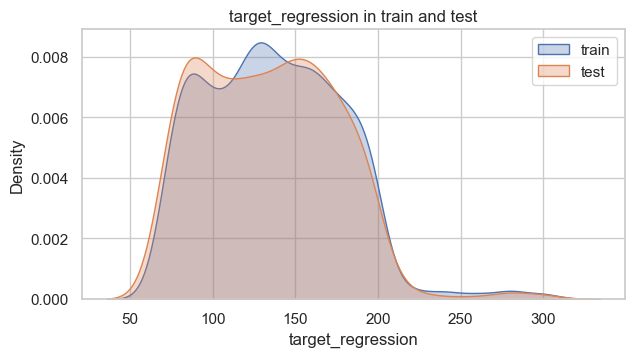

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)
print(pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()}).T)
print(f'\nKolmogorov-Smirnov test (same distribution?): p = {stats.ks_2samp(y_train, y_test).pvalue:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(y_train, ax=ax, label='train', fill=True, alpha=.3)
sns.kdeplot(y_test, ax=ax, label='test', fill=True, alpha=.3)
ax.set_title('target_regression in train and test'); ax.legend(); plt.show()

**Conclusions:** the training set has **1400** records and the test set **600**. The target distributions are
similar in the two sets:
- means of 136.9 and 133.8, standard deviations of 41.4 and 40.9, and the same range (70–300);
- the Kolmogorov-Smirnov test finds no difference (p = 0.288).

**Justification:** the random split produced a representative test set. Any differences we find between train
and test will come from the model, not from an unbalanced split.

### 5.4 Evaluation metrics, cross-validation and reference model (*baseline*)


| Metric | Formula | What it says |
|---|---|---|
| **R²** | $1 - RSS/TSS$ | Proportion of the target's variance explained by the model. 1 = perfect; **0 = as good as always predicting the mean**; negative = worse than the mean. |
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | Mean absolute error, in the units of the target. Easy to interpret and not very sensitive to isolated large errors. |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | Root mean squared error, also in the units of the target. It penalizes large errors more, because it squares them. |

**Why 5-fold cross-validation inside the training set?** To choose between features/combinations we need to
measure the error on data the model has not seen, but without touching the test set. Cross-validation splits the
training set into 5 parts: it trains on 4, evaluates on the 5th, and repeats 5 times. The average of the 5
evaluations is more stable than a single split.

**Why a *baseline*?** A model with no feature always predicts the training mean. An R² or an RMSE only mean
something compared with this: **if a model does not err less than the mean, the features add no information.** It
is the regression equivalent of a classifier that always predicts the majority class.

Standardization (`StandardScaler`) does not change the predictions of a linear regression, only the scale of the
coefficients. We include it so that the coefficients are comparable with one another and to prepare for Part 4
(Ridge/Lasso), where it is mandatory.

In [32]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

def fit_linear(X_tr, y_tr, degree=1, log_target=False):
    """Standardizes and fits the linear regression. Returns the function that predicts for new data.
    Written by hand so that the scaling stays inside each cross-validation fold."""
    poly = PolynomialFeatures(degree, include_bias=False) if degree > 1 else None
    A = poly.fit_transform(X_tr) if poly is not None else np.asarray(X_tr, dtype=float)
    scaler = StandardScaler().fit(A)
    model = LinearRegression().fit(scaler.transform(A), np.log1p(y_tr) if log_target else y_tr)

    def predict(X_new):
        B = poly.transform(X_new) if poly is not None else np.asarray(X_new, dtype=float)
        p = model.predict(scaler.transform(B))
        return np.expm1(p) if log_target else p
    return predict

def predict_mean(y_tr):
    """Baseline: always predicts the mean of the training set."""
    mean = float(y_tr.mean())
    return lambda X_new: np.full(len(X_new), mean)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}

def cv_scores(cols, degree=1, log_target=False, baseline=False, Xd=None, yd=None):
    """Manual 5-fold cross-validation: fits inside each training fold and evaluates
    on the fold left out."""
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    r2_train, r2_val, mae_val, rmse_val = [], [], [], []
    for train_idx, valid_idx in CV.split(Xd):
        X_a, X_b = Xd[cols].iloc[train_idx], Xd[cols].iloc[valid_idx]
        y_a, y_b = yd.iloc[train_idx], yd.iloc[valid_idx]
        predict = predict_mean(y_a) if baseline else fit_linear(X_a, y_a, degree, log_target)
        r2_train.append(r2_score(y_a, predict(X_a)))
        p = predict(X_b)
        r2_val.append(r2_score(y_b, p))
        mae_val.append(mean_absolute_error(y_b, p))
        rmse_val.append(np.sqrt(mean_squared_error(y_b, p)))
    return {'train_r2': float(np.mean(r2_train)), 'cv_r2': float(np.mean(r2_val)),
            'cv_r2_std': float(np.std(r2_val)), 'cv_mae': float(np.mean(mae_val)),
            'cv_rmse': float(np.mean(rmse_val))}

baseline_cv = cv_scores(FEATURES, baseline=True)
print(f'Standard deviation of the target in the training set: {y_train.std():.3f}')
pd.Series(baseline_cv, name='baseline (mean)').to_frame().T

Standard deviation of the target in the training set: 41.371


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
baseline (mean),0.0000,-0.0059,0.0037,33.9541,41.3848


**Conclusions:** the *baseline* errs, on average, by **34.0 units (MAE)**, with an RMSE of **41.4**. This RMSE is
practically equal to the standard deviation of the target (41.37), which is expected: always predicting the mean
produces an error equal to the natural dispersion of the data.

**This is the value to beat.** A feature is only useful if it makes the RMSE drop clearly below 41.4.

**A note on the baseline R²:** in cross-validation it is not exactly 0, but −0.006. In each fold the mean is
computed on that fold's training data and evaluated on different data, where the true mean is slightly different.
That is why, throughout the notebook, **we compare models against the baseline (−0.006) and not against zero.**

## 6. Simple Linear Regression

$$\hat y = \hat\beta_0 + \hat\beta_1 x$$

A single feature tries to explain the target. The coefficients are chosen by **least squares**, that is, so as to
minimize $RSS = \sum (y_i - \hat y_i)^2$.

**Strategy:**
1. Work out, from the EDA, **what the best possible R² is** (6.1).
2. Test **every** feature, one at a time (6.2).
3. Compare with a **random feature**, to find out whether the best ones differ from noise (6.3).
4. Analyse the chosen model in detail, with plots and residuals (6.4–6.6).
5. Check whether a **non-linear** relationship (polynomial) would be better (6.7).

### 6.1 What to expect? The limit the EDA already gives us

In simple linear regression there is a direct relationship between the Pearson correlation and the R²:

$$R^2_{\text{train}} = r^2$$

In other words, **the correlation computed in the EDA tells us, before training any model, what the maximum R²**
each feature can reach on the training set is. In the EDA, the highest correlation with the target was that of
`bmi` (r ≈ 0.07). We compute r and r² for every feature on the training set.

In [33]:
r_train = X_train.corrwith(y_train)
expected = pd.DataFrame({'r (train)': r_train, 'r2 = max expected R2': r_train ** 2,
                         '% variance explained': r_train ** 2 * 100})
expected.sort_values('r2 = max expected R2', ascending=False).head(10)

,r (train),r2 = max expected R2,% variance explained
bmi,0.0741,0.0055,0.5489
age,0.0699,0.0049,0.4879
age_level,0.0612,0.0037,0.3740
smoking,-0.0603,0.0036,0.3639
salt_intake,-0.0568,0.0032,0.3228
triglycerides,0.0530,0.0028,0.2814
bmi_level,0.0504,0.0025,0.2541
physical_activity,0.0496,0.0025,0.2464
HbA1c_level,0.0437,0.0019,0.1913
high_ldl_cholesterol,0.0396,0.0016,0.1572


**Conclusions:** before training any model, we already know the **best possible training R²** for a simple
regression:
- **`bmi`: r = 0.074 → maximum R² = 0.0055**, that is, **0.55%** of the target's variance;
- `age` comes next with 0.49%, then `age_level` (0.37%) and `smoking` (0.36%).

**Justification:** with a single feature, the least-squares line explains exactly r² of the variance. Since no
feature has |r| above 0.075, **no simple regression can explain more than ~0.5% of the variance**, not even on
the training set. This result numerically confirms what the EDA indicated: even the best feature will not give a
good model.

### 6.2 Testing every feature, one at a time

For each of the 30 features we fit a simple regression and record:
- the **training R²** (it should match the r² of the previous table);
- **β₁ and its p-value** (*t* test for $H_0: \beta_1 = 0$). A p-value < 0.05 indicates that the relationship is
  statistically significant;
- **R², MAE and RMSE in cross-validation**: this is the **selection criterion**, because it measures performance
  on data that was not used to estimate the coefficients.

The table is sorted by CV RMSE (lower = better). We show the *baseline* for comparison.

In [34]:
rows = []
for f in FEATURES:
    ols = sm.OLS(y_train, sm.add_constant(X_train[[f]])).fit()
    cv = cv_scores([f])
    rows.append({'feature': f, 'R2_train': ols.rsquared, 'beta1': ols.params[f], 'p_value': ols.pvalues[f],
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse'],
                 'better than baseline?': cv['cv_rmse'] < baseline_cv['cv_rmse']})
simple = pd.DataFrame(rows).set_index('feature').sort_values('cv_rmse')
print('Baseline: CV R2 = {cv_r2:.4f} | CV MAE = {cv_mae:.3f} | CV RMSE = {cv_rmse:.3f}'.format(**baseline_cv))
print(f"Features with p < 0.05: {(simple['p_value'] < 0.05).sum()} of {len(simple)}")
print(f"Features with CV RMSE below the baseline: {simple['better than baseline?'].sum()} of {len(simple)}")
simple

Baseline: CV R2 = -0.0059 | CV MAE = 33.954 | CV RMSE = 41.385
Features with p < 0.05: 6 of 30
Features with CV RMSE below the baseline: 11 of 30


,R2_train,beta1,p_value,cv_r2,cv_mae,cv_rmse,better than baseline?
feature,,,,,,,
bmi,0.0055,0.4254,0.0055,-0.0024,33.9732,41.3094,True
age,0.0049,0.1412,0.0089,-0.0028,33.8315,41.3234,True
age_level,0.0037,2.6719,0.0221,-0.0036,33.8664,41.3393,True
bmi_level,0.0025,1.9577,0.0594,-0.0038,33.9739,41.3410,True
HbA1c_level,0.0019,3.1327,0.1019,-0.0043,34.0091,41.3526,True
smoking,0.0036,-3.0273,0.0240,-0.0044,33.9326,41.3553,True
salt_intake,0.0032,-0.6723,0.0335,-0.0053,33.8729,41.3683,True
blood_pressure,0.0012,0.2771,0.1946,-0.0051,33.9363,41.3685,True
physical_activity,0.0025,2.5201,0.0634,-0.0054,33.9736,41.3725,True


**Conclusions:**
- The training R² of each feature **matches the r²** of the previous table (`bmi`: 0.0055), which confirms the
  relationship R² = r².
- **`bmi` is the best feature** on every criterion: highest training R², lowest CV RMSE (41.309) and the lowest
  p-value (0.0055). It is followed by `age` (RMSE 41.323) and `age_level` (41.339).
- **6 of the 30 features have a significant β₁** (p < 0.05): `bmi`, `age`, `age_level`, `smoking`, `salt_intake`
  and `triglycerides`.
- Only **11 of the 30** have a CV RMSE below the baseline, and **none has a positive CV R²** (the best is
  −0.0024, for `bmi`).

**Justification - why do these features come out on top?** They are the ones with the highest |r| with the target
(section 6.1). `bmi` and `age` always appear at the top: in the EDA's correlation table, in the p-values and now
in the validation error.

**Why is the gain so small?** `bmi` lowers the RMSE from 41.385 (baseline) to 41.309: **less than 0.1 units**, on
a target with a standard deviation of 41. This happens because `bmi` explains only 0.55% of the variance: the
remaining 99.45% stay unexplained.

**Significance ≠ predictive power.** The β₁ of `bmi` is significant (p = 0.006) because, with 1400 records, even
minuscule effects can be told apart from zero. The p-value says the effect probably **exists**; it does not say
it is **large** or useful for prediction.

### 6.3 Are the best features different from noise?

When the relationship between X and Y is **random**, the R² stays close to 0 and the coefficient is not
significant. We use that idea as a **control**: we create 500 features of **pure noise** (random numbers with no
relation whatsoever to the target), fit a simple regression with each one and see what training R² we obtain
**purely by chance**.

If the R² of `bmi` ends up clearly above what noise can achieve, the relationship is real (however weak). If it
falls in the middle of the noise distribution, `bmi` is no better than a random number.

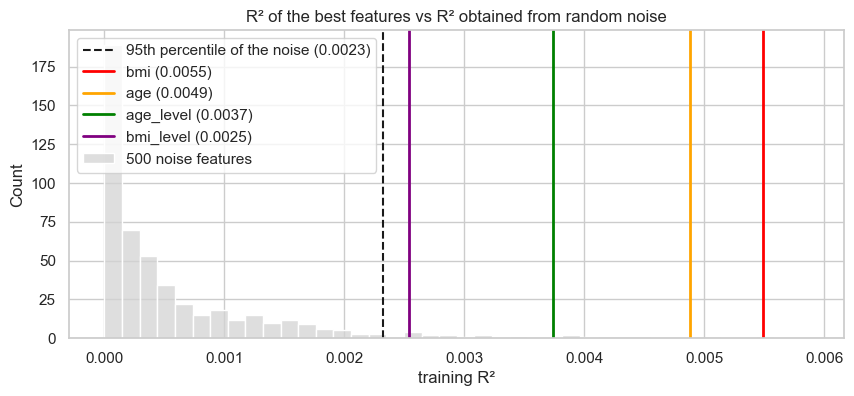

Mean R2 of the noise: 0.0006 | 95th percentile: 0.0023
Features above the 95th percentile of the noise (8): ['bmi', 'age', 'age_level', 'bmi_level', 'smoking', 'salt_intake', 'physical_activity', 'triglycerides']


In [35]:
rng = np.random.default_rng(SEED)
noise_r2 = np.array([sm.OLS(y_train, sm.add_constant(rng.normal(size=len(y_train)))).fit().rsquared
                     for _ in range(500)])
p95 = np.percentile(noise_r2, 95)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(noise_r2, bins=40, ax=ax, color='lightgrey', label='500 noise features')
ax.axvline(p95, color='k', ls='--', label=f'95th percentile of the noise ({p95:.4f})')
for f, c in zip(simple.index[:4], ['red', 'orange', 'green', 'purple']):
    ax.axvline(simple.loc[f, 'R2_train'], color=c, lw=2, label=f'{f} ({simple.loc[f, "R2_train"]:.4f})')
ax.set_xlabel('training R²'); ax.set_title('R² of the best features vs R² obtained from random noise'); ax.legend()
plt.show()

real = (simple['R2_train'] > p95)
print(f'Mean R2 of the noise: {noise_r2.mean():.4f} | 95th percentile: {p95:.4f}')
print(f'Features above the 95th percentile of the noise ({real.sum()}):', list(simple.index[real]))

**Conclusions:** the 500 noise features reach, purely by chance, a mean R² of **0.0006**, and 5% of them get past
**0.0023**. **8 features end up above this threshold**: `bmi` (0.0055), `age` (0.0049), `age_level`, `bmi_level`,
`smoking`, `salt_intake`, `physical_activity` and `triglycerides`.

**Justification:** `bmi` explains about **9 times** more variance than a typical random feature, and more than
twice the 95th percentile of the noise. **The relationship is real**, not an accident of the sample. At the same
time, the chart shows that all the features live on the same minuscule scale as the noise (0 to 0.006). The
relationship exists, but it is too weak to be of practical use.

The remaining 22 features fall inside the noise distribution: **they cannot be told apart from random numbers**,
which matches the "uninformative" features identified in the EDA.

### 6.4 Chosen simple model: statistical analysis (OLS)

We choose the feature with the **lowest cross-validated RMSE** (table 2.2). We analyse it with `statsmodels`, to
obtain:
- the coefficients $\hat\beta_0$ and $\hat\beta_1$ and their **interpretation**;
- the **standard error** and the **95% confidence interval** of $\hat\beta_1$;
- the ***t* test** and the p-value.

We also compute predictions for specific patients, to give practical meaning to the coefficient.

In [36]:
BEST_SIMPLE = simple.index[0]
ols_simple = sm.OLS(y_train, sm.add_constant(X_train[[BEST_SIMPLE]])).fit()
print(f'Chosen feature: {BEST_SIMPLE}\n')
print(ols_simple.summary().tables[1])
b0, b1 = ols_simple.params
print(f'\nEquation: target_regression = {b0:.3f} + {b1:.3f} x {BEST_SIMPLE}')
print(f'Training R2 = {ols_simple.rsquared:.4f}\n')
for v in (18.5, 25, 30, 40):
    print(f'  {BEST_SIMPLE} = {v:>4}  ->  prediction = {b0 + b1 * v:.1f}')
print(f'\nActual range of the target: {y_train.min():.0f} to {y_train.max():.0f} (standard deviation {y_train.std():.1f})')

Chosen feature: bmi

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.0606      4.411     28.353      0.000     116.408     133.713
bmi            0.4254      0.153      2.778      0.006       0.125       0.726

Equation: target_regression = 125.061 + 0.425 x bmi
Training R2 = 0.0055

  bmi = 18.5  ->  prediction = 132.9
  bmi =   25  ->  prediction = 135.7
  bmi =   30  ->  prediction = 137.8
  bmi =   40  ->  prediction = 142.1

Actual range of the target: 70 to 300 (standard deviation 41.4)


**Conclusions - chosen simple model: `bmi`.**

$$\widehat{target} = 125.06 + 0.425 \times bmi$$

- **Interpretation of β₁:** for each extra unit of BMI, the target increases on average by **0.43 units**. The 95%
  confidence interval is [0.125, 0.726], which does not include 0, and the *t* test gives p = 0.006.
- **Interpretation of β₀:** 125.06 would be the predicted value for BMI = 0. It has no clinical meaning (nobody
  has BMI 0); it only serves to position the line.
- **Prediction examples:** a lean patient (BMI 18.5) gets a prediction of 132.9 and a patient with severe obesity
  (BMI 40) one of 142.1. **A difference of 21.5 BMI units changes the prediction by only 9 units**, on a target
  that ranges from 70 to 300 (standard deviation 41.4).

**Justification for the choice:** `bmi` is the best on every criterion: training R² (0.0055), CV RMSE (41.309),
p-value (0.006), and the only one of these with a relationship clearly above the noise (6.3). It is also a
continuous measurement, more informative than its categorical version `bmi_level`. The choice is consistent with
the EDA, where `bmi` was already the feature most correlated with the target.

### 6.5 Visualization: actual vs predicted values

We use three charts on the training set:
1. **Scatter plot with the fitted line**: actual values (points) and the line $\hat y = \hat\beta_0 + \hat\beta_1 x$;
2. **Distribution of actual vs predicted values**: a good model produces predictions with a distribution similar
   to that of the actual values;
3. **Prediction error** (residual) of each record.

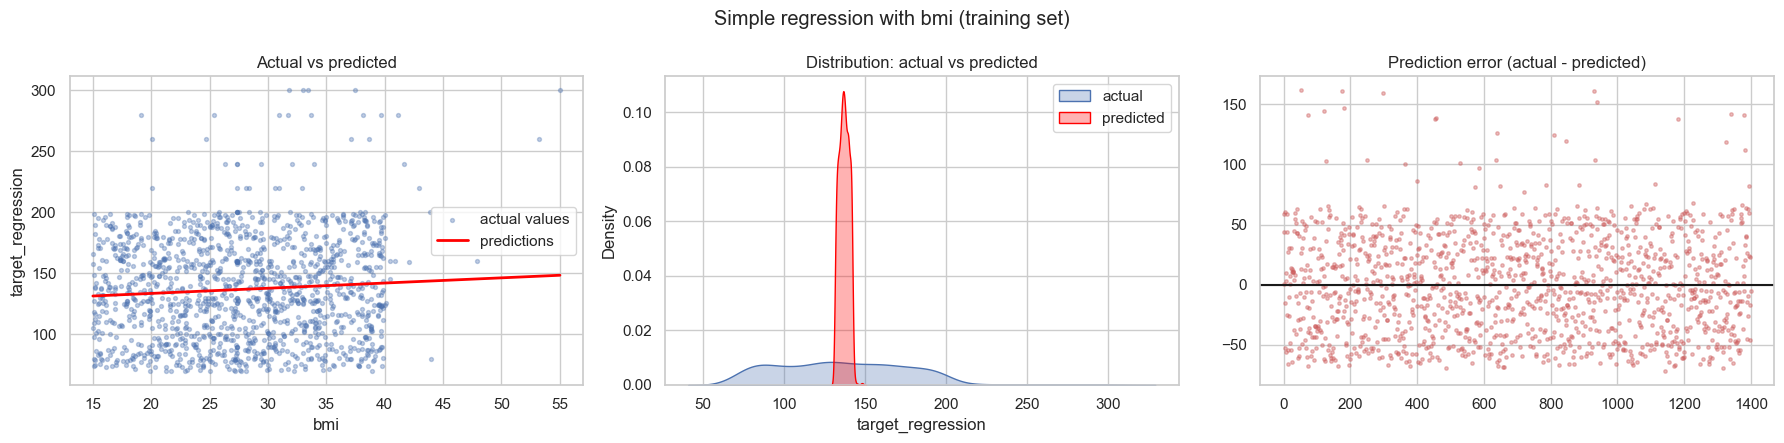

Predictions: min 131.4, max 148.5, standard deviation 3.07  |  actual values: standard deviation 41.37


In [37]:
pred_simple_train = ols_simple.fittedvalues

def plot_real_vs_pred(x, y_real, y_pred, xlabel, title, line=True):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].scatter(x, y_real, s=8, alpha=.35, label='actual values')
    if line:
        order = np.argsort(np.asarray(x))
        axes[0].plot(np.asarray(x)[order], np.asarray(y_pred)[order], color='red', lw=2, label='predictions')
    else:
        axes[0].scatter(x, y_pred, s=8, alpha=.5, color='red', label='predictions')
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel('target_regression'); axes[0].legend()
    axes[0].set_title('Actual vs predicted')
    sns.kdeplot(y_real, ax=axes[1], fill=True, alpha=.3, label='actual')
    sns.kdeplot(y_pred, ax=axes[1], fill=True, alpha=.3, color='red', label='predicted')
    axes[1].set_title('Distribution: actual vs predicted'); axes[1].legend()
    axes[2].scatter(range(len(y_real)), np.asarray(y_real) - np.asarray(y_pred), s=6, alpha=.4, color='indianred')
    axes[2].axhline(0, color='k'); axes[2].set_title('Prediction error (actual - predicted)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_real_vs_pred(X_train[BEST_SIMPLE], y_train, pred_simple_train, BEST_SIMPLE,
                  f'Simple regression with {BEST_SIMPLE} (training set)')
print(f'Predictions: min {pred_simple_train.min():.1f}, max {pred_simple_train.max():.1f}, '
      f'standard deviation {pred_simple_train.std():.2f}  |  actual values: standard deviation {y_train.std():.2f}')

**Conclusions:**
1. **Actual vs predicted:** the line is almost **horizontal**. The actual points are spread across the whole
   70–200 band, for any value of BMI. Knowing a patient's BMI hardly helps in guessing their target.
2. **Distribution:** the contrast is the most revealing result. The actual values spread from 70 to 300 (standard
   deviation **41.4**); the predictions concentrate in a narrow peak between 131 and 149 (standard deviation
   **3.1**). **The model predicts practically the same value (~137) for every patient.**
3. **Prediction error:** the errors run from about −65 to +160 and show no pattern across the records.

**Justification:** this is exactly what an R² of 0.0055 means in practice. When a feature barely explains the
target, the best least-squares strategy is to predict a value close to the mean for everyone. It is the same
phenomenon as in classification: a model without good features tends to always predict the majority class; here
it tends to always predict the mean.

### 6.6 Residual diagnostics

Problems to check in a linear regression - using the residuals $e_i = y_i - \hat y_i$:
- **Residuals vs fitted values**: a curve would indicate **non-linearity**; a "funnel" would indicate
  **non-constant variance** of the errors;
- **Q-Q plot**: compares the residuals with a normal distribution. Normality of the errors is an assumption of
  the *t* and *F* tests.

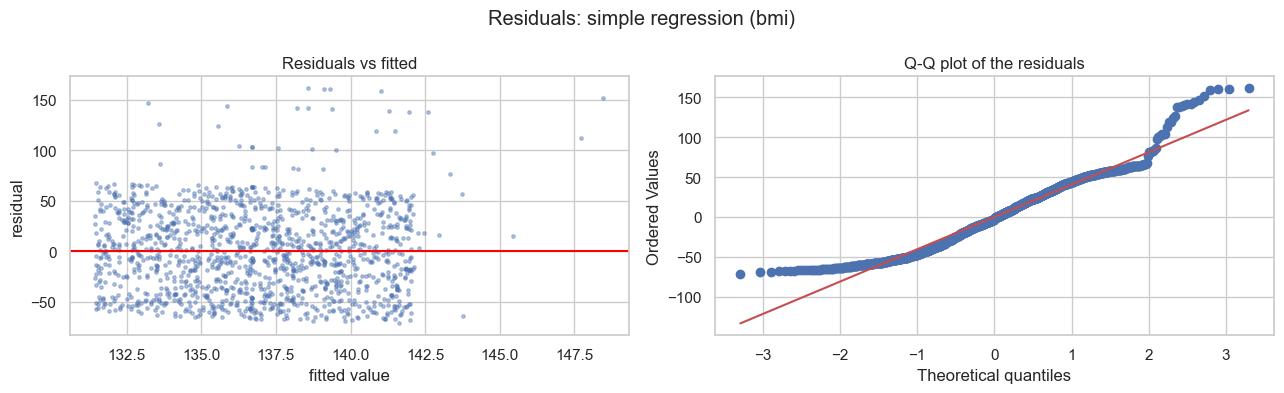

mean of the residuals = -0.000 | skew = 0.50
Records with the target at the lower bound (70): 10 | at the upper bound (300): 5


In [38]:
def residual_plots(fitted, resid, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(fitted, resid, s=6, alpha=.4); axes[0].axhline(0, color='red')
    axes[0].set_xlabel('fitted value'); axes[0].set_ylabel('residual'); axes[0].set_title('Residuals vs fitted')
    stats.probplot(resid, plot=axes[1]); axes[1].set_title('Q-Q plot of the residuals')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(f'mean of the residuals = {np.mean(resid):.3f} | skew = {stats.skew(resid):.2f}')

residual_plots(ols_simple.fittedvalues, ols_simple.resid, f'Residuals: simple regression ({BEST_SIMPLE})')
print(f'Records with the target at the lower bound (70): {(y_train == 70).sum()} | at the upper bound (300): {(y_train == 300).sum()}')

**Conclusions:**
- **Residuals vs fitted:** the cloud is a horizontal band, with no curvature and no "funnel" shape. **There are no
  signs of non-linearity or of non-constant variance.**
- **Q-Q plot:** the residuals depart from the normal in the tails and show **positive skew** (skew = 0.50). This
  is due to the few very high target values (up to 300), which generate large positive residuals. With n = 1400,
  the *t* and *F* tests remain approximately valid (central limit theorem).
- There are 10 records at the minimum value (70) and 5 at the maximum (300) of the training set. The EDA had
  flagged this accumulation at the extremes as possible truncation, but it affects few records.

**Justification:** the residuals do not indicate that the model has the **wrong shape**. They indicate that the
feature **has no information**. Changing the shape of the model (for instance, using a curve) should not solve
the problem; that is what we test next.

### 6.7 Would a non-linear relationship be better?

A straight line may be too simple if the relationship is curved. By adding polynomial terms:
$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots$. It is still **linear** regression in the coefficients.

We test degrees 1 to 5 with the chosen feature. A higher degree **always** increases the training R², because the
model becomes more flexible. That is why the choice has to be made by **cross-validation**.

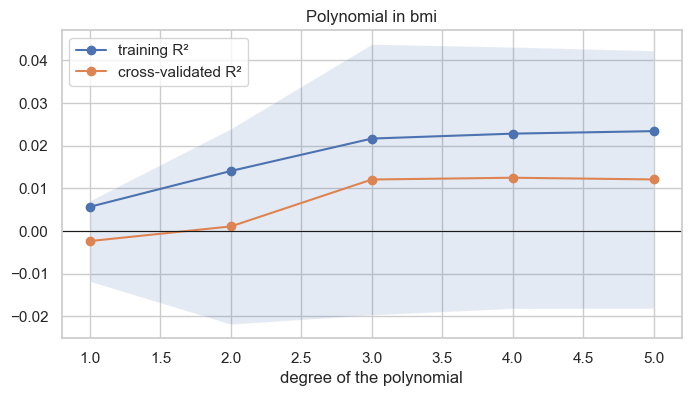

,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
degree,,,,,
1,0.0057,-0.0024,0.0095,33.9732,41.3094
2,0.0141,0.0011,0.0229,33.9041,41.2289
3,0.0216,0.0121,0.0317,33.7601,40.9945
4,0.0228,0.0125,0.0306,33.7529,40.9871
5,0.0234,0.0121,0.0302,33.7660,40.9960


In [39]:
poly = pd.DataFrame({d: cv_scores([BEST_SIMPLE], degree=d) for d in range(1, 6)}).T
poly.index.name = 'degree'

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poly.index, poly['train_r2'], marker='o', label='training R²')
ax.plot(poly.index, poly['cv_r2'], marker='o', label='cross-validated R²')
ax.fill_between(poly.index, poly['cv_r2'] - poly['cv_r2_std'], poly['cv_r2'] + poly['cv_r2_std'], alpha=.15)
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('degree of the polynomial'); ax.set_title(f'Polynomial in {BEST_SIMPLE}')
ax.legend(); plt.show()
poly

**Conclusions:**
- The **training R² always rises** with the degree (0.0057 → 0.0234), as expected: a more flexible polynomial
  fits the data it was trained on better.
- The **CV R²** also rises slightly (from −0.002 at degree 1 to ~0.012 at degrees 3–5), and the CV RMSE drops from
  41.31 to 40.99.
- However, the **standard deviation between folds (0.03)** is 2–3 times larger than the gain. In some folds the
  polynomial is better, in others worse.

**Justification - should we use the polynomial?** No. There are three reasons:
1. the gain is not **robust**: it falls inside the normal variability of cross-validation;
2. the chart in 6.5 shows that almost every patient has a BMI between 15 and 40 and only a few reach values up to
   ~55. A polynomial of degree 3 or more can "bend" to follow those few extreme points, which is *overfitting*
   and not a clinical relationship;
3. the assignment asks for a **simple linear** regression, and the straight line is more interpretable.

We keep the degree-1 model.

### Summary of the Simple Linear Regression

| Question | Answer | Evidence |
|---|---|---|
| Which is the best feature? | **`bmi`** | Lowest CV RMSE (41.309), highest R² (0.0055), lowest p-value (0.006) |
| Is the relationship real? | **Yes, but extremely weak** | 9× the mean R² of the noise; significant β₁ |
| Is the model useful for prediction? | **No** | It explains 0.55% of the variance; the RMSE drops by less than 0.1 against the baseline; the predictions all fall between 131 and 149 |
| Would a curve be better? | **Not robustly** | Gain smaller than the variability between folds |
| Does it make sense? | **Yes** | The EDA showed r ≈ 0.07 for `bmi`, the maximum in the dataset, and R² = r². The result was predictable. |

## 7. Multiple Linear Regression

$$\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \hat\beta_2 x_2 + \dots + \hat\beta_p x_p$$

Each $\beta_j$ measures the effect of $x_j$ **holding the other features fixed**. The idea is to combine several
weak features in the hope that, together, they explain more than any one of them alone.

**Strategy (incremental construction):**
1. Check the **collinearity**, to find out which features should not enter together (7.1).
2. Build the model **step by step**: 1 feature → 2 → 3 → …, explaining each gain or loss (7.2).
3. Test **all combinations** of 2 and 3 features, to confirm that the chosen order did not leave anything out
   (7.3).
4. Test **clinical groups** of features (7.4).
5. Show what happens when **all** the features are used: *overfitting* (7.5).
6. Show the effect of **collinearity** on the coefficients (7.6).
7. Test variants (target transformation, polynomial) and choose the final model (7.7–7.8).

### 7.1 Collinearity between features (VIF)

When two features are highly correlated, the model cannot separate the effect of each one. The coefficients
become unstable and may lose significance.

The **VIF** (*Variance Inflation Factor*) of a feature is $1/(1-R_j^2)$, where $R_j^2$ is the R² obtained when
predicting that feature from all the others. Reference values: VIF = 1 means the feature is independent of the
rest; VIF > 5–10 indicates problematic collinearity.

In [40]:
Xc = sm.add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=FEATURES, name='VIF').sort_values(ascending=False)
print(f'corr(age, age_level) = {X_train.age.corr(X_train.age_level):.3f} | '
      f'corr(bmi, bmi_level) = {X_train.bmi.corr(X_train.bmi_level):.3f}')
vif.to_frame().head(10)

corr(age, age_level) = 0.954 | corr(bmi, bmi_level) = 0.936


,VIF
age_level,11.3724
age,11.3228
bmi_level,8.4259
bmi,8.3254
high_ldl_cholesterol,2.8568
ldl,2.8506
low_hdl_cholesterol,1.4350
hdl,1.4106
employment_status_Unemployed,1.3630
employment_status_Retired,1.3548


**Conclusions:** there are **two pairs of collinear features**, the same ones the EDA identified:
- `age` ↔ `age_level`: VIF ≈ 11.3, correlation 0.954;
- `bmi` ↔ `bmi_level`: VIF ≈ 8.4, correlation 0.936.

There are also two weak pairs: `ldl`/`high_ldl_cholesterol` (VIF ≈ 2.9) and `hdl`/`low_hdl_cholesterol` (≈ 1.4).
**All the other features have a VIF close to 1**, that is, they are practically independent of one another.

**Justification and decision:** `age_level` and `bmi_level` are discretizations of the continuous variables and
contain the same information, but with less detail. In the combinations that follow we use **only the continuous
version** (`age`, `bmi`) and the original variables `hdl`/`ldl` instead of the *flags*. In section 7.6 we show
what happens when this rule is not followed.

### 7.2 Incremental construction: 1, 2, 3, … features

We build the model by adding **one feature at a time**. The order follows the **strength of the relationship with
the target** (|r| on the training set, section 6.1), but we use only one version of each variable: the continuous
one (`age`, `bmi`), not the discretized one (`age_level`, `bmi_level`), because of the collinearity seen in 7.1.

At each step we record:
- the **training R²**: it rises *every* time a feature is added, even a noisy one, because the model has more
  freedom to fit the data;
- the **adjusted R²**: $1 - (1-R^2)\frac{n-1}{n-p-1}$. It penalizes the number of features *p* and only rises if
  the new feature adds more than would be expected by chance;
- **R², MAE and RMSE in cross-validation**: they tell us whether the model improves on new data.

**What we are looking for:** the point beyond which adding features stops reducing the validation error.

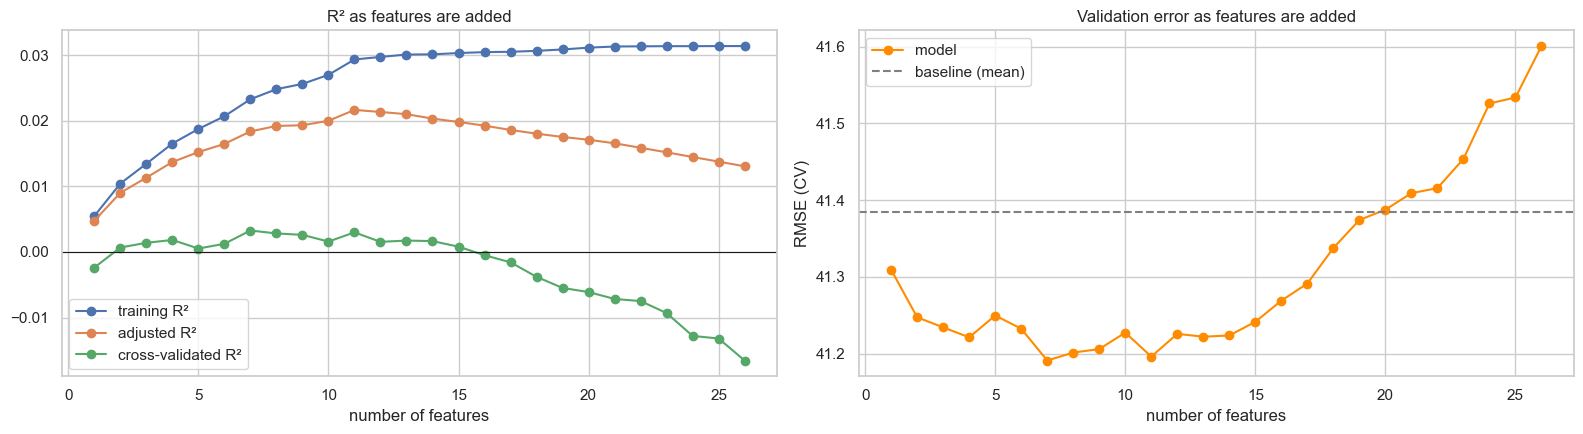

,feature added,r of the feature,R2_train,R2_adjusted,cv_r2,cv_mae,cv_rmse
n,,,,,,,
1,bmi,0.0741,0.0055,0.0048,-0.0024,33.9732,41.3094
2,age,0.0699,0.0104,0.0090,0.0007,33.8505,41.2475
3,smoking,-0.0603,0.0135,0.0113,0.0014,33.8462,41.2344
4,salt_intake,-0.0568,0.0165,0.0137,0.0018,33.7758,41.2214
5,triglycerides,0.0530,0.0188,0.0152,0.0005,33.8280,41.2498
6,physical_activity,0.0496,0.0207,0.0165,0.0012,33.8581,41.2326
7,HbA1c_level,0.0437,0.0233,0.0184,0.0033,33.9333,41.1912
8,hdl,-0.0374,0.0248,0.0192,0.0028,33.9264,41.2016
9,crp_level,0.0372,0.0256,0.0193,0.0026,33.9272,41.2061


In [41]:
order = [f for f in r_train.abs().sort_values(ascending=False).index
         if f not in ('age_level', 'bmi_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol')]
rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]
    ols = sm.OLS(y_train, sm.add_constant(X_train[cols].astype(float))).fit()
    cv = cv_scores(cols)
    rows.append({'n': k, 'feature added': cols[-1], 'r of the feature': r_train[cols[-1]],
                 'R2_train': ols.rsquared, 'R2_adjusted': ols.rsquared_adj,
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
incremental = pd.DataFrame(rows).set_index('n')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(incremental.index, incremental['R2_train'], marker='o', label='training R²')
axes[0].plot(incremental.index, incremental['R2_adjusted'], marker='o', label='adjusted R²')
axes[0].plot(incremental.index, incremental['cv_r2'], marker='o', label='cross-validated R²')
axes[0].axhline(0, color='k', lw=.8); axes[0].set_xlabel('number of features'); axes[0].legend()
axes[0].set_title('R² as features are added')
axes[1].plot(incremental.index, incremental['cv_rmse'], marker='o', color='darkorange', label='model')
axes[1].axhline(baseline_cv['cv_rmse'], color='grey', ls='--', label='baseline (mean)')
axes[1].set_xlabel('number of features'); axes[1].set_ylabel('RMSE (CV)'); axes[1].legend()
axes[1].set_title('Validation error as features are added')
plt.tight_layout(); plt.show()
incremental.head(12)

**Step-by-step conclusions:**

| Step | What happens | Why |
|---|---|---|
| **1 → 2** (`bmi` + `age`) | The CV R² goes from −0.002 to **0.001** (the first positive value) and the RMSE drops from 41.31 to 41.25. **It is the largest gain of the whole construction.** | `age` is the 2nd most correlated feature with the target (r = 0.070) and is **independent** of `bmi` (correlation −0.007). It therefore brings new information: the contributions add up (training R² 0.0055 + 0.0049 ≈ 0.0104). |
| **2 → 4** (+ `smoking`, + `salt_intake`) | Small improvements: RMSE 41.23 → 41.22. | Features with r ≈ −0.06, also independent of the previous ones. Each adds ~0.3% of training R². |
| **5** (+ `triglycerides`) | The CV RMSE **rises** (41.25). | The feature helps on the training set, but does not generalize: the contribution it makes in training is partly noise. |
| **7** (+ `HbA1c_level`) | **Best CV RMSE: 41.191.** | `HbA1c_level` has a low r on the training set (0.044), but combined with the others it improves validation. |
| **8 → 12** | The CV RMSE oscillates between 41.20 and 41.23, without improving. | The new features have r < 0.04: they are at the level of noise (section 6.3). |

**The general pattern (chart):**
- the **training R² always rises** (0.0055 → 0.0298 with 12 features), because each feature gives the model more
  freedom to fit the training data, even if it is noise;
- the **adjusted R²** rises more and more slowly, because it penalizes the number of features;
- the **CV R² stabilizes around 0.002–0.003** from 4 features onwards and then oscillates. The CV RMSE never
  drops more than ~0.2 below the baseline.

**Justification:** the growing gap between the training R² and the CV R² is the definition of *overfitting*. The
first features (`bmi`, `age`) bring real information; the following ones bring mostly noise, which improves the
training fit but not new data.

### 7.3 All combinations of 2 and of 3 features

The incremental construction followed a fixed order (that of |r|), but it may happen that two individually weak
features work well together. To confirm, we test **all** combinations of 2 and of 3 features among the 12 best
continuous/ordinal features (66 pairs and 220 triples), evaluated by cross-validation.

We show the 5 best and the 3 worst of each size, to understand **what distinguishes a good combination from a
bad one.**

In [42]:
pool = order[:12]
combo_rows = []
for size in (2, 3):
    for cols in combinations(pool, size):
        cv = cv_scores(list(cols))
        combo_rows.append({'n': size, 'features': ' + '.join(cols), 'cv_r2': cv['cv_r2'],
                           'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
combos_df = pd.DataFrame(combo_rows)
for size in (2, 3):
    sub = combos_df[combos_df.n == size].sort_values('cv_rmse')
    print(f'\n=== {size} features: {len(sub)} combinations | {(sub.cv_rmse < baseline_cv["cv_rmse"]).sum()} better than the baseline ===')
    display(pd.concat([sub.head(5), sub.tail(3)]).set_index('features'))
print(f'corr(bmi, age) on the training set = {X_train.bmi.corr(X_train.age):.3f}')


=== 2 features: 66 combinations | 53 better than the baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age,2,0.0007,33.8505,41.2475
bmi + HbA1c_level,2,-0.0008,34.0375,41.2767
age + HbA1c_level,2,-0.0009,33.8854,41.2838
bmi + physical_activity,2,-0.0014,34.0030,41.2866
bmi + smoking,2,-0.0012,33.9500,41.2876
alcohol_intake + family_history,2,-0.0070,33.9994,41.4069
hdl + family_history,2,-0.0073,33.9676,41.4131
hdl + alcohol_intake,2,-0.0073,33.9550,41.4162



=== 3 features: 220 combinations | 188 better than the baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age + HbA1c_level,3,0.0026,33.9074,41.2080
bmi + age + blood_pressure,3,0.0022,33.8227,41.2136
bmi + age + smoking,3,0.0014,33.8462,41.2344
bmi + age + physical_activity,3,0.0011,33.8761,41.2360
bmi + age + salt_intake,3,0.0010,33.7757,41.2369
triglycerides + hdl + alcohol_intake,3,-0.0075,34.0138,41.4196
triglycerides + hdl + family_history,3,-0.0078,34.0234,41.4255
hdl + alcohol_intake + family_history,3,-0.0080,33.9871,41.4295


corr(bmi, age) on the training set = -0.007


**Conclusions:**
- **Best pair: `bmi` + `age`** (CV RMSE 41.248). **Best triple: `bmi` + `age` + `HbA1c_level`** (41.208),
  followed by `bmi` + `age` + `blood_pressure` (41.214).
- **The 5 best pairs and the 5 best triples all contain `bmi`**, and all the best triples contain `bmi` and
  `age`.
- **The worst combinations** put together `hdl`, `alcohol_intake`, `family_history` and `triglycerides` (RMSE ≈
  41.41–41.43, **worse than the baseline**).
- Even so, 53 of the 66 pairs and 188 of the 220 triples end up (very slightly) below the baseline.

**Justification - why do some combinations give less error than others?**
1. **A combination is only as good as the features that make it up.** `bmi` and `age` are the two features with
   the highest |r| and the only ones clearly above the noise in 6.3. Any combination without them loses.
2. **The features must bring different information.** `bmi` and `age` have a correlation of −0.007 with each
   other: each explains a different part of the target's variance, and the effects add up. Putting together two
   correlated features (such as `bmi` and `bmi_level`) adds nothing, because they repeat the same information.
3. **Adding features unrelated to the target makes the model worse.** The worst combinations are made up of
   features at the level of noise. The model estimates coefficients for them from random patterns in the training
   data, which do not repeat in the validation data, and the error goes up.

The exhaustive search confirms the order of the incremental construction: there is no "hidden" pair or triple
that works better than the combinations with `bmi` and `age`.

### 7.4 Clinical groups of features

Another way to choose combinations is to use **domain knowledge**: grouping the features by the type of clinical
information they represent and seeing whether any group, as a whole, explains the target. If the target were, for
example, a lipid marker, the lipid group should stand out.

In [43]:
GROUPS = {
    'Anthropometric (age, bmi)':              ['age', 'bmi'],
    'Anthropometric + glycaemic':             ['age', 'bmi', 'HbA1c_level'],
    'Glycaemic (HbA1c)':                      ['HbA1c_level'],
    'Lipid':                                  ['cholesterol', 'triglycerides', 'hdl', 'ldl'],
    'Blood pressure / cardiac':               ['systolic_bp', 'diastolic_bp', 'blood_pressure', 'heart_rate'],
    'Inflammatory':                           ['crp_level', 'homocysteine_level', 'plasma_value'],
    'Lifestyle':                              ['smoking', 'physical_activity', 'stress_level', 'sugar_consumption',
                                               'sleep_hours', 'alcohol_intake', 'salt_intake'],
    'Sociodemographic':                       ['gender', 'education_level', 'family_history',
                                               'employment_status_Retired', 'employment_status_Unemployed'],
    'All continuous numeric':                 CONTINUOUS,
}
groups = pd.DataFrame({g: {'n_features': len(c), **cv_scores(c)} for g, c in GROUPS.items()}).T
groups['better than baseline?'] = groups['cv_rmse'] < baseline_cv['cv_rmse']
groups.sort_values('cv_rmse')

,n_features,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse,better than baseline?
Anthropometric + glycaemic,3.0000,0.0131,0.0026,0.0091,33.9074,41.2080,True
"Anthropometric (age, bmi)",2.0000,0.0108,0.0007,0.0096,33.8505,41.2475,True
Glycaemic (HbA1c),1.0000,0.0020,-0.0043,0.0043,34.0091,41.3526,True
All continuous numeric,17.0000,0.0291,-0.0056,0.0174,33.9903,41.3733,True
Lifestyle,7.0000,0.0121,-0.0071,0.0135,33.9405,41.4047,False
Lipid,4.0000,0.0058,-0.0073,0.0126,33.9931,41.4164,False
Inflammatory,3.0000,0.0018,-0.0085,0.0073,33.9810,41.4390,False
Blood pressure / cardiac,4.0000,0.0020,-0.0105,0.0058,34.0077,41.4768,False
Sociodemographic,5.0000,0.0025,-0.0135,0.0045,34.0732,41.5417,False


**Conclusions:**
- Only **4 groups** end up below the baseline: **anthropometric + glycaemic** (RMSE 41.208), anthropometric
  (41.248), glycaemic (41.353) and, by very little, all the continuous numeric features (41.373 against 41.385).
- The **lipid, blood pressure, inflammatory, lifestyle and sociodemographic groups all end up above the
  baseline**: they predict worse than the mean.
- The group with **all 17 continuous numeric features** has the highest training R² (0.029), but in
  cross-validation it ends up practically equal to the baseline (41.373 against 41.385). The little signal from
  `age` and `bmi` is almost entirely cancelled out by the noise of the other 15 features.

**Justification:** a group works if it contains features related to the target. The winning groups are the ones
that include `age` and `bmi`, the only ones with real signal. The other groups are made up of features with
r ≈ 0 (Part 1, section 3.4) and, with nothing to learn, they only add noise.

The poor performance of the lipid group is informative: **there is no evidence that the target is a lipid
marker**, because cholesterol, triglycerides, HDL and LDL do not explain it. The same goes for blood pressure and
inflammation. The name and units of the target remain unknown.

### 7.5 What if we use all the features? *Overfitting*

The natural temptation is to "put everything into the model". We fit the regression with the 30 features and
compare the performance on the **training set** with the performance in **cross-validation**. A large gap between
the two is the classic sign of ***overfitting***: the model fits the noise specific to the training data, which
does not repeat on new data.

In [44]:
ols_all = sm.OLS(y_train, sm.add_constant(X_train.astype(float))).fit()
cv_all = cv_scores(FEATURES)
print(f'Training R2 = {ols_all.rsquared:.4f} | adjusted R2 = {ols_all.rsquared_adj:.4f} | '
      f'F test: F = {ols_all.fvalue:.2f}, p = {ols_all.f_pvalue:.4f}')
print(f'CV: R2 = {cv_all["cv_r2"]:.4f} | MAE = {cv_all["cv_mae"]:.3f} | RMSE = {cv_all["cv_rmse"]:.3f}')
print(f'Baseline CV RMSE = {baseline_cv["cv_rmse"]:.3f}')
sig = ols_all.pvalues.drop('const')
print(f'\nCoefficients with p < 0.05: {list(sig[sig < 0.05].index)}')

Training R2 = 0.0370 | adjusted R2 = 0.0159 | F test: F = 1.75, p = 0.0073
CV: R2 = -0.0261 | MAE = 34.201 | RMSE = 41.793
Baseline CV RMSE = 41.385

Coefficients with p < 0.05: ['bmi_level', 'bmi', 'triglycerides', 'salt_intake']


**Conclusions:** with the 30 features:
- the **training R² is the highest of all (0.0370)** and the *F* test is significant (p = 0.007);
- but the **CV R² is −0.026** and the CV RMSE is **41.79, clearly worse than the baseline (41.38)**;
- the adjusted R² (0.0159) is lower than that of models with fewer features (section 7.2);
- 4 coefficients are significant: `bmi_level`, `bmi`, `triglycerides` and `salt_intake`. Two of them are the
  collinear pair `bmi`/`bmi_level`, whose coefficients come out distorted (see 7.6).

**Justification:** this is ***overfitting***. With 30 coefficients to estimate and almost no real signal, the
model uses its flexibility to fit random patterns in the training data. Those patterns do not exist in the
validation data, so **the model with the most features is the one that generalizes worst**.

It is also a good example that a significant *F* test does not guarantee a useful model: the test says that at
least one coefficient differs from zero, not that the model predicts well.

### 7.6 The effect of collinearity on the coefficients

To show in practice the problem identified in 7.1, we compare the coefficient of `bmi` in two models:
- with `bmi` only;
- with `bmi` **and** `bmi_level` (its discretized version, VIF ≈ 8).

If collinearity is a problem, the standard error of the coefficient increases and the p-value gets worse,
**without the model predicting any better**.

In [45]:
m1 = sm.OLS(y_train, sm.add_constant(X_train[['bmi']])).fit()
m2 = sm.OLS(y_train, sm.add_constant(X_train[['bmi', 'bmi_level']])).fit()
colin = pd.DataFrame({
    'bmi only':          {'bmi coef': m1.params['bmi'], 'bmi std. error': m1.bse['bmi'], 'bmi p-value': m1.pvalues['bmi'],
                          'training R2': m1.rsquared, 'CV RMSE': cv_scores(['bmi'])['cv_rmse']},
    'bmi + bmi_level':   {'bmi coef': m2.params['bmi'], 'bmi std. error': m2.bse['bmi'], 'bmi p-value': m2.pvalues['bmi'],
                          'training R2': m2.rsquared, 'CV RMSE': cv_scores(['bmi', 'bmi_level'])['cv_rmse']},
}).T
colin

,bmi coef,bmi std. error,bmi p-value,training R2,CV RMSE
bmi only,0.4254,0.1531,0.0055,0.0055,41.3094
bmi + bmi_level,1.2453,0.4343,0.0042,0.0084,41.3448


**Conclusions:**
- **`bmi` only:** coefficient 0.425, standard error 0.153.
- **`bmi` + `bmi_level`:** the coefficient of `bmi` **almost triples** (1.245) and so does the standard error
  (0.434). The training R² rises slightly (0.0055 → 0.0084), but the **CV RMSE gets worse** (41.31 → 41.34).

**Justification:** since `bmi` and `bmi_level` measure the same thing (correlation 0.936), the model cannot
separate the effect of each. The coefficient of `bmi` stops meaning "effect of one unit of BMI", because it is
now offset by the coefficient of `bmi_level` in the opposite direction. The coefficients become **unstable and
inflated**, with no gain in prediction. This confirms the decision to use only the continuous variables.

### 7.7 Variants: target transformation and polynomial terms

We test two ideas, applied to the best combination found so far:
1. **`log1p(target)`**: reduces the skew of the target. The metrics are computed back on the original scale, so
   that they are comparable;
2. **Degree-2 polynomial**: adds the squares and the products between features (interactions).

In [46]:
best_combo_row = combos_df.sort_values('cv_rmse').iloc[0]
best_inc_n = incremental['cv_rmse'].idxmin()
candidates_multi = {
    f'Incremental (best n = {best_inc_n})': order[:best_inc_n],
    f'Best combination ({best_combo_row.features})': best_combo_row.features.split(' + '),
}
BEST_MULTI_NAME = min(candidates_multi, key=lambda k: cv_scores(candidates_multi[k])['cv_rmse'])
BEST_MULTI = candidates_multi[BEST_MULTI_NAME]
print('Candidates:'); [print(f'  {k}: {v}') for k, v in candidates_multi.items()]
print(f'Basis for the variants: {BEST_MULTI_NAME}\n')

variants = pd.DataFrame({
    'linear':                cv_scores(BEST_MULTI),
    'log1p(target)':         cv_scores(BEST_MULTI, log_target=True),
    'degree-2 polynomial':   cv_scores(BEST_MULTI, degree=2),
}).T
print(f'skew of the target: {y_train.skew():.2f} -> skew of log1p(target): {np.log1p(y_train).skew():.2f}')
variants

Candidates:
  Incremental (best n = 7): ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']
  Best combination (bmi + age + HbA1c_level): ['bmi', 'age', 'HbA1c_level']
Basis for the variants: Incremental (best n = 7)

skew of the target: 0.53 -> skew of log1p(target): -0.16


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
linear,0.0248,0.0033,0.0105,33.9333,41.1912
log1p(target),0.0033,-0.0176,0.0291,33.9824,41.6151
degree-2 polynomial,0.0768,0.0117,0.0221,34.0876,41.0132


**Conclusions:** the two candidates for the multiple model were:
- **incremental with 7 features** (CV RMSE 41.191);
- **the best triple** `bmi` + `age` + `HbA1c_level` (41.208).

The 7-feature one has the lowest error and was used as the basis for the variants:
- **`log1p(target)`:** it reduces the skew of the target (0.53 → −0.16), but **makes the model worse** (CV RMSE
  41.62, CV R² −0.018);
- **degree-2 polynomial:** it raises the CV R² to 0.012 and lowers the RMSE to 41.01, but **makes the MAE worse**
  (34.09 vs 33.93). With 7 features, it goes from 7 to 35 terms and the training R² triples (0.077): a sign of
  *overfitting*.

**Justification:**
- In the Boston Housing example, `log1p` helped because there were strong relationships, which became more linear
  on the logarithmic scale. Here the problem is not the shape of the distribution: it is the lack of information
  in the features. The log compresses the high values, and the model ends up underestimating them even more.
- The gain of the polynomial is smaller than the standard deviation between folds (0.022) and is not confirmed by
  the MAE. It is not robust.

**Decision:** keep the **linear** regression.

### 7.8 Chosen multiple model: statistical analysis and visualization

We analyse the chosen model with `statsmodels`:
- the ***F* test** of the whole model, $H_0: \beta_1 = \dots = \beta_p = 0$, which answers the question (is any
  feature useful?);
- the ***t* test** of each coefficient;
- the same actual-vs-predicted and residual charts used in the simple regression.

Features: ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                93.2643     15.300      6.096      0.000      63.251     123.277
bmi                   0.3983      0.152      2.615      0.009       0.100       0.697
age                   0.1388      0.054      2.580      0.010       0.033       0.244
smoking              -2.4445      1.338     -1.828      0.068      -5.068       0.179
salt_intake          -0.6715      0.314     -2.141      0.032      -1.287      -0.056
triglycerides         0.0343      0.017      2.021      0.043       0.001       0.068
physical_activity     2.1089      1.349      1.563      0.118      -0.538       4.756
HbA1c_level           3.7061      1.927      1.923      0.055      -0.075       7.487

Training R2 = 0.0233 | adjusted R2

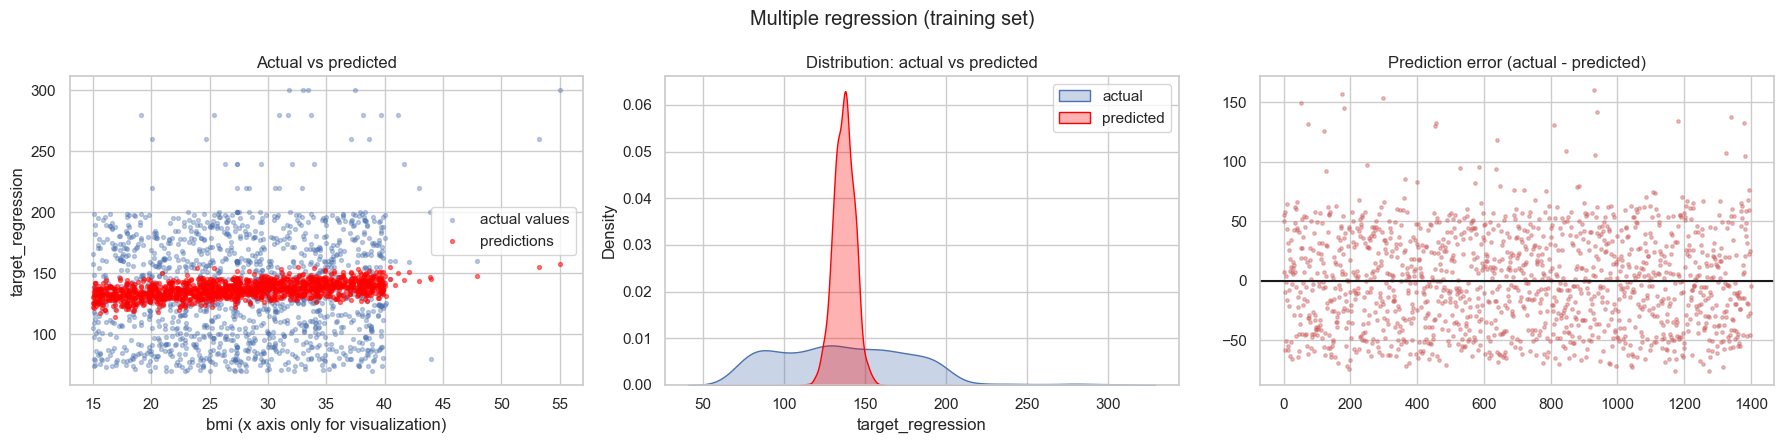

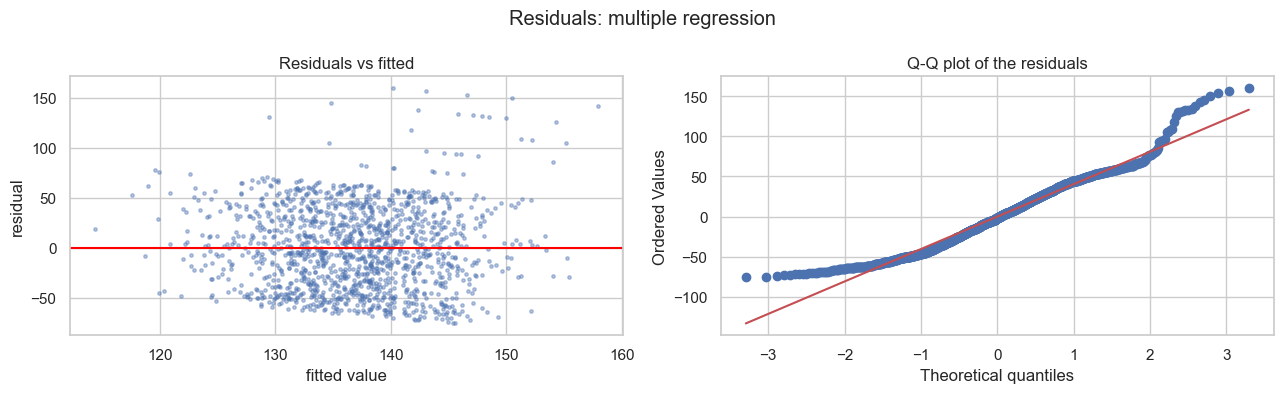

mean of the residuals = 0.000 | skew = 0.43
Predictions: min 114.4, max 157.9, standard deviation 6.32


In [47]:
ols_multi = sm.OLS(y_train, sm.add_constant(X_train[BEST_MULTI].astype(float))).fit()
print(f'Features: {BEST_MULTI}\n')
print(ols_multi.summary().tables[1])
print(f'\nTraining R2 = {ols_multi.rsquared:.4f} | adjusted R2 = {ols_multi.rsquared_adj:.4f}')
print(f'Global F test: F = {ols_multi.fvalue:.3f}, p = {ols_multi.f_pvalue:.2e}')
eq = ' '.join(f'{v:+.3f} x {k}' for k, v in ols_multi.params.drop('const').items())
print(f'\nEquation: target_regression = {ols_multi.params["const"]:.3f} {eq}')

plot_real_vs_pred(X_train['bmi'], y_train, ols_multi.fittedvalues, 'bmi (x axis only for visualization)',
                  'Multiple regression (training set)', line=False)
residual_plots(ols_multi.fittedvalues, ols_multi.resid, 'Residuals: multiple regression')
print(f'Predictions: min {ols_multi.fittedvalues.min():.1f}, max {ols_multi.fittedvalues.max():.1f}, '
      f'standard deviation {ols_multi.fittedvalues.std():.2f}')

**Conclusions - chosen multiple model: incremental construction with 7 features.**

$$\widehat{target} = 93.26 + 0.398\,bmi + 0.139\,age - 2.44\,smoking - 0.672\,salt + 0.034\,trig + 2.11\,phys.act + 3.71\,HbA1c$$

- **Global *F* test:** F = 4.74, p = 2.8×10⁻⁵. We reject $H_0$ (all β = 0): the features, taken together, do have
  a statistical relationship with the target.
- **Significant coefficients (p < 0.05):** `bmi` (+0.40 per unit), `age` (+0.14 per year), `salt_intake` (−0.67)
  and `triglycerides` (+0.034). `HbA1c_level` (p = 0.055) and `smoking` (p = 0.068) sit on the borderline;
  `physical_activity` is not significant (p = 0.12).
- The coefficients of `bmi` (0.398) and `age` (0.139) are practically the same as in the simple models (0.425 and
  0.141). This confirms that the features are independent (VIF ≈ 1): putting them together does not change the
  effect of either.
- **Training R² = 0.023 (adjusted 0.018):** the model explains about **2%** of the variance, 4 times more than the
  simple regression, but still very little.

**Visualization:** the predictions spread a little more than those of the simple model (114–158, standard
deviation 6.3, against 3.1), but they remain very concentrated compared with the actual values (standard
deviation 41.4). The residuals behave the same way: no pattern, positive skew (skew = 0.43).

**Clinical interpretation: caution.** Some signs are not what would be expected clinically (for example, more
salt associated with a *lower* target). Since the effects are minuscule and the target is unknown, **we should
not draw clinical conclusions** from these coefficients.

**Justification for the choice:** it is the combination with the lowest CV RMSE (41.191). As an alternative, the
triple `bmi` + `age` + `HbA1c_level` has an almost identical error (41.208), with less than half the features.
The difference between the two (0.017) is much smaller than the variability between folds, so the triple would be
an equally defensible choice by the principle of parsimony (preferring the simpler model when performance is
equivalent).

### Summary of the Multiple Linear Regression

| Question | Answer | Evidence |
|---|---|---|
| Does combining features help? | **A little, up to ~4–7 features** | CV RMSE 41.31 (1 feature) → 41.19 (7) |
| Which is the best group? | **`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level`** | Lowest CV RMSE among the incremental construction, 286 combinations and 9 clinical groups |
| Why is `bmi` + `age` the best pair? | They are the 2 features with the most signal **and** they are independent of each other | r = 0.074 and 0.070; correlation between them −0.007 |
| And with all the features? | **Worse than the baseline** | *Overfitting*: training R² 0.0370, CV R² −0.026 |
| Use continuous + discretized? | **No** | Unstable and inflated coefficients, with no gain in prediction |
| Does it make sense? | **Yes** | Combining weak, independent features adds up small R² values (0.0055 + 0.0049 + …), but the total stays at ~2% |

## 8. Final evaluation on the test set

With every choice settled **using the training set only**, we now evaluate the models on the test set (600
records never used). It is this evaluation that answers the assignment: *"Evaluate both models using appropriate
metrics (R², MAE, RMSE)"*.

We compare four models:
- the **Baseline** (training mean), the minimum reference;
- the **simple regression** chosen in section 6;
- the **multiple regression** chosen in section 7;
- the **regression with all the features**, only to confirm the *overfitting* (it is not a chosen model).

### 8.1 Metrics on the test set

Each model is trained on the whole training set and evaluated on the test set. We show the training metrics
alongside the test ones: the difference between the two shows how much each model loses when moving to new data.

In [48]:
final_models = {
    'Baseline (mean)':                         ('mean', FEATURES),
    f'Simple ({BEST_SIMPLE})':                  ('linear', [BEST_SIMPLE]),
    f'Multiple ({" + ".join(BEST_MULTI)})':     ('linear', BEST_MULTI),
    f'All features ({len(FEATURES)})':          ('linear', FEATURES),
}
preds, rows = {}, {}
for name, (kind, cols) in final_models.items():
    predict = predict_mean(y_train) if kind == 'mean' else fit_linear(X_train[cols], y_train)
    preds[name] = predict(X_test[cols])
    rows[name] = {**{f'train_{k}': v for k, v in metrics(y_train, predict(X_train[cols])).items()},
                  **{f'test_{k}': v for k, v in metrics(y_test, preds[name]).items()}}
results = pd.DataFrame(rows).T
names = list(preds)
results

,train_R2,train_MAE,train_RMSE,test_R2,test_MAE,test_RMSE
Baseline (mean),0.0000,33.9128,41.3560,-0.0058,34.2872,41.0163
Simple (bmi),0.0055,33.9046,41.2423,-0.0024,34.1833,40.9479
Multiple (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),0.0233,33.6568,40.8713,0.0045,34.1100,40.8067
All features (30),0.0370,33.2981,40.5832,-0.0180,34.3145,41.2641


**Conclusions - results on the test set (600 patients never seen):**

| Model | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (mean) | −0.006 | 34.29 | 41.02 |
| Simple (`bmi`) | −0.002 | 34.18 | 40.95 |
| **Multiple (7 features)** | **0.005** | **34.11** | **40.81** |
| All features (30) | −0.018 | 34.31 | 41.26 |

- **The multiple regression is the best on all three metrics**, followed by the simple one and the baseline.
  **The ordering is the same as in cross-validation**: the choices made on the training set alone generalized
  consistently.
- The model with all the features is **the worst**, below the baseline. It has the highest training R² (0.0370)
  and the lowest test R² (−0.018), which confirms the *overfitting* detected in 7.5.
- The improvements are **very small**: the multiple model errs on average by **34.11** against **34.29** for the
  baseline, 0.18 units less (**0.5%**).
- In every model the test R² is lower than the training one, as expected.

### 8.2 Are the differences between models real? (*bootstrap*)

The differences in the previous table may be small. To find out whether they are real or a matter of chance
(of which patients happened to fall into the test set), we use ***bootstrap***: we resample the test set 1000
times, with replacement, and recompute the metrics on each resample. This gives us a **95% confidence interval**
for each metric and for the difference between models.

If the interval of the difference between a model and the baseline includes zero, **we cannot claim that the
model is better than predicting the mean**.

In [49]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))

boot = {}
for name, p in preds.items():
    r2s = [r2_score(yt[i], p[i]) for i in idx]; rm = [rmse(yt[i], p[i]) for i in idx]
    boot[name] = {'R2 95% CI': f'[{np.percentile(r2s, 2.5):.3f}, {np.percentile(r2s, 97.5):.3f}]',
                  'RMSE 95% CI': f'[{np.percentile(rm, 2.5):.2f}, {np.percentile(rm, 97.5):.2f}]'}
for name in names[1:]:
    d = [rmse(yt[i], preds[name][i]) - rmse(yt[i], preds[names[0]][i]) for i in idx]
    boot[name]['RMSE diff. vs baseline (95% CI)'] = f'{np.mean(d):+.3f}  [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]'
pd.DataFrame(boot).T.fillna('-')

,R2 95% CI,RMSE 95% CI,RMSE diff. vs baseline (95% CI)
Baseline (mean),"[-0.026, -0.000]","[38.63, 43.29]",-
Simple (bmi),"[-0.026, 0.011]","[38.60, 43.19]","-0.065 [-0.292, +0.153]"
Multiple (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),"[-0.031, 0.032]","[38.52, 42.96]","-0.194 [-0.742, +0.322]"
All features (30),"[-0.057, 0.013]","[38.91, 43.44]","+0.256 [-0.369, +0.867]"


**Conclusions:**
- The confidence intervals of the RMSE **overlap almost completely**: every model falls between ~38.5 and ~43.5.
- **RMSE difference against the baseline:**
  - simple: −0.065, 95% CI **[−0.29, +0.15]**;
  - multiple: −0.194, 95% CI **[−0.74, +0.32]**;
  - all features: +0.256, 95% CI [−0.37, +0.87].
- **Every interval includes zero.**

**Justification:** since zero lies inside every interval, **we cannot claim, with 95% confidence, that any model
is better than predicting the mean**. The small advantages in table 4.1 may result from which patients happened
to fall into the test set. With a different train/test split, the ordering could change.

### 8.3 Visualizing the comparison

Two kinds of chart:
1. **Bars with R², MAE and RMSE on the test set**, to compare the models directly;
2. **Predicted vs actual values on the test set.** In a perfect model, every point would lie on the red diagonal.
   In a model that learns nothing, the points form a horizontal line at the mean.

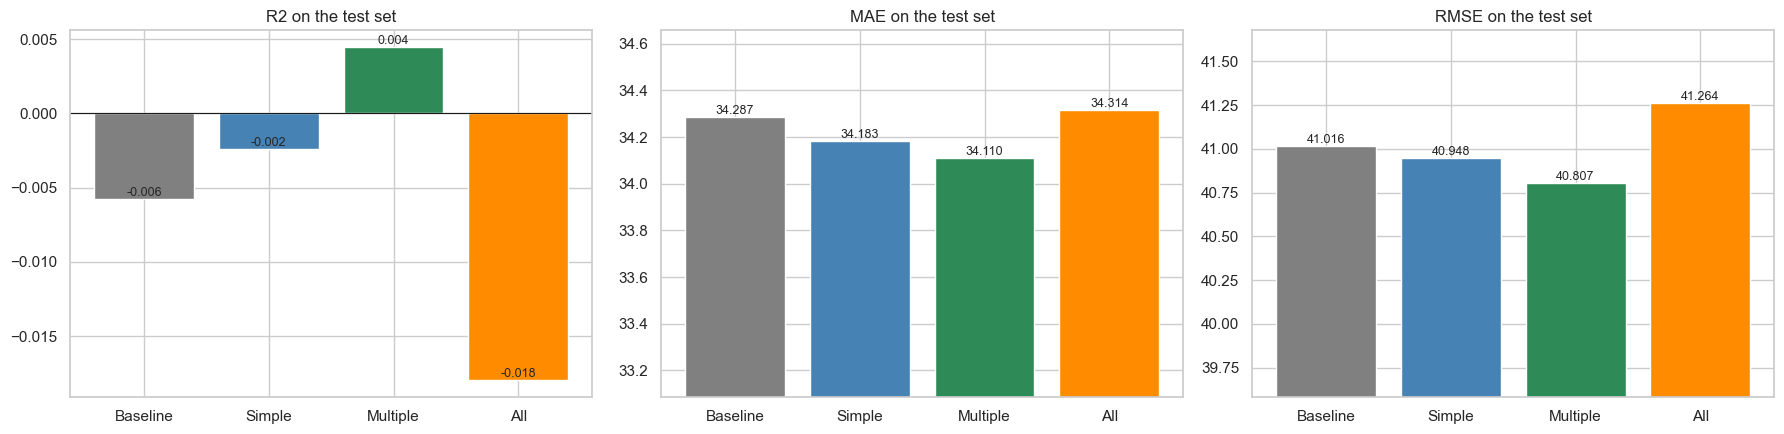

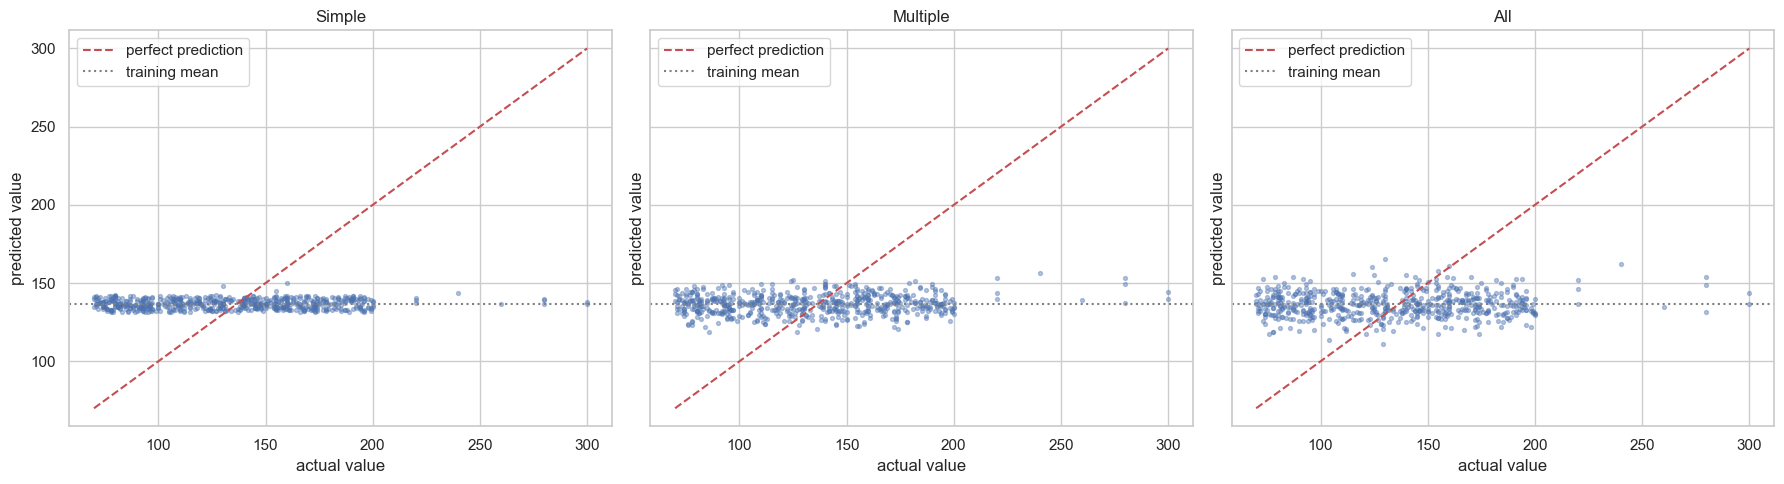

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
short = ['Baseline', 'Simple', 'Multiple', 'All']
for ax, m in zip(axes, ['R2', 'MAE', 'RMSE']):
    vals = results[f'test_{m}'].to_numpy()
    ax.bar(short, vals, color=['grey', 'steelblue', 'seagreen', 'darkorange'])
    ax.set_title(f'{m} on the test set'); ax.axhline(0, color='k', lw=.8)
    for i, v in enumerate(vals): ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    if m != 'R2': ax.set_ylim(vals.min() * 0.97, vals.max() * 1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name, s in zip(axes, names[1:], short[1:]):
    ax.scatter(y_test, preds[name], s=8, alpha=.4)
    lims = [y_test.min(), y_test.max()]; ax.plot(lims, lims, 'r--', label='perfect prediction')
    ax.axhline(y_train.mean(), color='grey', ls=':', label='training mean')
    ax.set_xlabel('actual value'); ax.set_ylabel('predicted value'); ax.set_title(s); ax.legend()
plt.tight_layout(); plt.show()

**Conclusions:**
- **Bars:** the four models have practically identical metrics (MAE between 34.1 and 34.4; RMSE between 40.8 and
  41.3). The scales of the MAE and RMSE charts were zoomed in so that the differences are visible; on a scale
  starting at zero, the bars would be indistinguishable.
- **Predicted vs actual:** instead of following the red diagonal, the predictions form a **horizontal band**
  around the training mean (~137). Patients with target 70 and patients with target 300 get similar predictions.

**Justification:** this is the picture of a model that found no information in the features to tell patients
apart. The multiple model "opens up" the band a little more than the simple one, but it is still far from the
diagonal.

### 8.4 Why does no feature explain the target? A final look at `target_regression`

Before the discussion, we go back to the target itself to understand **where** its variation comes from. The
actual-vs-predicted charts (6.5) suggest that almost every value is spread evenly between 70 and 200, with few
values above. We check:
- whether, between 70 and 200, the distribution is compatible with a **uniform** one (Kolmogorov-Smirnov test);
- how many values lie above 200 and which diagnostic class they belong to (a purely descriptive use of
  `target_class`, as in the EDA; it enters no model).

Values between 70 and 200: 1957 (97.9%) | KS vs uniform(70, 200): D = 0.038, p = 0.00706
Values above 200: 43 | by class: {'DI_HY': 22, 'DI_HT': 21}
Proportion of each class with target > 200: {'DI_HT': 0.247, 'DI_HY': 0.012, 'HT': 0.0}


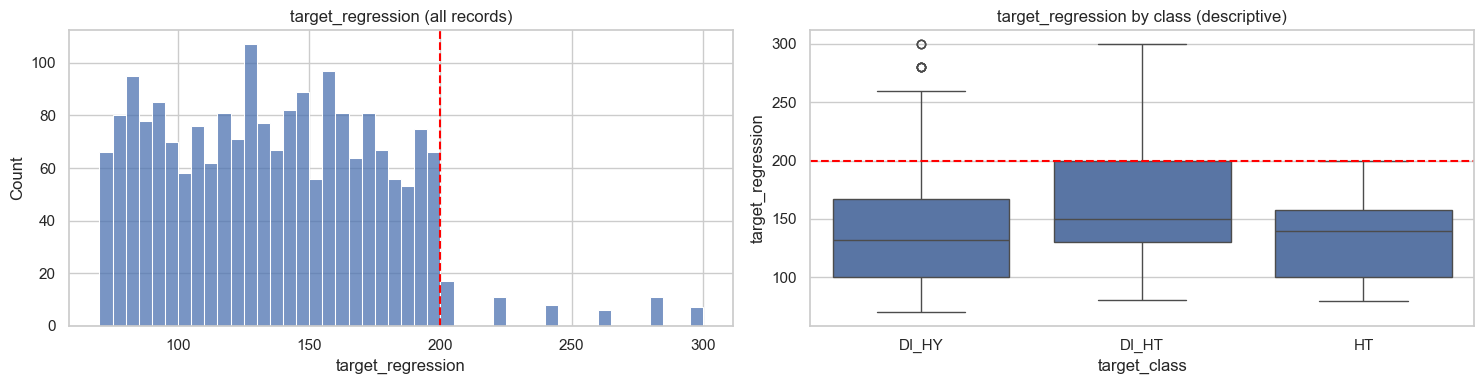

In [51]:
t = raw[TARGET]
inside = t[t <= 200]
ks_u = stats.kstest(inside, stats.uniform(loc=70, scale=130).cdf)
print(f'Values between 70 and 200: {len(inside)} ({len(inside)/len(t):.1%}) | KS vs uniform(70, 200): '
      f'D = {ks_u.statistic:.3f}, p = {ks_u.pvalue:.3g}')
high = raw[t > 200]
print(f'Values above 200: {len(high)} | by class: {high.target_class.value_counts().to_dict()}')
print(f'Proportion of each class with target > 200: '
      f'{(high.target_class.value_counts() / raw.target_class.value_counts()).fillna(0).round(3).to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(t, bins=46, ax=axes[0]); axes[0].axvline(200, color='red', ls='--')
axes[0].set_title('target_regression (all records)')
sns.boxplot(data=raw, x='target_class', y=TARGET, ax=axes[1]); axes[1].axhline(200, color='red', ls='--')
axes[1].set_title('target_regression by class (descriptive)')
plt.tight_layout(); plt.show()

**Conclusions:**
- **97.9%** of the target values lie between 70 and 200, with an **almost uniform** distribution (a flat
  histogram). The KS test rejects perfect uniformity (p = 0.007), but the distance is small (D = 0.038). With
  almost 2000 values, even minimal deviations come out "significant".
- Only **43 values (2.1%) go past 200**, and they concentrate in the `DI_HT` class: **24.7% of the `DI_HT`
  patients** have a target above 200, against 1.2% of `DI_HY` and 0% of `HT`.

**Justification - what this explains:**
1. **A uniform target, unrelated to the features, is the worst-case scenario for a regression.** On a range from
   70 to 200, every value is equally likely for any patient, whatever their BMI, age or cholesterol. There is
   nothing for the model to learn.
2. **What little structure there is comes from the diagnostic class** (high values in `DI_HT`), which we cannot
   use as a predictor. This also explains why the EDA found `target_class` to be the variable most associated
   with the target (η² ≈ 0.027).
3. "Flat" distributions had already been observed in many features in the EDA (Part 1, section 2.2). It reinforces the
   hypothesis of **synthetic** data, in which the target was generated practically independently of the features.

## 9. Comparison, discussion and conclusions

### 9.1 Comparison of the two models

| | **Simple Linear Regression** | **Multiple Linear Regression** |
|---|---|---|
| Features | `bmi` | `bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level` |
| How they were chosen | Best of 30 features, tested one at a time | Incremental construction, confirmed by 286 combinations and 9 clinical groups |
| Training R² | 0.0055 | 0.0233 |
| Test R² | −0.002 | **0.005** |
| Test MAE | 34.18 | **34.11** |
| Test RMSE | 40.95 | **40.81** |
| RMSE difference against the baseline (95% CI) | −0.07 [−0.29, +0.15] | −0.19 [−0.74, +0.32] |
| Significance | *t*: p = 0.006 | *F*: p = 2.8×10⁻⁵ |

**The multiple regression is slightly better** on all three metrics, in cross-validation and on the test set. By
combining several weak, independent features, it accumulates small contributions: its training R² is 4 times
larger than that of the simple model.

**But neither model is useful in practice.** Both err, on average, by about 34 units, practically the same as
always predicting the mean (34.29). The differences are not statistically robust.

### 9.2 Discussion: does the result make sense?

**Yes, and it was predictable from the EDA.** The chain of reasoning is as follows:

1. **The EDA showed that the best correlation with the target is r ≈ 0.07 (`bmi`).** In simple regression,
   R² = r², so the limit was 0.0055 (0.55%). The model reached exactly that value (sections 6.1 and 6.2).
2. **The features are independent of one another**, so in multiple regression the individual R² values add up
   approximately. Adding the contributions of the ~7 best features (all below 0.6%) gives ~2%, which is the
   result obtained (7.8).
3. **The features that help most are those with the highest |r| and above the noise** (`bmi`, `age`). The ones
   that make the model worse are those which, in the EDA and in the noise test (6.3), cannot be told apart from
   random numbers (`hdl`, `alcohol_intake`, `heart_rate`…).
4. **More features is not better.** With 30 features the model memorizes training noise (*overfitting*) and ends
   up worse than the mean on new data (7.5 and 8.1).
5. **The shape of the model is not the problem.** The residuals show no curvature; polynomials and `log1p` bring
   no robust gains (6.7 and 7.7).
6. **The target itself explains the result.** It is almost uniform between 70 and 200 and only the rare values
   above 200 have any link, to the `DI_HT` class (8.4). There is no structure in the features for the model to
   learn.

**Parallel with the classification:** in the EDA we saw that `target_class` is dominated by `DI_HY` (90%), and a
classifier without good features will tend to predict that class almost always. The equivalent happens here in
regression: **without informative features, the least-squares model converges to the mean** and predicts ~137 for
almost every patient (6.5, 8.3). In both cases, comparing against the *baseline* (majority class / mean) is
mandatory if the model is not to be overrated.

**Statistical significance ≠ predictive power.** Several coefficients have p < 0.05 and the *F* test of the
multiple model is highly significant (p = 2.8×10⁻⁵). With 1400 records, even minuscule effects can be told apart
from zero. The p-value says the effect probably **exists**; the R², the MAE and the RMSE say it is **far too
small** to predict with.

### 9.3 Conclusions
- **Simple regression:** `target_regression = 125.06 + 0.425 × bmi`. `bmi` is the best single feature on every
  criterion, but it explains only 0.55% of the variance.
- **Multiple regression:** 7 features (`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`,
  `physical_activity`, `HbA1c_level`), which explain about 2% of the variance. The triple `bmi` + `age` +
  `HbA1c_level` is an almost equivalent and simpler alternative.
- **Performance on the test set:** R² ≈ 0, MAE ≈ 34, RMSE ≈ 41. **No model predicts better than the mean** in a
  statistically robust way.
- **It is a negative result, but a valid one:** it was obtained with a correct methodology (choices made on the
  training set only, cross-validation, the test set used once, a baseline, a noise control, confidence intervals)
  and it is consistent with the EDA.

---

# From Part 2 to Part 3

Part 2 confirmed, with fitted models, what the exploratory analysis had predicted: **the continuous target
cannot be predicted from these *features***. The best multiple model ends at R² = 0.005 on the test set and errs,
on average, by practically the same amount as always predicting the mean.

Part 3 attacks the **other target**, and the starting point is quite different:

| | Regression (Part 2) | Classification (Part 3) |
|---|---|---|
| Target | `target_regression`, continuous | `target_class`, three categories |
| Signal detected in Part 1 | maximum \|r\| of 0.07 | `HbA1c_level` with **η² = 0.410** and `triglycerides` with 0.105 (section 3.6) |
| Main difficulty | absence of signal | **imbalance**: 89.9% of the records in `DI_HY` and only 85 in `DI_HT` |
| Reference metric | RMSE against the mean | macro F1 and *balanced accuracy* against the trivial classifier |
| Baseline to beat | always predicting the mean | always predicting `DI_HY`, which already gives 0.899 accuracy |

There is a parallel here that Part 2 had already pointed out: without informative *features*, the regression
converges to the mean and the classification converges to the majority class. **Comparing against the *baseline*
is mandatory in both cases**, which is why Part 3 begins by computing it.

Part 3 also adds a dimension that Part 2 did not explore: **how the resampling method affects the confidence in
the estimate**, comparing *holdout*, k-fold, LOOCV and *bootstrap*.

# Part 3: Methods Application - Classification

**Dataset:** `dataset_grupo_22.csv`, with 2000 patient profiles. **Variable to predict:** `target_class`, the
diagnostic category (`DI_HY`, `HT`, `DI_HT`). The clinical meaning of the codes is not given in the assignment.

### Objective
1. Apply **Logistic Regression** and **Linear Discriminant Analysis (LDA)** and **decide which method is most
   appropriate**, with justification.
2. Evaluate using the resampling methods: ***holdout***, **cross-validation (k = 5 and k = 10)**, **LOOCV** and
   ***bootstrap***.
3. Choose appropriate metrics and **explain how the variance is affected by the resampling method**.

### Starting point: what the EDA already told us
| EDA finding | Consequence for classification |
|---|---|
| `target_class` is **highly imbalanced**: 89.9% `DI_HY`, 5.85% `HT`, 4.25% `DI_HT` | An unadjusted model tends to predict `DI_HY` almost always. *Accuracy* is misleading; per-class metrics and **stratified** resampling are needed. |
| `HbA1c_level` strongly separates `HT` from the other classes (η² = 0.41); `triglycerides` separates `DI_HY` from the minority classes (η² = 0.105) | We expect `HT` to be relatively easy to identify and these to be the most important features. |
| `DI_HT` and `DI_HY` overlap heavily | `DI_HT` should be the hardest class. |
| The distributions are far from "normal" (uniform, skewed, long tails) | The LDA assumptions may not hold (checked in 11.1). |
| Decimal-precision artefact linked to the class | Logistic Regression and LDA use the numeric value linearly and do not exploit decimal places; we create no features from them. |

## 10. Data preparation

### 10.1 Loading the data and setting up the environment

We load the original dataset (without modifying it) and fix the random seed at **22** (project rule), so that every
data split, cross-validation and *bootstrap* resample is reproducible.

In [52]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneOut
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
dataset_path = next(p for p in [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name] if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dataset shape:', raw.shape)
raw['target_class'].value_counts().to_frame('n').assign(**{'%': lambda d: d['n'] / len(raw) * 100})

Dataset shape: (2000, 35)


,n,%
target_class,,
DI_HY,1798,89.900
HT,117,5.850
DI_HT,85,4.250


**Conclusions:** the dataset has **2000 records**: 1798 `DI_HY` (89.9%), 117 `HT` (5.85%) and **only 85 `DI_HT`
(4.25%)**. The majority class is 21 times larger than the smallest one. This number will shape everything that
follows: the choice of metrics, the need for stratification and the behaviour of the models.

### 10.2 Feature removal, encoding and predictor matrix

We apply **the same preparation as in the regression notebook**, for the same reasons (EDA, `01_EDA`):
- we remove `calcium_baseline` (constant), `systolic_index` (copy of `systolic_bp`) and `age_normalized` (rescaling
  of `age`). The last two would make the covariance matrix **singular**, which is a direct problem for LDA, since it
  has to invert that matrix;
- we also remove `ldl_alternative`: it has the same values as `ldl`, but shuffled across patients (it matches on only
  18 of 2000 rows). The value does not belong to the patient in that row, so it is noise;
- we convert the categorical variables into numbers (ordinal → 0, 1, 2…; binary → 0/1; `employment_status` →
  *one-hot*);
- **we remove both targets from the predictors**: `target_class` is what we want to predict and `target_regression`
  is the other outcome of the assignment.

All remaining 30 features are kept. Feature selection is the topic of Part 4 (Ridge/Lasso); here the goal is to
compare classification and resampling methods under the same conditions.

In [53]:
TARGET = 'target_class'
CLASSES = ['DI_HY', 'HT', 'DI_HT']          # fixed order: majority -> minorities
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']
ORDINAL = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_regression'])
y = data[TARGET]
assert X.isna().sum().sum() == 0
FEATURES = list(X.columns)
print(f'{X.shape[0]} records x {len(FEATURES)} features')

2000 records x 30 features


**Conclusions:** **30 features** remain for the 2000 records, with no missing values. With about 67 records per
feature, there is enough data to estimate a Logistic Regression or an LDA with a common covariance matrix.

Even so, the `DI_HT` class has only 85 patients. This rules out, for example, a **QDA**: it would have to estimate a
30×30 covariance matrix (465 parameters) from those 85 patients alone, and the estimate would be very unstable. This
is one of the reasons we stick to the two methods requested.

### 10.3 Evaluation metrics: why *accuracy* is not enough

The EDA showed that `target_class` is **highly imbalanced** (≈ 90% `DI_HY`). Under these conditions *accuracy* is
misleading: a model that always answers `DI_HY` is right ≈ 90% of the time without having learned anything. We
therefore use the following metrics, adapted to 3 classes:

| Metric | What it measures | Why it is useful here |
|---|---|---|
| **Recall per class** | Of the patients in each class, how many were correctly identified | Shows directly whether the rare classes (`HT`, `DI_HT`) are being detected |
| **Precision per class** | Of the predictions for each class, how many are correct | Shows the cost of "inventing" diagnoses |
| **Macro F1** (main metric) | Simple average of the F1 of the 3 classes | Every class weighs the same, so missing a rare class lowers the metric a lot |
| **Balanced accuracy** | Simple average of the 3 class recalls | A model that always predicts the majority class scores 1/3 = 0.333 |
| *Accuracy* | Proportion of correct predictions | Secondary reference only |
| **Confusion matrix** | Which classes are confused with which | Detailed diagnosis of the errors |

To make this concrete, we evaluate a **reference classifier** (*baseline*) that always predicts the majority class.

In [54]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {'f1_macro': f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
            'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'accuracy': accuracy_score(y_true, y_pred),
            **{f'recall_{c}': r for c, r in zip(CLASSES, rec)}}

baseline_pred = np.full(len(y), 'DI_HY')
pd.Series(metrics(y, baseline_pred), name='baseline (always DI_HY)').to_frame().T

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
baseline (always DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


**Conclusions:** the classifier that always answers `DI_HY` has an **accuracy of 0.899**, which looks like a good
result. But it identifies **no** `HT` or `DI_HT` patient (recall = 0), and therefore has:
- **macro F1 = 0.316**;
- **balanced accuracy = 0.333** (= 1/3).

**Justification:** this is numerical proof that *accuracy* cannot be the main metric for this problem. From here on,
the main metric is **macro F1**, complemented by **balanced accuracy** and the **recall of each class**. Any useful
model must be clearly above 0.316 and 0.333.

## 11. Logistic Regression vs LDA

**Logistic Regression:** models the probability of each class directly,
$P(Y=k \mid X) = \frac{e^{\beta_{k0} + \beta_k^T x}}{\sum_j e^{\beta_{j0} + \beta_j^T x}}$ (multinomial
version), with coefficients estimated by **maximum likelihood**. It **assumes nothing** about the distribution of
the features.

**LDA:** models the distribution of the features **within each class** as multivariate normal, with a **common
covariance matrix**, and uses Bayes' theorem, $P(Y=k \mid X) \propto \pi_k \, f_k(x)$, where $\pi_k$ is the
prior probability of the class. The decision boundaries are linear.

**Strategy:**
1. check whether the LDA assumptions hold in our data (11.1);
2. fit both methods without adjustments and look at the effect of the imbalance (11.2);
3. correct the imbalance and compare (11.3);
4. test whether the differences are statistically significant (11.4).

### 11.1 Do the LDA assumptions hold?

LDA assumes that, **within each class**, the features follow a **normal** distribution and that
**all classes share the same covariance matrix**. Logistic Regression makes no such assumptions. Knowing whether the
assumptions hold helps us understand which method should perform better.

For the most discriminative features from the EDA, we check:
- **normality within each class** (Shapiro-Wilk test and skewness);
- **equality of variances across classes** (Levene's test and the ratio between the largest and smallest standard
  deviation).

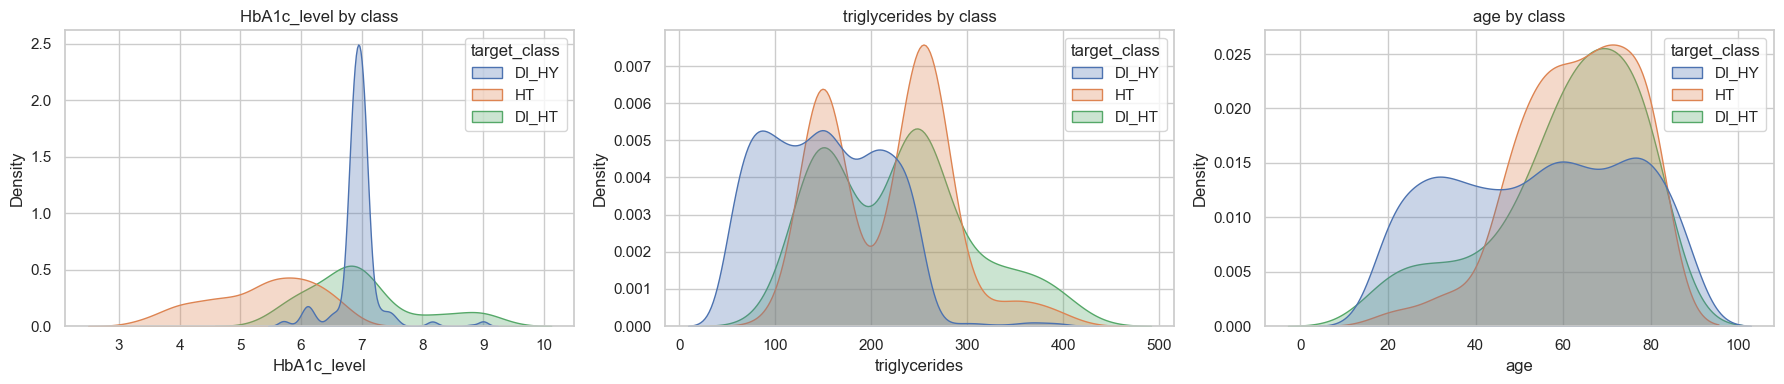

,std_DI_HY,std_HT,std_DI_HT,std_ratio (max/min),p_Levene,skew_DI_HY,p_Shapiro_DI_HY
feature,,,,,,,
HbA1c_level,0.359,0.868,0.907,2.528,0.000,1.368,0.000
triglycerides,61.097,63.418,75.080,1.229,0.072,0.311,0.000
age,20.662,13.346,16.871,1.548,0.000,-0.080,0.000
bmi,7.285,6.013,5.819,1.252,0.000,0.086,0.000
blood_pressure,4.416,8.181,11.553,2.616,0.000,-0.733,0.000
crp_level,0.939,1.530,2.537,2.702,0.000,0.441,0.000


In [55]:
key = ['HbA1c_level', 'triglycerides', 'age', 'bmi', 'blood_pressure', 'crp_level']
rows = []
for f in key:
    groups = [data.loc[y == c, f] for c in CLASSES]
    stds = [g.std() for g in groups]
    rows.append({'feature': f,
                 **{f'std_{c}': s for c, s in zip(CLASSES, stds)},
                 'std_ratio (max/min)': max(stds) / min(stds),
                 'p_Levene': stats.levene(*groups).pvalue,
                 'skew_DI_HY': stats.skew(groups[0]),
                 'p_Shapiro_DI_HY': stats.shapiro(groups[0].sample(500, random_state=SEED)).pvalue})
assumptions = pd.DataFrame(rows).set_index('feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, f in zip(axes, ['HbA1c_level', 'triglycerides', 'age']):
    sns.kdeplot(data=data, x=f, hue=y, hue_order=CLASSES, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(f'{f} by class')
plt.tight_layout(); plt.show()
assumptions

**Conclusions:** **the LDA assumptions do not hold.**
- **Normality:** the Shapiro-Wilk test rejects normality (p < 0.001) for every feature tested. The plots show clearly
  non-normal distributions, e.g. `HbA1c_level` very concentrated in `DI_HY` (skewness 1.37) and `age` roughly
  uniform.
- **Equal covariances:** Levene's test rejects equal variances across classes for 5 of the 6 features. For
  `HbA1c_level`, the standard deviation of the minority classes (≈ 0.87–0.91) is **2.5 times** that of `DI_HY` (0.36);
  for `blood_pressure` and `crp_level` the ratio also exceeds 2.6.

**What this implies:** in principle, these violations favour Logistic Regression, which does not depend on these
assumptions. However, LDA is known to be **robust** to moderate violations: its decision boundaries remain linear and
can work well even if the estimated probabilities are not exact. The choice between the two methods must therefore be
made from the **results**, not from theory alone.

The plots also confirm the EDA: `HbA1c_level` separates `HT` well (lower values), `triglycerides` shifts `HT` and
`DI_HT` towards higher values, and the `DI_HT` and `DI_HY` curves overlap heavily.

### 11.2 First fit: Logistic Regression and LDA "out of the box"

We fit both methods with scikit-learn's default options:
- **Multinomial Logistic Regression** (generalisation of the logistic model to 3 classes, using *softmax*),
  estimated by maximum likelihood. Features are standardised (`StandardScaler`) because scikit-learn
  applies a small default regularisation that depends on scale;
- **LDA**, which estimates the class means, a common covariance and the **prior probabilities** πₖ from the class
  proportions in the training data.

To avoid depending on a single data split, we use **stratified 10-fold cross-validation**: every patient receives a
prediction made by a model that never saw them. This is the default resampling method; section 12 compares it with the
others.

**Hypothesis to test:** since ~90% of patients are `DI_HY`, we expect the unadjusted models to predict `DI_HY` in most
cases and to miss the minority classes.

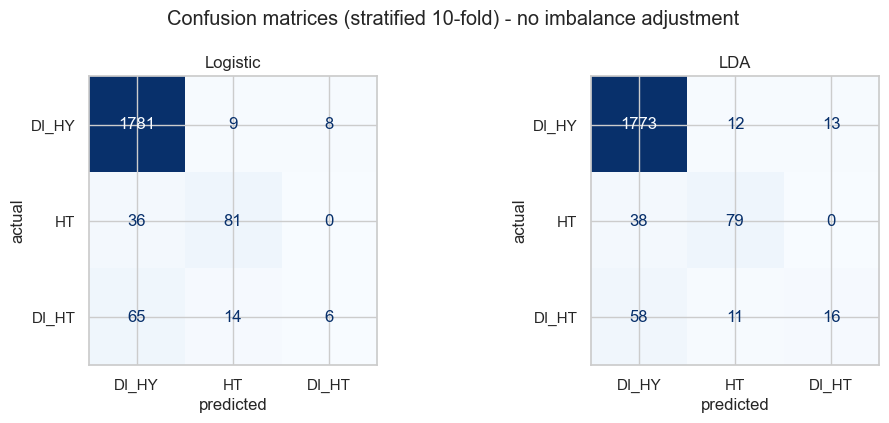

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logistic,0.607,0.584,0.934,0.991,0.692,0.071
LDA,0.656,0.617,0.934,0.986,0.675,0.188
baseline (always DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


In [56]:
MODELS = {
    'Logistic':          lambda: LogisticRegression(max_iter=5000),
    'LDA':                lambda: LinearDiscriminantAnalysis(),
    'Logistic (weighted)':  lambda: LogisticRegression(max_iter=5000, class_weight='balanced'),
    'LDA (equal priors)': lambda: LinearDiscriminantAnalysis(priors=[1/3] * 3),
}

def ajustar(fabrica, X_tr, y_tr):
    """Standardizes with the training statistics and fits the model.
    Written by hand instead of a Pipeline, so the scaling stays inside each fold."""
    escala = StandardScaler().fit(X_tr)
    modelo = fabrica().fit(escala.transform(X_tr), y_tr)
    return lambda X_novo: modelo.predict(escala.transform(X_novo))

def prever_por_cv(fabrica, cv):
    """Manual equivalent of cross_val_predict: every observation is predicted
    by the model fitted without it."""
    previsto = pd.Series(index=y.index, dtype=object)
    for idx_treino, idx_teste in cv.split(X, y):
        prever = ajustar(fabrica, X.iloc[idx_treino], y.iloc[idx_treino])
        previsto.iloc[idx_teste] = prever(X.iloc[idx_teste])
    return previsto.to_numpy()

def pontuacoes_por_fold(fabrica, cv):
    """Manual equivalent of cross_validate: macro F1 and balanced accuracy on each fold."""
    linhas = []
    for idx_treino, idx_teste in cv.split(X, y):
        prever = ajustar(fabrica, X.iloc[idx_treino], y.iloc[idx_treino])
        p = prever(X.iloc[idx_teste])
        linhas.append({'f1_macro': f1_score(y.iloc[idx_teste], p, average='macro'),
                        'bal_acc': balanced_accuracy_score(y.iloc[idx_teste], p)})
    return pd.DataFrame(linhas)
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def show_confusions(names, preds, title):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.3))
    for ax, n in zip(np.atleast_1d(axes), names):
        ConfusionMatrixDisplay(confusion_matrix(y, preds[n], labels=CLASSES), display_labels=CLASSES).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(n); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
    fig.suptitle(title); plt.tight_layout(); plt.show()

cv_preds = {n: prever_por_cv(m, CV10) for n, m in MODELS.items()}
show_confusions(['Logistic', 'LDA'], cv_preds, 'Confusion matrices (stratified 10-fold) - no imbalance adjustment')
first = pd.DataFrame({n: metrics(y, cv_preds[n]) for n in ['Logistic', 'LDA']}).T
first.loc['baseline (always DI_HY)'] = metrics(y, baseline_pred)
first

**Conclusions: the hypothesis is confirmed.** Without adjustments, both models predict `DI_HY` almost always.

| | Macro F1 | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|---|---|
| Baseline (always `DI_HY`) | 0.316 | 0.333 | 0.899 | 1.000 | 0.000 | 0.000 |
| Logistic | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | **0.071** |
| LDA | **0.656** | **0.617** | 0.934 | 0.986 | 0.675 | **0.188** |

- **`DI_HY`** is recognised almost always (recall ≈ 0.99).
- **`HT`** is reasonably well detected (recall ≈ 0.68–0.69 for both models), thanks to `HbA1c_level`, which
  separates this class well.
- **`DI_HT`** is almost never detected. Logistic Regression gets only 6 of the 85 patients right (7%); LDA gets 16
  (19%). In the confusion matrix, most `DI_HT` appear as `DI_HY`.
- *Accuracy* (0.93) looks excellent, but it is measuring mostly the majority class.

**Justification - why does this happen?** Both methods aim to minimise the **total** error. With 1798 `DI_HY` against
85 `DI_HT`, and with `DI_HT` heavily overlapping `DI_HY` (EDA), the "cheapest" way to make few errors is to classify
uncertain cases as `DI_HY`. In LDA this is explicit: the prior probability of `DI_HY` is 0.90 versus 0.04 for `DI_HT`,
and Bayes' rule favours the more frequent class.

**Why does LDA detect more `DI_HT` than Logistic Regression?** LDA uses the covariance structure of all classes at
once (the class means and a common covariance). When a class has few examples, this gives more stable estimates than
Logistic Regression, which fits separate coefficients for each class from the few cases available.

### 11.3 Correcting the imbalance

The problem in 11.2 has a known cause for each method:
- in **Logistic Regression**, the likelihood is a sum over all patients. With 1798 `DI_HY` against 85 `DI_HT`,
  misclassifying a `DI_HT` costs almost nothing in total. With `class_weight='balanced'`, each patient is weighted by
  the inverse of their class frequency: a `DI_HT` becomes worth ~21 times a `DI_HY`;
- in **LDA**, Bayes' rule multiplies the likelihood by the prior probability πₖ. With π(`DI_HY`) = 0.90 and
  π(`DI_HT`) = 0.04, a patient is only classified as `DI_HT` if the evidence is very strong. With **equal priors**
  (1/3 each), the decision depends only on the similarity to each class.

We compare the 4 versions using the same cross-validation partitions.

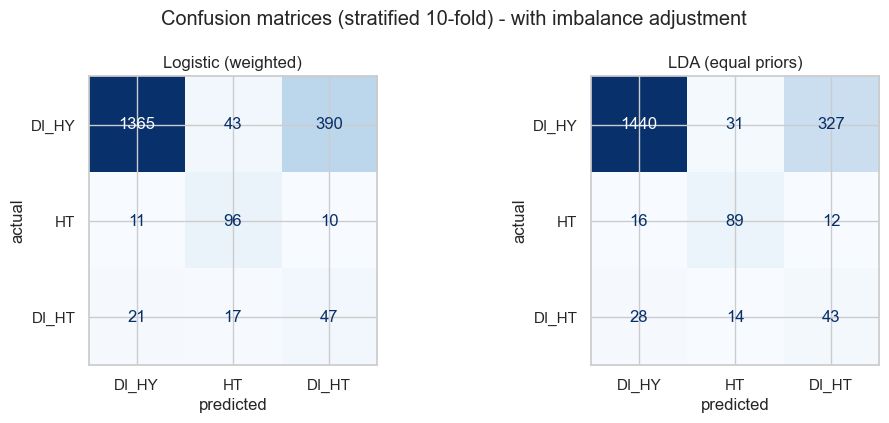

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,precision_DI_HT,n_predicted_DI_HT
Logistic,0.607,0.584,0.934,0.991,0.692,0.071,0.429,14.000
LDA,0.656,0.617,0.934,0.986,0.675,0.188,0.552,29.000
Logistic (weighted),0.578,0.711,0.754,0.759,0.821,0.553,0.105,447.000
LDA (equal priors),0.590,0.689,0.786,0.801,0.761,0.506,0.113,382.000


In [57]:
show_confusions(['Logistic (weighted)', 'LDA (equal priors)'], cv_preds,
                'Confusion matrices (stratified 10-fold) - with imbalance adjustment')
versions = pd.DataFrame({n: metrics(y, p) for n, p in cv_preds.items()}).T
for n, p in cv_preds.items():
    versions.loc[n, 'precision_DI_HT'] = precision_score(y, p, labels=['DI_HT'], average='macro', zero_division=0)
    versions.loc[n, 'n_predicted_DI_HT'] = (p == 'DI_HT').sum()
versions

**Conclusions:** the adjusted versions detect many more minority-class patients, but at a price.

| | Macro F1 | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` | Precision `DI_HT` | No. predicted `DI_HT` |
|---|---|---|---|---|---|---|---|---|
| Logistic | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | 0.071 | 0.429 | 14 |
| LDA | **0.656** | 0.617 | **0.934** | 0.986 | 0.675 | 0.188 | **0.552** | 29 |
| Logistic (weighted) | 0.578 | **0.711** | 0.754 | 0.759 | **0.821** | **0.553** | 0.105 | 447 |
| LDA (equal priors) | 0.590 | 0.689 | 0.786 | 0.801 | 0.761 | 0.506 | 0.113 | 382 |

- **Gain:** the recall of `DI_HT` rises from 0.07 to **0.55** (Logistic) and from 0.19 to **0.51** (LDA). The recall
  of `HT` also increases. *Balanced accuracy* improves a lot (0.58 → 0.71 and 0.62 → 0.69).
- **Cost:** to find more `DI_HT`, the models start classifying many `DI_HY` patients as `DI_HT`. The weighted
  Logistic model predicts 447 `DI_HT` when only 85 exist. **`DI_HT` precision drops to ≈ 0.11** (only 1 in 9 `DI_HT`
  predictions is right) and *accuracy* falls to 0.75–0.79.
- **Macro F1 drops slightly**, because it combines recall and precision: the gain in minority-class recall is offset
  by the drop in `DI_HT` precision and `DI_HY` recall.

**Justification - why is there "no free lunch"?** The `DI_HT` and `DI_HY` classes overlap heavily (EDA). Changing
weights or priors **does not create new information**: it only moves the decision boundary. In the overlap region,
either the `DI_HT` are lost (unadjusted versions) or they are caught together with many `DI_HY` (adjusted versions).
It is the same trade-off obtained by lowering the decision threshold of a classifier.

**Which version is better?** It depends on which error is more costly:
- if the goal is **not to miss** `DI_HT`/`HT` patients (screening), the adjusted versions are preferable;
- if the goal is **to avoid false diagnoses**, the unadjusted versions are preferable.

Since the imbalance is the central feature of this problem, and the assignment asks for appropriate metrics, **we
always compare both methods in both versions** in the following sections.

### 11.4 Which version to use? Comparison with statistical significance

The differences between versions may be small. To know whether they are **real** or due to which patients fell into
each fold, we compute macro F1 and *balanced accuracy* on **each of the 10 folds**, using
the **same partitions** for all models, and apply a **paired *t*-test** between models.

In [58]:
fold_scores = {}
for n, m in MODELS.items():
    fold_scores[n] = pontuacoes_por_fold(m, CV10)

summary = pd.DataFrame({n: {'F1 macro (mean)': s.f1_macro.mean(), 'F1 macro (sd)': s.f1_macro.std(),
                            'Bal. acc. (mean)': s.bal_acc.mean(), 'Bal. acc. (sd)': s.bal_acc.std()}
                        for n, s in fold_scores.items()}).T
display(summary)

pairs = [('LDA', 'Logistic'), ('LDA (equal priors)', 'Logistic (weighted)'),
         ('Logistic (weighted)', 'Logistic'), ('LDA (equal priors)', 'LDA')]
tests = []
for a, b in pairs:
    for met in ('f1_macro', 'bal_acc'):
        d = fold_scores[a][met] - fold_scores[b][met]
        tests.append({'comparison': f'{a}  vs  {b}', 'metric': met, 'mean difference': d.mean(),
                      'folds where A > B': f'{(d > 0).sum()}/10', 'p-value (paired t)': stats.ttest_rel(
                          fold_scores[a][met], fold_scores[b][met]).pvalue})
pd.DataFrame(tests)

,F1 macro (mean),F1 macro (sd),Bal. acc. (mean),Bal. acc. (sd)
Logistic,0.604,0.048,0.585,0.038
LDA,0.651,0.048,0.616,0.040
Logistic (weighted),0.579,0.037,0.713,0.062
LDA (equal priors),0.592,0.044,0.690,0.047


,comparison,metric,mean difference,folds where A > B,p-value (paired t)
0,LDA vs Logistic,f1_macro,0.047,7/10,0.054
1,LDA vs Logistic,bal_acc,0.031,7/10,0.119
2,LDA (equal priors) vs Logistic (weighted),f1_macro,0.013,7/10,0.369
3,LDA (equal priors) vs Logistic (weighted),bal_acc,-0.023,3/10,0.297
4,Logistic (weighted) vs Logistic,f1_macro,-0.025,4/10,0.183
5,Logistic (weighted) vs Logistic,bal_acc,0.128,10/10,0.000
6,LDA (equal priors) vs LDA,f1_macro,-0.059,2/10,0.043
7,LDA (equal priors) vs LDA,bal_acc,0.074,8/10,0.017


**Conclusions:**

| Comparison | Macro F1 | Balanced accuracy |
|---|---|---|
| **LDA vs Logistic** (unadjusted) | LDA +0.047, better in 7/10 folds, **p = 0.054** | LDA +0.031, 7/10 folds, p = 0.119 |
| **LDA (equal priors) vs Logistic (weighted)** | LDA +0.013, 7/10 folds, p = 0.369 | Logistic +0.023, 7/10 folds, p = 0.297 |
| Logistic (weighted) vs Logistic | −0.025, p = 0.183 | **+0.128, 10/10 folds, p < 0.001** |
| LDA (equal priors) vs LDA | **−0.059, p = 0.043** | **+0.074, p = 0.017** |

- **Without adjustment, LDA beats Logistic Regression on macro F1** in 7 of the 10 folds (+0.047), but the
  difference is **borderline significant** (p = 0.054, just above 0.05).
- **With adjustment, the two methods are statistically tied**: LDA has a slightly higher macro F1 and Logistic
  Regression a slightly higher *balanced accuracy*, but neither difference is significant (p > 0.29).
- **Adjusting for imbalance** always improves *balanced accuracy* significantly (Logistic Regression improves in all 10
  folds), at the cost of a small drop in macro F1 (significant for LDA).

**Justification:** a paired test compares the two models **on the same folds**, removing the variability that comes
from which patients fell into each fold. This is why it can detect differences that means alone do not show. The
between-fold standard deviations (0.037–0.062) are of the same order as the differences between models, which is why
most of the LDA vs Logistic differences are not significant. Since the 10 folds share training data, they are not
fully independent, and the p-values should be read as indicative.

## 12. Resampling methods

The assignment asks for four ways of estimating performance on new patients. They all answer the same question
(*"how will the model perform on data it has never seen?"*), but in different ways, with different **cost, bias and
variance**.

| Method | Training in each repetition | Test | No. of models |
|---|---|---|---|
| *Holdout* | 70% (1400) | 30% (600), once | 1 |
| *k-fold* (k = 5 / 10) | (k−1)/k of the data (1600 / 1800) | each fold once | 5 / 10 |
| LOOCV | 1999 | 1 patient, 2000 times | 2000 |
| *Bootstrap* OOB | 2000 drawn with replacement (~63% distinct) | the ~37% left out | 200 |

**Precautions common to all methods:**
- standardisation (`StandardScaler`) is inside a *pipeline*, so it is fitted **only on the training data of each
  repetition**. Fitting it on all the data would leak information from the test set into training;
- whenever possible we use **stratification**, so that every class is represented in the test set;
- we evaluate **all four models** from section 11 with every method.

### 12.1 *Holdout* (validation set approach)

**How it works:** the data are split once into training (70%) and test (30%); the model learns on the
training set and is evaluated on the test set. We use a **stratified** split so that the 3 classes appear in the test
set in the same proportions as in the dataset: with only 85 `DI_HT`, a non-stratified split could leave the test set
with very few of them.

We show the full report (`classification_report`) for the four models.

In [59]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print('Test:', y_te.value_counts().to_dict())
holdout = {}
for n, m in MODELS.items():
    pred = ajustar(m, X_tr, y_tr)(X_te)
    holdout[n] = metrics(y_te, pred)
    if n in ('Logistic (weighted)', 'LDA (equal priors)'):
        print(f'\n=== {n} ===')
        print(classification_report(y_te, pred, labels=CLASSES, digits=3, zero_division=0))
pd.DataFrame(holdout).T

Test: {'DI_HY': 539, 'HT': 35, 'DI_HT': 26}

=== Logistic (weighted) ===
              precision    recall  f1-score   support

       DI_HY      0.969     0.800     0.876       539
          HT      0.508     0.857     0.638        35
       DI_HT      0.062     0.231     0.098        26

    accuracy                          0.778       600
   macro avg      0.513     0.629     0.538       600
weighted avg      0.902     0.778     0.828       600


=== LDA (equal priors) ===
              precision    recall  f1-score   support

       DI_HY      0.967     0.861     0.911       539
          HT      0.588     0.857     0.698        35
       DI_HT      0.116     0.308     0.168        26

    accuracy                          0.837       600
   macro avg      0.557     0.675     0.592       600
weighted avg      0.908     0.837     0.866       600



,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logistic,0.581,0.606,0.937,0.989,0.829,0.000
LDA,0.609,0.602,0.932,0.985,0.743,0.077
Logistic (weighted),0.538,0.629,0.778,0.800,0.857,0.231
LDA (equal priors),0.592,0.675,0.837,0.861,0.857,0.308


**Conclusions:** the test set has 539 `DI_HY`, 35 `HT` and only **26 `DI_HT`**.

| | Macro F1 | Bal. acc. | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|
| Logistic | 0.581 | 0.606 | 0.829 | **0.000** |
| LDA | 0.609 | 0.602 | 0.743 | 0.077 |
| Logistic (weighted) | 0.538 | 0.629 | 0.857 | 0.231 |
| LDA (equal priors) | **0.592** | **0.675** | 0.857 | **0.308** |

- The reports show the same pattern as in section 11: `DI_HY` and `HT` are well identified (F1 of 0.88–0.91 and
  0.64–0.70), and **`DI_HT` is the problematic class** (F1 0.10–0.17, precision 0.06–0.12).
- Unadjusted Logistic Regression **identifies none of the 26 `DI_HT`** in the test set.
- In this particular *holdout*, LDA with equal priors is the best on both main metrics.

**Justification - why distrust a single *holdout*?** The results differ from those of cross-validation (e.g. the
`DI_HT` recall of weighted Logistic Regression is 0.23 here versus 0.55 in 10-fold). With only 26 `DI_HT` in the
test set, **each `DI_HT` patient correctly classified or missed changes the recall by ~4 percentage points**. The
estimate depends heavily on which patients ended up in the test set, which we measure next.

### 12.2 How much does the *holdout* vary? Repeating the split 100 times

The result of a *holdout* depends on **which** patients ended up in the test set: the estimate has variance, and a
different split gives a different result. To measure this variance, we repeat the
stratified *holdout* with **100 different seeds** and look at how the metrics are distributed.

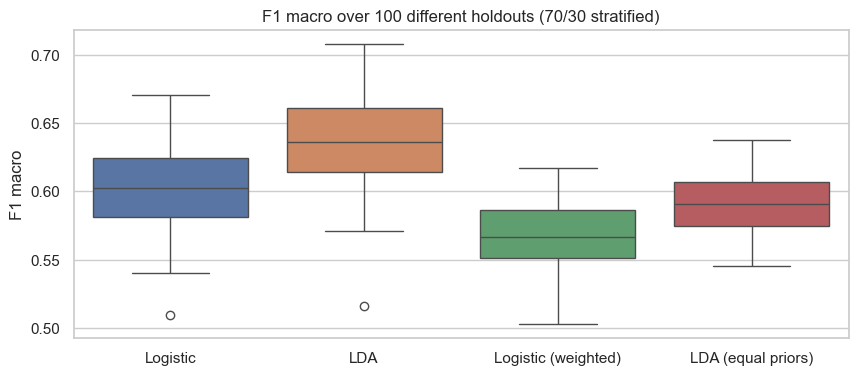

,mean,sd,min,max,recall DI_HT sd
Logistic,0.604,0.032,0.509,0.671,0.048
LDA,0.638,0.035,0.516,0.708,0.064
Logistic (weighted),0.567,0.024,0.503,0.617,0.104
LDA (equal priors),0.590,0.021,0.546,0.637,0.102


In [60]:
def repeated_holdout(model, n_rep=100, test_size=0.30):
    out = []
    for s in range(n_rep):
        a, b, c, d = train_test_split(X, y, test_size=test_size, stratify=y, random_state=s)
        out.append(metrics(d, ajustar(model, a, c)(b)))
    return pd.DataFrame(out)

rep_holdout = {n: repeated_holdout(MODELS[n]) for n in MODELS}
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame({n: r.f1_macro for n, r in rep_holdout.items()}), ax=ax)
ax.set_ylabel('F1 macro'); ax.set_title('F1 macro over 100 different holdouts (70/30 stratified)')
plt.show()
pd.DataFrame({n: {'mean': r.f1_macro.mean(), 'sd': r.f1_macro.std(), 'min': r.f1_macro.min(),
                  'max': r.f1_macro.max(), 'recall DI_HT sd': r.recall_DI_HT.std()}
              for n, r in rep_holdout.items()}).T

**Conclusions:** repeating the *holdout* 100 times shows that **the same methodology gives very different results
depending on the split**:

| | Mean macro F1 | Standard deviation | Minimum | Maximum | sd of `DI_HT` recall |
|---|---|---|---|---|---|
| Logistic | 0.604 | 0.032 | 0.509 | 0.671 | 0.048 |
| LDA | 0.638 | 0.035 | 0.516 | 0.708 | 0.064 |
| Logistic (weighted) | 0.567 | 0.024 | 0.503 | 0.617 | **0.104** |
| LDA (equal priors) | 0.590 | **0.021** | 0.546 | 0.637 | **0.102** |

- The macro F1 of LDA ranges between **0.52 and 0.71** depending on the split: a difference of 0.19 purely by
  chance.
- The recall of `DI_HT` has a standard deviation of **0.10**: it can be 0.3 in one split and 0.6 in another.
- The single *holdout* in section 12.1 (0.538 for weighted Logistic Regression) is **below the mean** of the 100
  repetitions (0.567). Had we only made that split, we would have underestimated the model.

**Justification - where does this variance come from?**
1. **Small test set for the rare classes:** only ~26 `DI_HT` and ~35 `HT` in each test set, so a few patients change
   the per-class metrics a lot.
2. **Reduced training set:** the model learns from 70% of the data, i.e. only ~60 `DI_HT`. Different splits produce
   different models.
3. **A single measurement:** there is no average over several evaluations to "smooth out" chance.

Interestingly, the adjusted versions have a **more stable** macro F1 (sd 0.021–0.024) than the unadjusted ones
(0.032–0.035). Without adjustment, the `DI_HT` F1 depends on getting a handful of cases right, and swings between
close to 0 and reasonable values from split to split.

### 12.3 *k-fold* cross-validation (k = 5 and k = 10)

**How it works:** the data are divided into *k* parts (*folds*); each fold serves once as the test
set while the other *k−1* train the model. Every patient is tested **exactly once**. We use the **stratified** version:
with imbalanced classes, each fold keeps the class proportions.

There are **two kinds of variance** to distinguish:
1. **Between folds:** how much the *k* metrics vary within a single cross-validation;
2. **Of the estimate:** how much the final **mean** changes if we repeat the cross-validation with another random
   partition. We repeat it 20 times, with 20 seeds.

In [61]:
def repeated_kfold(model, k, n_rep=20):
    fold_level, means = [], []
    for s in range(n_rep):
        cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=s)
        r = pontuacoes_por_fold(model, cv)
        fold_level.append(r.f1_macro.to_numpy())
        means.append({'f1_macro': r.f1_macro.mean(), 'bal_acc': r.bal_acc.mean()})
    return np.concatenate(fold_level), pd.DataFrame(means)

kfold = {}
for k in (5, 10):
    for n in MODELS:
        folds, means = repeated_kfold(MODELS[n], k)
        kfold[(k, n)] = {'folds': folds, 'means': means}

kfold_table = pd.DataFrame({f'{k}-fold | {n}': {
    'F1 macro (estimate)': v['means'].f1_macro.mean(),
    'sd between folds': v['folds'].std(),
    'sd of estimate (20 repeats)': v['means'].f1_macro.std(),
    'Bal. acc. (estimate)': v['means'].bal_acc.mean()} for (k, n), v in kfold.items()}).T
kfold_table

,F1 macro (estimate),sd between folds,sd of estimate (20 repeats),Bal. acc. (estimate)
5-fold | Logistic,0.608,0.039,0.010,0.586
5-fold | LDA,0.642,0.049,0.010,0.608
5-fold | Logistic (weighted),0.573,0.025,0.007,0.707
5-fold | LDA (equal priors),0.586,0.027,0.006,0.682
10-fold | Logistic,0.612,0.058,0.010,0.591
10-fold | LDA,0.647,0.068,0.009,0.613
10-fold | Logistic (weighted),0.575,0.038,0.004,0.709
10-fold | LDA (equal priors),0.586,0.040,0.006,0.683


**Conclusions:**

| | Macro F1 estimate | sd between folds | sd of estimate (20 rep.) | Bal. acc. |
|---|---|---|---|---|
| 5-fold · Logistic (weighted) | 0.573 | 0.025 | 0.007 | 0.707 |
| 5-fold · LDA (equal priors) | 0.586 | 0.027 | 0.006 | 0.682 |
| 10-fold · Logistic (weighted) | 0.575 | 0.038 | **0.004** | 0.709 |
| 10-fold · LDA (equal priors) | 0.586 | 0.040 | 0.006 | 0.683 |
| 10-fold · LDA (unadjusted) | **0.647** | 0.068 | 0.009 | 0.613 |

1. **The cross-validation estimate is much more stable than the *holdout* estimate.** Repeating with another
   partition, the 10-fold mean changes by only 0.004–0.010 (standard deviation), versus 0.021–0.035 for the
   *holdout*: a **3- to 6-fold reduction**. This is because the mean of *k* evaluations cancels much of the chance
   effect, and because **every patient is used as test data** once.
2. **Between-fold variability is higher with k = 10 than with k = 5** (e.g. 0.038 vs 0.025). With k = 10, each test
   fold has only ~200 patients and ~8–9 `DI_HT`, so each individual evaluation is "noisier".
3. **Even so, the final estimate is as stable or more stable with k = 10**, because it averages more evaluations.
4. **The estimate rises slightly from k = 5 to k = 10** (0.573 → 0.575 for weighted Logistic Regression). With
   k = 10 the model trains on 1800 patients instead of 1600 and learns the rare classes slightly better: k = 5 is
   slightly more **pessimistic**.
5. **The ranking of the models is preserved:** LDA > Logistic on macro F1, weighted Logistic > LDA (equal priors) on
   *balanced accuracy*.

### 12.4 *Leave-One-Out* (LOOCV)

**How it works:** it is the extreme case of *k-fold*, with *k = N* = 2000. The model is trained 2000
times, always with 1999 patients, and tested on the patient left out.

Two important particularities:
- each fold has **a single patient**, so a "per-fold F1" does not exist (with a single prediction you can only be
  right or wrong). The metrics are computed by pooling the 2000 predictions;
- LOOCV is **deterministic**: there is only one way to leave each patient out, so repeating it always gives the same
  result. It also cannot be stratified.

In [62]:
loo_preds, loo_time = {}, {}
for n, m in MODELS.items():
    t0 = time.time()
    loo_preds[n] = prever_por_cv(m, LeaveOneOut())
    loo_time[n] = time.time() - t0
loo_table = pd.DataFrame({n: {**metrics(y, p), 'time (s)': loo_time[n], 'n models trained': len(y)}
                          for n, p in loo_preds.items()}).T
loo_table

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,time (s),n models trained
Logistic,0.628,0.596,0.935,0.991,0.692,0.106,69.438,2000.000
LDA,0.662,0.621,0.935,0.987,0.675,0.200,11.592,2000.000
Logistic (weighted),0.575,0.706,0.746,0.750,0.803,0.565,83.006,2000.000
LDA (equal priors),0.585,0.681,0.780,0.795,0.752,0.494,10.866,2000.000


**Conclusions:**

| | Macro F1 | Bal. acc. | Recall `DI_HT` | Time |
|---|---|---|---|---|
| Logistic | 0.628 | 0.596 | 0.106 | ~69 s |
| LDA | **0.662** | 0.621 | 0.200 | ~12 s |
| Logistic (weighted) | 0.575 | **0.706** | **0.565** | ~83 s |
| LDA (equal priors) | 0.585 | 0.681 | 0.494 | ~11 s |

- For the unadjusted versions, LOOCV gives the **highest** estimates of all methods (e.g. LDA 0.662 vs 0.647 in
  10-fold and 0.638 for the *holdout* ×100). Each model trains on 1999 patients, almost the full dataset, so it is the
  **least pessimistic (least biased)** method. For the adjusted versions, LOOCV is practically equal to 10-fold
  (0.575 and 0.585 versus 0.575 and 0.586).
- The conclusions are the same: without adjustment LDA is better; with adjustment LDA has the better macro F1 and
  Logistic Regression the better *balanced accuracy*.
- The cost was 11 to 83 seconds per model, with **LDA 6 to 8 times faster** than Logistic. The loop of 2000 fits runs serially, and the absolute times depend on the machine and vary between runs; what stays constant is the ratio between the models. Even so it is little, because these models
  are fast to train. With heavier models, 2000 fits per model would be prohibitive.

**Variance of LOOCV:**
- **Repeating LOOCV always gives the same result** (partition variance = 0): there is only one way to leave each
  patient out.
- However, **this does not mean the estimate is precise**. The 2000 models are almost identical (they differ by one
  patient), so their errors are highly correlated. According to theory (ISLP, 5.1.4), the LOOCV estimate has **high
  variance with respect to the true error**: had we collected another 2000 patients, the LOOCV result could change
  considerably.
- It is also **not possible to stratify** and there is no "per-fold metric" (each fold has a single patient), so
  there is no way to measure the spread from the results themselves.

### 12.5 *Bootstrap* with *out-of-bag* (OOB) evaluation

**How it works:** at each iteration we draw a sample **with replacement**
of the same size as the dataset (2000). Some patients appear repeated and others are left out; the probability of a
patient being left out is $(1 - 1/N)^N \approx e^{-1} \approx 36.8\%$. The model trains on the *bootstrap* sample
and is evaluated on the left-out (*out-of-bag*) patients, which it never saw.

We repeat this **200 times** and obtain the distribution of the metrics, the mean, the
standard deviation and a 95% confidence interval (2.5th and 97.5th percentiles).

In [63]:
def bootstrap_oob(model, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(y))
    out = []
    for _ in range(B):
        inb = rng.choice(idx_all, size=len(y), replace=True)
        oob = np.setdiff1d(idx_all, inb)
        prever = ajustar(model, X.iloc[inb], y.iloc[inb])
        out.append({**metrics(y.iloc[oob], prever(X.iloc[oob])), 'oob_frac': len(oob) / len(y),
                    'n_DI_HT_oob': (y.iloc[oob] == 'DI_HT').sum()})
    return pd.DataFrame(out)

boot = {n: bootstrap_oob(MODELS[n]) for n in MODELS}
boot_table = pd.DataFrame({n: {'F1 macro (mean)': b.f1_macro.mean(), 'sd': b.f1_macro.std(),
                               'IC95% inf': b.f1_macro.quantile(.025), 'IC95% sup': b.f1_macro.quantile(.975),
                               'Bal. acc. (mean)': b.bal_acc.mean(), 'mean OOB fraction': b.oob_frac.mean(),
                               'n DI_HT in OOB (mean)': b.n_DI_HT_oob.mean()} for n, b in boot.items()}).T
boot_table

,F1 macro (mean),sd,IC95% inf,IC95% sup,Bal. acc. (mean),mean OOB fraction,n DI_HT in OOB (mean)
Logistic,0.615,0.030,0.563,0.689,0.592,0.367,30.565
LDA,0.640,0.029,0.580,0.701,0.605,0.367,30.565
Logistic (weighted),0.561,0.022,0.521,0.606,0.695,0.367,30.565
LDA (equal priors),0.592,0.021,0.546,0.629,0.687,0.367,30.565


**Conclusions:**

| | Mean macro F1 | sd | 95% CI | Bal. acc. |
|---|---|---|---|---|
| Logistic | 0.615 | 0.030 | [0.563, 0.689] | 0.592 |
| LDA | **0.640** | 0.029 | [0.580, 0.701] | 0.605 |
| Logistic (weighted) | 0.561 | 0.022 | [0.521, 0.606] | **0.695** |
| LDA (equal priors) | 0.592 | **0.021** | [0.546, 0.629] | 0.687 |

- The mean fraction of *out-of-bag* patients is **0.367**, exactly the theoretical value $e^{-1} \approx 0.368$.
  Each OOB set contains on average ~31 `DI_HT`.
- The *bootstrap* returns a **full distribution** and a **confidence interval** for the performance. The LDA and
  Logistic intervals overlap considerably, confirming that the differences between the two methods are modest.
- For weighted Logistic Regression, the estimate is **lower** than that of 10-fold and LOOCV: 0.561 versus 0.575.

**Justification - why is the *bootstrap* pessimistic?** Each *bootstrap* sample has 2000 patients, but only ~63% are
**distinct** (the rest are repetitions). In practice the model learns from ~1264 different patients, fewer than in
5-fold (1600). This affects Logistic Regression more, since it needs varied examples of the rare classes to estimate
its coefficients. LDA, which only needs means and a common covariance, is less affected (0.592 vs 0.586 in 10-fold).

## 13. How does the resampling method affect the variance?

This is the central question of the assignment: *"indicate how the variance is affected by the resampling methods
used"*. Here we bring together the results of sections 12.1–12.5.

### 13.1 Side-by-side comparison

For each method and model we show:
- the macro F1 **estimate**;
- the **variability of the individual evaluations** (between splits, folds or iterations);
- the **variability of the final estimate** (how much the estimate changes if the procedure is repeated);
- the **cost** (number of models trained).

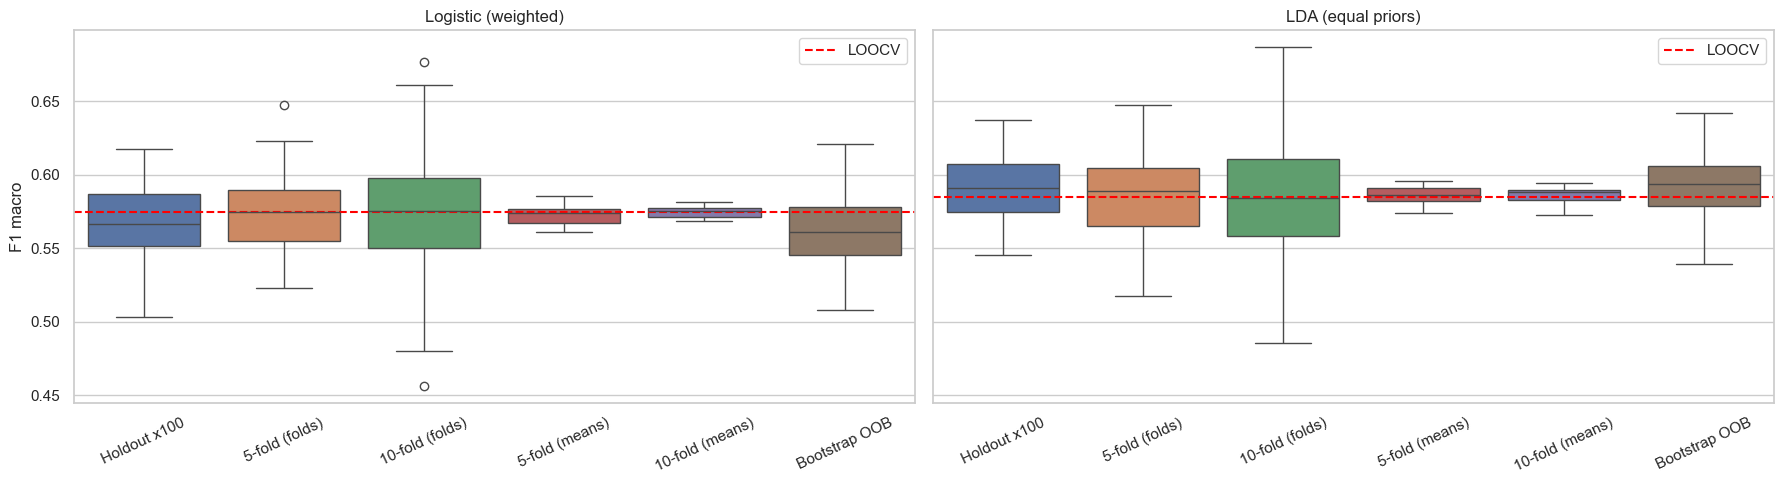

F1 macro  sd of evaluations  \
model               method                                               
Logistic (weighted) Holdout (1 split)         0.538                NaN   
                    5-fold stratified         0.573              0.025   
                    10-fold stratified        0.575              0.038   
                    LOOCV                     0.575                NaN   
                    Bootstrap OOB (B=200)     0.561              0.022   
LDA (equal priors)  Holdout (1 split)         0.592                NaN   
                    5-fold stratified         0.586              0.027   
                    10-fold stratified        0.586              0.040   
                    LOOCV                     0.585                NaN   
                    Bootstrap OOB (B=200)     0.592              0.021   

                                           sd of estimate  n models  
model               method                                           
Logistic (weighted) Holdout (1 split)               0.024         1  
                    5-fold stratified               0.007         5  
                    10-fold stratified              0.004        10  
                    LOOCV                           0.000      2000  
                    Bootstrap OOB (B=200)           0.002       200  
LDA (equal priors)  Holdout (1 split)               0.021         1  
                    5-fold stratified               0.006         5  
                    10-fold stratified              0.006        10  
                    LOOCV                           0.000      2000  
                    Bootstrap OOB (B=200)           0.001       200

In [64]:
rows = []
for n in MODELS:
    rows.append({'model': n, 'method': 'Holdout (1 split)', 'F1 macro': holdout[n]['f1_macro'],
                 'sd of evaluations': np.nan, 'sd of estimate': rep_holdout[n].f1_macro.std(), 'n models': 1})
    for k in (5, 10):
        v = kfold[(k, n)]
        rows.append({'model': n, 'method': f'{k}-fold stratified', 'F1 macro': v['means'].f1_macro.mean(),
                     'sd of evaluations': v['folds'].std(), 'sd of estimate': v['means'].f1_macro.std(), 'n models': k})
    rows.append({'model': n, 'method': 'LOOCV', 'F1 macro': loo_table.loc[n, 'f1_macro'],
                 'sd of evaluations': np.nan, 'sd of estimate': 0.0, 'n models': len(y)})
    rows.append({'model': n, 'method': 'Bootstrap OOB (B=200)', 'F1 macro': boot[n].f1_macro.mean(),
                 'sd of evaluations': boot[n].f1_macro.std(),
                 'sd of estimate': boot[n].f1_macro.std() / np.sqrt(len(boot[n])), 'n models': 200})
variance = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, n in zip(axes, ['Logistic (weighted)', 'LDA (equal priors)']):
    dist = pd.DataFrame({'Holdout x100': rep_holdout[n].f1_macro,
                         '5-fold (folds)': pd.Series(kfold[(5, n)]['folds']),
                         '10-fold (folds)': pd.Series(kfold[(10, n)]['folds']),
                         '5-fold (means)': kfold[(5, n)]['means'].f1_macro,
                         '10-fold (means)': kfold[(10, n)]['means'].f1_macro,
                         'Bootstrap OOB': boot[n].f1_macro})
    sns.boxplot(data=dist, ax=ax); ax.axhline(loo_table.loc[n, 'f1_macro'], color='red', ls='--', label='LOOCV')
    ax.set_title(n); ax.tick_params(axis='x', rotation=25); ax.legend()
axes[0].set_ylabel('F1 macro')
plt.tight_layout(); plt.show()
variance[variance.model.isin(['Logistic (weighted)', 'LDA (equal priors)'])].set_index(['model', 'method'])

**Conclusions (adjusted versions; the unadjusted versions follow the same pattern):**

| Method | F1 estimate (Log. weighted / LDA priors) | sd of evaluations | **sd of estimate** | No. of models |
|---|---|---|---|---|
| *Holdout* (1 split) | 0.538 / 0.592 | - | **0.024 / 0.021** | 1 |
| Stratified 5-fold | 0.573 / 0.586 | 0.025 / 0.027 | 0.007 / 0.006 | 5 |
| Stratified 10-fold | 0.575 / 0.586 | 0.038 / 0.040 | 0.004 / 0.006 | 10 |
| LOOCV | 0.575 / 0.585 | - | 0 (deterministic) | 2000 |
| *Bootstrap* OOB (B = 200) | 0.561 / 0.592 | 0.022 / 0.021 | 0.002 / 0.001 | 200 |

*The bootstrap "sd of estimate" is the standard error of the mean over the 200 iterations ($sd/\sqrt{200}$).*

**How does the resampling method affect the variance?**

1. ***Holdout*: the estimate with the highest variance.** It is a single measurement on a test set of 600 patients
   with ~26 `DI_HT`. The split alone can change macro F1 by ±0.04–0.05 (two standard deviations). As we saw, the
   single *holdout* fell below the mean of the repetitions.
2. ***k-fold*: much lower variance**, because each patient is tested once and the result is the mean of *k*
   evaluations. The estimate is **3 to 6 times more stable** than the *holdout*. Each individual fold varies more with
   larger *k* (smaller test folds), but the mean becomes more stable.
3. **LOOCV: no partition variance** (it is deterministic), but the 2000 trained models are almost identical and their
   errors are correlated. The estimate has low bias but **high variance with respect to the true error**, which
   cannot be measured from its own results.
4. ***Bootstrap*: the variance of each iteration is similar to that of a *holdout*** (sd 0.021–0.030), but averaging
   200 iterations makes the final estimate very stable. It is the only method that directly provides a **confidence
   interval**. The price is being **pessimistic**, because each model trains on only ~63% distinct patients.

**The plot** shows this visually: the boxes for individual evaluations (*holdout* ×100, folds, *bootstrap*) are wide,
while those for the 5-fold and 10-fold **means** are very narrow.

**Bias:** the less data the model uses for training, the more pessimistic the estimate. The ranking of the weighted
Logistic estimates follows this logic: *bootstrap* (~63% distinct patients) 0.561 < 5-fold (80%) 0.573 < 10-fold
(90%) 0.575 ≈ LOOCV (99.95%) 0.575. The *holdout* (70%) ended up even lower (0.538) due to an unlucky split. From
~90% of the training data onwards, the estimate practically stabilises.

### 13.2 The effect of *k* in cross-validation

Choosing *k* involves a trade-off:
- **small *k*** → each model trains on less data → **pessimistic** (more biased) estimate, but more stable and
  cheaper;
- **large *k*** (in the limit, LOOCV) → training on almost all the data → **low-bias** estimate, but the models are
  very similar to each other and the cost grows.

For *k* ∈ {2, 3, 5, 10, 20}, we measure the mean estimate, the variability **between folds** and the variability **of
the estimate** (10 repetitions with different seeds), for the weighted version of each model.

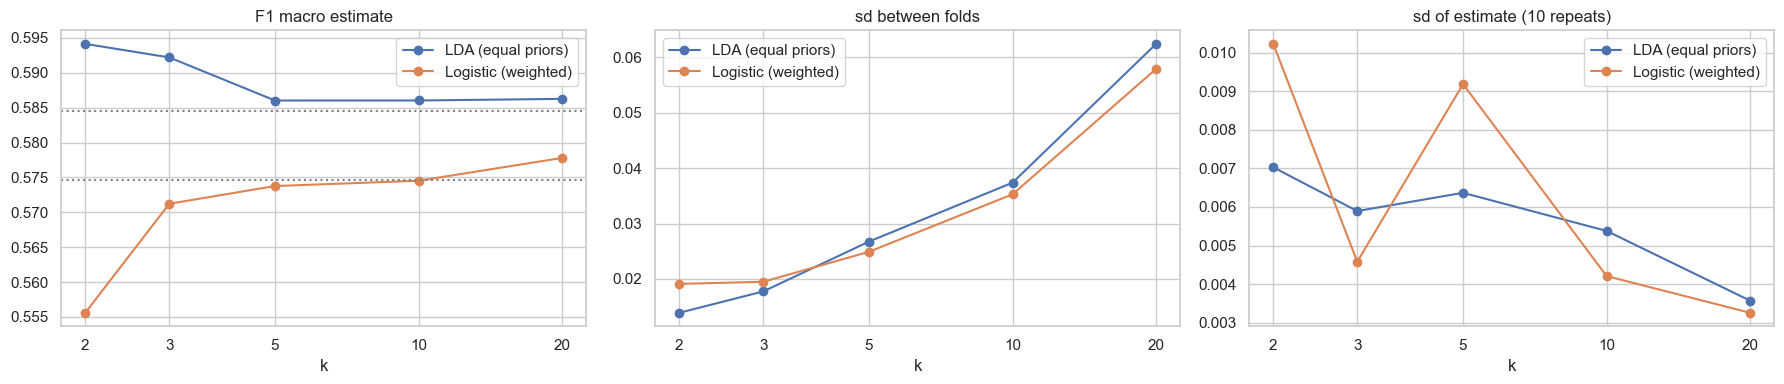

training size  DI_HT per test fold  F1 macro  \
model               k                                                  
Logistic (weighted) 2            1000               42.500     0.556   
                    3            1333               28.300     0.571   
                    5            1600               17.000     0.574   
                    10           1800                8.500     0.575   
                    20           1900                4.200     0.578   
LDA (equal priors)  2            1000               42.500     0.594   
                    3            1333               28.300     0.592   
                    5            1600               17.000     0.586   
                    10           1800                8.500     0.586   
                    20           1900                4.200     0.586   

                        sd between folds  sd of estimate  
model               k                                     
Logistic (weighted) 2              0.019           0.010  
                    3              0.019           0.005  
                    5              0.025           0.009  
                    10             0.035           0.004  
                    20             0.058           0.003  
LDA (equal priors)  2              0.014           0.007  
                    3              0.018           0.006  
                    5              0.027           0.006  
                    10             0.037           0.005  
                    20             0.062           0.004

In [65]:
k_rows = []
for n in ['Logistic (weighted)', 'LDA (equal priors)']:
    for k in (2, 3, 5, 10, 20):
        folds, means = repeated_kfold(MODELS[n], k, n_rep=10)
        k_rows.append({'model': n, 'k': k, 'training size': int(len(y) * (k - 1) / k),
                       'DI_HT per test fold': round(85 / k, 1), 'F1 macro': means.f1_macro.mean(),
                       'sd between folds': folds.std(), 'sd of estimate': means.f1_macro.std()})
k_effect = pd.DataFrame(k_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for n, g in k_effect.groupby('model'):
    axes[0].plot(g.k, g['F1 macro'], marker='o', label=n)
    axes[1].plot(g.k, g['sd between folds'], marker='o', label=n)
    axes[2].plot(g.k, g['sd of estimate'], marker='o', label=n)
for ax, t in zip(axes, ['F1 macro estimate', 'sd between folds', 'sd of estimate (10 repeats)']):
    ax.set_xlabel('k'); ax.set_title(t); ax.set_xscale('log'); ax.set_xticks([2, 3, 5, 10, 20]); ax.set_xticklabels([2, 3, 5, 10, 20]); ax.legend()
for n in ['Logistic (weighted)', 'LDA (equal priors)']:
    axes[0].axhline(loo_table.loc[n, 'f1_macro'], ls=':', color='grey')
plt.tight_layout(); plt.show()
k_effect.set_index(['model', 'k'])

**Conclusions:**

| k | Training | `DI_HT` per fold | F1 Log. (weighted) | F1 LDA (priors) | sd between folds | sd of estimate |
|---|---|---|---|---|---|---|
| 2 | 1000 | 42.5 | 0.556 | 0.594 | 0.019 / 0.014 | **0.010 / 0.007** |
| 5 | 1600 | 17.0 | 0.574 | 0.586 | 0.025 / 0.027 | 0.009 / 0.006 |
| 10 | 1800 | 8.5 | 0.575 | 0.586 | 0.035 / 0.037 | 0.004 / 0.005 |
| 20 | 1900 | 4.2 | 0.578 | 0.586 | **0.058 / 0.062** | **0.003 / 0.004** |

1. **Bias:** the weighted Logistic estimate **increases with *k*** (0.556 → 0.578): with k = 2 the model trains on
   only half of the data and performance is underestimated. LDA is practically insensitive to *k* (0.586–0.594): it
   estimates few parameters (means and a common covariance), so it learns almost the same from 1000 or 1900 patients.
2. **Variance between folds:** **increases** with *k* (0.014–0.019 → 0.058–0.062). With k = 20, each test fold has
   only ~4 `DI_HT`, and a single patient correctly classified or missed changes that fold's F1 a lot.
3. **Variance of the estimate:** **tends to decrease** with *k* (0.010 → 0.003 for Logistic Regression), with some
   fluctuation at intermediate values. The mean of many folds is more stable than the mean of a few, and models
   trained on more data are more similar to each other.

**Justification - why k = 5 or k = 10?** Small *k* is pessimistic; *k* = N (LOOCV) has low bias but is expensive and
has high variance with respect to the true error. For this dataset, **k = 10 is a good balance**: the estimate
practically matches LOOCV, is stable across repetitions (sd ≈ 0.005) and costs 10 fits instead of 2000. With such
small classes, **it is not advisable to use *k* much larger than 10**, because the test folds would contain very few
patients from the rare classes.

## 14. Which method is most appropriate?

We gather the evidence from all resampling methods for the two weighted versions (which, as seen in 11.3,
are the ones that detect the minority classes). If the ranking between Logistic Regression and LDA is the same
across all resampling methods, the conclusion is robust.

We also show the Logistic Regression **coefficients**, to confirm that the model uses the features the EDA identified
as informative.

In [66]:
decision = pd.DataFrame({
    'Holdout':           {n: holdout[n]['bal_acc'] for n in MODELS},
    'Holdout x100 (mean)': {n: rep_holdout[n].bal_acc.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].bal_acc.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].bal_acc.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'bal_acc'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].bal_acc.mean() for n in MODELS},
})
decision_f1 = pd.DataFrame({
    'Holdout':           {n: holdout[n]['f1_macro'] for n in MODELS},
    'Holdout x100 (mean)': {n: rep_holdout[n].f1_macro.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].f1_macro.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].f1_macro.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'f1_macro'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].f1_macro.mean() for n in MODELS},
})
print('=== Balanced accuracy by resampling method ===');  display(decision)
print('=== F1 macro by resampling method ===');           display(decision_f1)

escala_total = StandardScaler().fit(X)
lr = MODELS['Logistic (weighted)']().fit(escala_total.transform(X), y)
coefs = pd.DataFrame(lr.coef_.T, index=FEATURES, columns=lr.classes_)
coefs['|coef| max'] = coefs.abs().max(axis=1)
coefs.sort_values('|coef| max', ascending=False).head(10)

=== Balanced accuracy by resampling method ===


,Holdout,Holdout x100 (mean),5-fold,10-fold,LOOCV,Bootstrap OOB
Logistic,0.606,0.586,0.586,0.591,0.596,0.592
LDA,0.602,0.603,0.608,0.613,0.621,0.605
Logistic (weighted),0.629,0.699,0.707,0.709,0.706,0.695
LDA (equal priors),0.675,0.688,0.682,0.683,0.681,0.687


=== F1 macro by resampling method ===


,Holdout,Holdout x100 (mean),5-fold,10-fold,LOOCV,Bootstrap OOB
Logistic,0.581,0.604,0.608,0.612,0.628,0.615
LDA,0.609,0.638,0.642,0.647,0.662,0.640
Logistic (weighted),0.538,0.567,0.573,0.575,0.575,0.561
LDA (equal priors),0.592,0.590,0.586,0.586,0.585,0.592


,DI_HT,DI_HY,HT,|coef| max
HbA1c_level,0.784,0.826,-1.610,1.610
triglycerides,0.523,-0.697,0.174,0.697
bmi_level,0.454,-0.353,-0.102,0.454
high_ldl_cholesterol,0.418,-0.136,-0.282,0.418
ldl,-0.340,0.164,0.176,0.340
employment_status_Retired,0.106,0.229,-0.335,0.335
physical_activity,0.305,-0.066,-0.239,0.305
employment_status_Unemployed,-0.186,0.303,-0.117,0.303
age,0.281,-0.197,-0.084,0.281
education_level,-0.248,-0.000,0.248,0.248


**Conclusions:**

**Macro F1 (main metric):**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logistic | 0.581 | 0.604 | 0.608 | 0.612 | 0.628 | 0.615 |
| **LDA** | **0.609** | **0.638** | **0.642** | **0.647** | **0.662** | **0.640** |
| Logistic (weighted) | 0.538 | 0.567 | 0.573 | 0.575 | 0.575 | 0.561 |
| LDA (equal priors) | 0.592 | 0.590 | 0.586 | 0.586 | 0.585 | 0.592 |

**Balanced accuracy:**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logistic | 0.606 | 0.586 | 0.586 | 0.591 | 0.596 | 0.592 |
| LDA | 0.602 | 0.603 | 0.608 | 0.613 | 0.621 | 0.605 |
| **Logistic (weighted)** | 0.629 | **0.699** | **0.707** | **0.709** | **0.706** | **0.695** |
| LDA (equal priors) | **0.675** | 0.688 | 0.682 | 0.683 | 0.681 | 0.687 |

- **Without adjustment, LDA beats Logistic Regression with every resampling method** on macro F1 (6/6), and on
  *balanced accuracy* in 5/6 (the exception is the single *holdout*, by 0.004).
- **With adjustment**, LDA has the better macro F1 with every method (6/6), and Logistic Regression has the better
  *balanced accuracy* with every method except the single *holdout* (5/6). The differences are small and not
  significant (11.4).
- The **ranking of the models is the same with every resampling method**: what changes is the level of the estimate
  (the bias), not the conclusion. This makes the decision robust.

**Logistic Regression coefficients:** the most important features are **`HbA1c_level`** (coefficient −1.61 for `HT`:
the lower it is, the more likely `HT`) and **`triglycerides`** (+0.52 for `DI_HT`, −0.70 for `DI_HY`), followed by
`bmi_level` and `high_ldl_cholesterol`. These are mainly the features the EDA identified as informative. The model is
learning patterns that make clinical sense, not noise. The coefficients of features such as `employment_status` and
`education_level` are smaller and will be assessed with Lasso in the feature selection part.

## 15. Conclusions and choice of method

### 15.1 Which method is most appropriate? → **LDA**

| Criterion | Logistic | LDA | Advantage |
|---|---|---|---|
| Macro F1 without adjustment (all methods) | 0.58–0.63 | **0.61–0.66** | LDA, borderline significant (p = 0.054) |
| Macro F1 with adjustment (all methods) | 0.54–0.58 | **0.59** | LDA, 6/6 methods (not significant) |
| Balanced accuracy with adjustment | **0.63–0.71** | 0.68–0.69 | Logistic, 5/6 methods (not significant) |
| `DI_HT` detection without adjustment (recall) | 0.07–0.11 | **0.19–0.20** | LDA (about 2× more cases) |
| False `DI_HT` with adjustment (10-fold) | 447 predicted | **382 predicted** | LDA (fewer false alarms) |
| Stability (sd over 100 *holdouts*, adjusted) | 0.024 | **0.021** | LDA |
| Sensitivity to less training data (k = 2 → 20; *bootstrap*) | sensitive (0.556 → 0.578) | **stable** (≈ 0.59) | LDA |
| Assumptions | **none** | normality and equal covariances (violated) | Logistic |
| Computational cost (LOOCV) | ~69–83 s | **~11–12 s** (6 to 8× faster) | LDA |

**Justification:**
1. **Better performance on the main metric**, with every resampling method and in both versions (with and without
   adjustment). In the unadjusted version the difference is borderline significant (p = 0.054).
2. **Better with small classes.** With only 85 `DI_HT`, LDA benefits from estimating shared parameters (a common
   covariance for all classes), which gives it more stable estimates. Logistic Regression has to estimate 30
   coefficients per class from few examples. LDA is especially useful when there are few examples and the classes are
   well separated, as `HT` is by `HbA1c_level`.
3. **More stable:** lower variance across splits and almost insensitive to the amount of training data.
4. **Despite the violated assumptions**, LDA's linear boundaries work well, confirming its robustness in practice. The
   theoretical advantage of Logistic Regression (having no assumptions) did not translate into better performance.

**Honest caveat:** if the criterion were **only** *balanced accuracy* with imbalance adjustment, weighted Logistic
Regression would be slightly better (0.709 vs 0.683 in 10-fold). Since this difference is not significant
(p = 0.297), and LDA wins on almost every other criterion, the recommendation stands.

**Which version of LDA?** The choice depends on the cost of errors:
- **LDA with equal priors**, if the goal is to **detect** `HT`/`DI_HT` patients (screening). `DI_HT` recall rises
  from ~0.19 to ~0.51, but with many false alarms (precision ≈ 0.11);
- **unadjusted LDA**, if the goal is to maximise macro F1 and **avoid false diagnoses**, accepting that most `DI_HT`
  go unnoticed.

In a clinical context, missing a diagnosis is usually more serious than a false alarm that leads to further tests.
We therefore **recommend LDA with equal priors**.

### 15.2 How the variance is affected by the resampling methods
| Method | Bias | Variance of the estimate | Cost | When to use |
|---|---|---|---|---|
| *Holdout* | pessimistic (trains on 70%) | **the highest** (sd 0.02–0.035; F1 between 0.50 and 0.71) | 1 fit | final test set, very large datasets |
| 5-fold | slightly pessimistic | low (sd ≈ 0.006–0.010) | 5 fits | good compromise, small data or expensive models |
| **10-fold** | small | **low** (sd ≈ 0.004–0.010) | 10 fits | **recommended for this dataset** |
| LOOCV | the lowest | 0 across repetitions, but high with respect to the true error (correlated models) | 2000 fits | very small datasets, cheap models |
| *Bootstrap* OOB | pessimistic (~63% distinct patients) | low on average; provides confidence intervals | 200 fits | when uncertainty needs to be quantified |

**Key ideas:**
- **Averaging several evaluations reduces variance.** That is why *k-fold* and *bootstrap* are much more stable than
  a single *holdout*.
- **Individual evaluations with little test data are noisy**, especially for the rare classes: with k = 20, each fold
  has ~4 `DI_HT`.
- **Training on less data makes the estimate pessimistic** (*bootstrap*, small *k*, *holdout*). Training on almost
  all of it (LOOCV) reduces bias, but increases cost and the correlation between models.
- **Stratification is essential** with this imbalance: it ensures each test set has enough `HT` and `DI_HT`.
- **The conclusion (LDA vs Logistic) was the same with every method.** The resampling method changes how confident we
  can be in the estimate, not the ranking of the models.

### 15.3 Limitations and next steps
- **`DI_HT` remains hard:** the F1 of this class never exceeds ~0.2. The overlap with `DI_HY` limits any linear
  classifier, and the features do not contain the information needed to separate these classes better.
- **LDA probabilities:** with the assumptions violated, the probabilities estimated by LDA may not be well calibrated.
  The classification remains valid, but the probabilities should be interpreted with caution.
- **The decimal-precision artefact** identified in the EDA is not exploited by these linear models, but its origin
  should be confirmed with the lecturer.
- **Next steps (feature selection):** apply Ridge (L2) and Lasso (L1) regularisation to Logistic Regression, compare
  all features against a reduced set, use **stratified 10-fold** as the evaluation method (justified in section 13),
  and check whether Lasso keeps mainly `HbA1c_level`, `triglycerides`, `age` and `bmi`.

### References
- James, Witten, Hastie & Tibshirani - *An Introduction to Statistical Learning with Python* (ISLP), ch. 4
  (classification) and ch. 5 (resampling methods).
- scikit-learn documentation (`LogisticRegression`, `LinearDiscriminantAnalysis`, `StratifiedKFold`, `LeaveOneOut`).

---

# From Part 3 to Part 4

Part 3 answered "which method to use and how to evaluate it". Part 4 answers a different question: **how many
variables do we actually need?**

What is established and reused:

| From Part 3 | How it is used in Part 4 |
|---|---|
| **Stratified** cross-validation is indispensable with 85 records in the smallest class (section 13) | Every fold in Part 4 is stratified |
| **Macro F1** is the main metric, with balanced accuracy and per-class *recall* in support (section 10.3) | These are exactly the metrics reported in Part 4 |
| The imbalance is only solved by **class weighting**, not by the choice of model | Section 24 takes up `class_weight='balanced'` again in the context of regularization |
| Logistic Regression is one of the two methods compared (section 11) | It is the model to which the Ridge, Lasso and Elastic Net penalties are applied |
| Part 3 closed by predicting that Lasso would keep mostly `HbA1c_level`, `triglycerides`, `age` and `bmi` (section 15.3) | Section 23 confronts that prediction with what Lasso actually selects |

The link back to Part 1 also closes here: section 23 compares the list of variables that Lasso eliminates with
the list that the statistical tests of the exploratory analysis had classified as uninformative. **These are two
independent methods answering the same question**, and the agreement between them is, in itself, a result.

# Part 4: Feature Selection

Assessment of the impact of feature selection on classification performance, using the Ridge, Lasso and
Elastic Net regularization methods, as requested in section 5 of the assignment.

## 16. Framework

Regularization adds a penalty term to the model's loss function. In linear regression the base loss is
the sum of squared residuals and in logistic regression it is the negative log-likelihood. The
penalties are the same in both cases:

| Model | Penalty | `l1_ratio` parameter | Zeroes coefficients |
|---|---|---|---|
| Ridge | λ Σ βⱼ² , L2 norm | 0 | No |
| Lasso | λ Σ \|βⱼ\| , L1 norm | 1 | Yes |
| Elastic Net | a mix of the two | between 0 and 1 | Yes |

From version 1.8 of scikit-learn onwards, the penalty is specified by the `l1_ratio` parameter:
- `l1_ratio` = 0: pure Ridge (only $L_2$).
- `l1_ratio` = 1: pure Lasso (only $L_1$).
- `l1_ratio` = 0.5: a balanced 50/50 mix.

The strength of the penalty is given by `C`, which is the
**inverse of λ**: small values of `C` mean strong penalization.

The target is `target_class`, a qualitative variable with three categories. The variable
`target_regression` is the target of the regression task and is excluded from the predictors.

## 17. Data preparation

The data is loaded and the **four columns** that the exploratory analysis decided to eliminate are
removed: `calcium_baseline`, which is constant, `systolic_index`, which duplicates `systolic_bp`,
`age_normalized`, which is a deterministic rescaling of `age`, and `ldl_alternative`, which contains
the same values as `ldl` but shuffled across rows, matching on only 18 of the 2000 records and bearing
no relation to the patient's lipid profile.

All four are removed for reasons demonstrated in the exploratory analysis and independent of the
performance of any model. No other variable is dropped at this stage: that is precisely the decision
that feature selection will make.

The train/test split is **stratified**, which preserves the proportions of the three classes in both
partitions. This matters because the `DI_HT` class has only 85 records in total.

Finally, the variables are standardized with `StandardScaler`. This step is mandatory, because the
penalty term is sensitive to scale and, without it, variables with larger values would be penalized
more than the others purely because of their units. The scaler is **fitted on the training set only**
and then applied to the test set, so that no information from the test set influences the model.

In [67]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22
print('scikit-learn:', sklearn.__version__)

file_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / file_name, Path.cwd().parent / file_name]
path = next((p for p in candidates if p.is_file()), None)
if path is None:
    raise FileNotFoundError(f'Could not find {file_name}.')

df = pd.read_csv(path)
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

# Columns removed in the exploratory analysis: constant, duplicated and unrelated to the patient
DROPPED = ['calcium_baseline', 'age_normalized', 'systolic_index', 'ldl_alternative']

num_cols = [c for c in df.select_dtypes(include='number').columns
            if c not in DROPPED + [TARGET_REG]]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

# Encoding of the categorical variables into binary columns
X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True)
y = df[TARGET_CLS]
columns = list(X.columns)
classes = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Standardization: fitted on the training set, applied to the test set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Names of the two counts used throughout the notebook, with the total built into the name
N_COLUMNS = len(columns)
N_VARIABLES = len(num_cols) + len(cat_cols)
COL_COLUMNS = f'columns kept (of {N_COLUMNS})'
COL_VARIABLES = f'variables kept (of {N_VARIABLES})'

print(f'Original variables: {len(num_cols)} numeric + {len(cat_cols)} categorical '
      f'= {len(num_cols) + len(cat_cols)}')
print(f'Columns after get_dummies: {len(columns)}')
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
print('\nClass distribution (train / test, in %):')
print(pd.DataFrame({'train': y_train.value_counts(normalize=True) * 100,
                    'test': y_test.value_counts(normalize=True) * 100}).round(2))

scikit-learn: 1.9.1


Original variables: 17 numeric + 12 categorical = 29
Columns after get_dummies: 39
Train: 1500 | Test: 500

Class distribution (train / test, in %):
               train    test
target_class                
DI_HY        89.8700 90.0000
HT            5.8700  5.8000
DI_HT         4.2700  4.2000


**Conclusions:** **29 original variables** remain, 17 numeric and 12 categorical, which after encoding
the categorical ones into binary columns give rise to **39 columns**.

The stratification worked. The proportions of the three classes are practically identical in the train
and test sets, 89.87 against 90.00 per cent in `DI_HY`, 5.87 against 5.80 in `HT` and 4.27 against 4.20
in `DI_HT`, preserving the original imbalance.

## 18. The three regularized models

The main parameters of `LogisticRegression` are:

- **`solver='saga'`**, the optimization algorithm, and the only one that supports all three penalties;
- **`l1_ratio`**, which picks the penalty, with 0 for Ridge, 1 for Lasso and 0.5 for Elastic Net;
- **`C`**, the strength of the regularization, the inverse of λ;
- **`max_iter`**, the maximum number of iterations allowed to the algorithm.

The three models are first fitted with `C = 1`, an intermediate value of the scale, to observe the
baseline behaviour before any tuning. Since the classes are imbalanced, we report *accuracy*, but also
the **macro F1** and the **balanced accuracy**, which give equal weight to the three classes.

In [68]:
MODELS = [('Ridge', 0.0), ('Lasso', 1.0), ('Elastic Net', 0.5)]

def magnitudes(model):
    """Largest absolute coefficient of each column, across the three classes."""
    return np.abs(model.coef_).max(axis=0)

def metrics(model, X_scaled, name, extra=None):
    predicted = model.predict(X_scaled)
    result = {'model': name,
              'accuracy': accuracy_score(y_test, predicted),
              'F1 macro': f1_score(y_test, predicted, average='macro'),
              'balanced acc': balanced_accuracy_score(y_test, predicted)}
    if extra:
        result.update(extra)
    return result

rows = []
for name, ratio in MODELS:
    model = LogisticRegression(solver='saga', l1_ratio=ratio, C=1.0,
                               max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    rows.append(metrics(model, X_test_scaled, name,
                        {'l1_ratio': ratio, 'C': 1.0,
                         COL_COLUMNS: int((magnitudes(model) > 1e-4).sum())}))

pd.DataFrame(rows).set_index('model')[['l1_ratio', 'C', 'accuracy',
                                       'F1 macro', 'balanced acc', COL_COLUMNS]]

,l1_ratio,C,accuracy,F1 macro,balanced acc,columns kept (of 39)
model,,,,,,
Ridge,0.0000,1.0000,0.9440,0.6020,0.6185,39
Lasso,1.0000,1.0000,0.9440,0.6020,0.6185,35
Elastic Net,0.5000,1.0000,0.9440,0.6020,0.6185,37


**Conclusions:** with `C = 1` the three penalties give exactly the same result: 0.9440 *accuracy*,
0.6020 macro F1 and 0.6185 balanced accuracy.

The difference in behaviour lies in the number of columns kept: **Ridge keeps all 39**, **Lasso zeroes
four** and **Elastic Net zeroes two**. This is the behaviour predicted by the theory, with Elastic Net
sitting between the other two, although with such a weak penalty the sparsity is still residual and
has no effect on the metrics.

An *accuracy* above 0.94 looks excellent, but the macro F1 is 0.6020 and the balanced accuracy 0.6185.
The gap between these metrics reveals that the model is mostly getting the majority class right, which
confirms how important it is not to judge this problem by *accuracy* alone.

## 19. Exploring different values of C

To understand the effect of regularization we need to observe how the models behave across the whole
range of penalties, and not at a single isolated value. We therefore sweep twelve values of `C` on a
logarithmic scale between 0.001 and 100, **with all three penalties**, recording at each point how many
variables survive and what performance is obtained.

Performance is measured by **stratified 5-fold cross-validation on the training set**, with the
standardization fitted inside each fold. This way the path is not merely illustrative: it is already
the information that section 20 needs in order to choose `C`, and the test set remains untouched until
the final evaluation.

**Two different counts** are recorded, and it is worth telling them apart:

- **columns kept**, of 39. This is the number of columns with a non-zero coefficient, that is, the
  effective complexity of the model. Since the problem has three classes, a column counts as kept if
  its coefficient is non-zero for at least one of them.
- **variables kept**, of 29. This is the number of original variables still in the model. The two
  numbers differ because each categorical variable with *k* levels occupies *k−1* binary columns: for
  example, `bmi_level` has four levels and occupies three columns.

A variable counts as kept if **at least one** of its columns survives. This is a generous criterion,
and it has to be read with care: under strong penalties, `age_level` is left with only the
`age_level_Middle` indicator, so what is really in the model is the question "is this person
middle-aged?" and not the variable with its four levels. It still counts as kept, because in practice
one still needs to know the patient's age.

In [69]:
C_GRID = np.logspace(-3, 2, 12)

def variables_kept(model, column_names):
    """Converts the columns kept into the corresponding original variables."""
    values = magnitudes(model)
    alive = {column_names[i] for i in range(len(column_names)) if values[i] > 1e-4}
    numeric = [c for c in num_cols if c in alive]
    categorical = [c for c in cat_cols
                   if any(v.startswith(c + '_') for v in alive)]
    return numeric, categorical, len(alive)

def evaluate_cv(l1_ratio, C, X_train_df, y_tr, class_weight=None):
    """Stratified cross-validation, standardizing inside each fold."""
    scores = []
    for train_idx, valid_idx in cv.split(X_train_df, y_tr):
        X_a = X_train_df.iloc[train_idx]
        X_b = X_train_df.iloc[valid_idx]
        y_a = y_tr.iloc[train_idx]
        y_b = y_tr.iloc[valid_idx]

        fold_scaler = StandardScaler()
        X_a_scaled = fold_scaler.fit_transform(X_a)   # fitted on this fold only
        X_b_scaled = fold_scaler.transform(X_b)       # applied to the validation fold

        model = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                                   max_iter=10000, class_weight=class_weight,
                                   random_state=RANDOM_STATE)
        model.fit(X_a_scaled, y_a)
        scores.append(f1_score(y_b, model.predict(X_b_scaled), average='macro'))
    return float(np.mean(scores)), float(np.std(scores))

records = []
for name, ratio in MODELS:
    for C in C_GRID:
        mean, sd = evaluate_cv(ratio, C, X_train, y_train)
        model = LogisticRegression(solver='saga', l1_ratio=ratio, C=C,
                                   max_iter=10000, random_state=RANDOM_STATE)
        model.fit(X_train_scaled, y_train)        # only to count what survives
        kept_num, kept_cat, n_columns = variables_kept(model, columns)
        records.append({'model': name, 'C': C,
                        COL_COLUMNS: n_columns,
                        COL_VARIABLES: len(kept_num) + len(kept_cat),
                        'F1 macro (CV)': mean, 'sd (CV)': sd})

path_table = pd.DataFrame(records)
order = [name for name, _ in MODELS]
path_table.pivot(index='C', columns='model',
                 values=[COL_VARIABLES, 'F1 macro (CV)']).reindex(order, axis=1, level=1)

variables kept (of 29)                     F1 macro (CV)         \
model                     Ridge   Lasso Elastic Net         Ridge  Lasso   
C                                                                          
0.0010                  29.0000  0.0000      0.0000        0.3155 0.3155   
0.0028                  29.0000  0.0000      1.0000        0.3966 0.3155   
0.0081                  29.0000  2.0000      2.0000        0.5037 0.3566   
0.0231                  29.0000  4.0000     10.0000        0.5786 0.5242   
0.0658                  29.0000 11.0000     16.0000        0.5881 0.5623   
0.1874                  29.0000 15.0000     22.0000        0.5973 0.6117   
0.5337                  29.0000 23.0000     26.0000        0.6217 0.6064   
1.5199                  29.0000 27.0000     28.0000        0.6303 0.6251   
4.3288                  29.0000 28.0000     28.0000        0.6303 0.6293   
12.3285                 29.0000 28.0000     29.0000        0.6268 0.6277   
35.1119                 29.0000 29.0000     29.0000        0.6244 0.6244   
100.0000                29.0000 29.0000     29.0000        0.6244 0.6244   

                      
model    Elastic Net  
C                     
0.0010        0.3155  
0.0028        0.3155  
0.0081        0.4380  
0.0231        0.5375  
0.0658        0.5972  
0.1874        0.6052  
0.5337        0.6170  
1.5199        0.6287  
4.3288        0.6303  
12.3285       0.6277  
35.1119       0.6244  
100.0000      0.6244

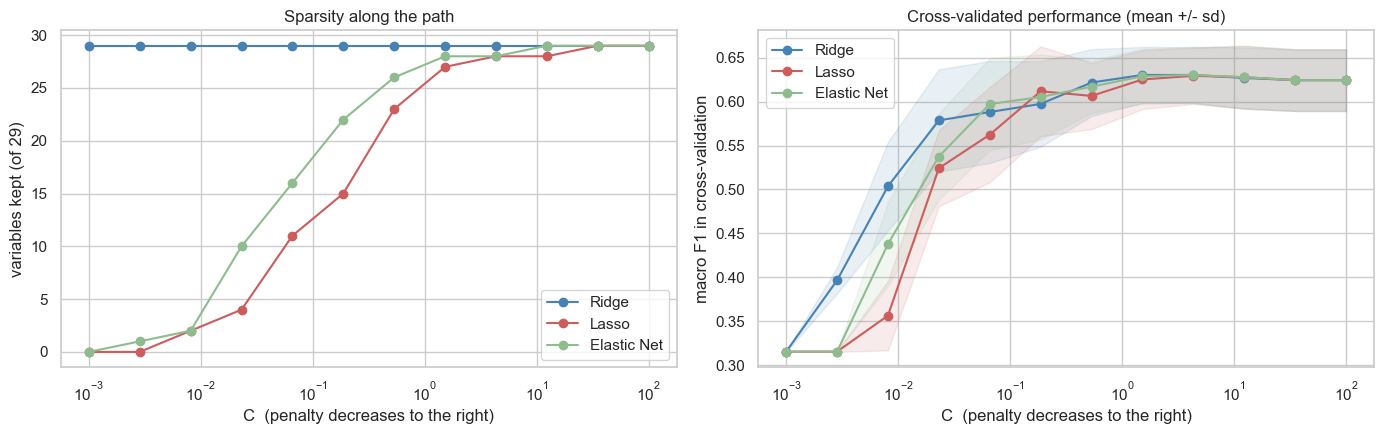

In [70]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
colors = {'Ridge': 'steelblue', 'Lasso': 'indianred', 'Elastic Net': 'darkseagreen'}

for name, _ in MODELS:
    model_rows = path_table[path_table['model'] == name]
    ax1.plot(model_rows['C'], model_rows[COL_VARIABLES], 'o-',
             color=colors[name], label=name)
    mean = model_rows['F1 macro (CV)']
    sd = model_rows['sd (CV)']
    ax2.plot(model_rows['C'], mean, 'o-', color=colors[name], label=name)
    ax2.fill_between(model_rows['C'], mean - sd, mean + sd,
                     color=colors[name], alpha=0.12)

ax1.set_xscale('log'); ax1.set_xlabel('C  (penalty decreases to the right)')
ax1.set_ylabel(COL_VARIABLES)
ax1.set_title('Sparsity along the path'); ax1.legend()

ax2.set_xscale('log'); ax2.set_xlabel('C  (penalty decreases to the right)')
ax2.set_ylabel('macro F1 in cross-validation')
ax2.set_title('Cross-validated performance (mean +/- sd)'); ax2.legend()

plt.tight_layout(); plt.show()

**Conclusions:** the path shows, in the two panels, very different behaviours across the three
penalties.

**Sparsity.** **Ridge keeps all 29 variables at every value of `C`**, from the most penalized to the
least. It is the visual demonstration that Ridge never selects: it shrinks coefficients but does not
zero them. **Lasso** is the most aggressive, with no variable up to `C` = 0.0028, two at 0.008, which
are `HbA1c_level` and `triglycerides`, four at 0.023, eleven at 0.066, fifteen at 0.187, twenty-three
at 0.534 and twenty-seven at 1.52, only reaching twenty-nine at 35.1. **Elastic Net** sits between the
two, as expected from a mixture of the two norms: ten variables where Lasso has four, sixteen where it
has eleven, and twenty-two where it has fifteen.

A caveat about the Ridge count. At `C` = 0.001 it counts 29 variables kept, yet its macro F1 is 0.3155,
exactly that of the trivial classifier. The coefficients are all practically zero without being
**exactly** zero, and the 1e-4 threshold used in the count does not tell the two situations apart.
**The variables-kept count is only informative for penalties that zero coefficients**, that is, for
Lasso and Elastic Net.

**Performance.** The three curves have the same shape, they rise, reach a maximum of **0.6303** and
level off. Ridge gets there at `C` = 1.5199, Elastic Net at 4.3288, and Lasso stays slightly below,
with 0.6293 at 4.3288. The difference between best and worst is 0.0010, against a between-fold standard
deviation of about 0.032.

Under strong penalization, however, **Ridge is clearly better**: at `C` = 0.0231 it reaches 0.5786
against 0.5242 for Lasso. That makes sense, because in that regime Lasso is already down to four
variables while Ridge keeps a little of all of them. The advantage disappears as soon as the penalty
loosens.

From `C` = 35.1 onwards the three level off at 0.6244, which corresponds to the practically
unregularized model. **Regularizing brings a real gain, of 0.0059 in macro F1**, but a modest one.

The maximum of each of these curves is exactly what the next section uses.

## 20. Choosing C by cross-validation

The path from the previous section already contains everything needed to decide: for each penalty and
each value of `C`, the mean and the standard deviation of the macro F1 obtained over the five
validation folds. It is therefore enough to **take the maximum of each curve**, without repeating any
computation.

Once `C` is chosen, each model is refitted on the whole training set and only then evaluated on the
test set, which up to this point has taken part in no decision.

In [71]:
def fit_at(l1_ratio, C, X_train_df, mean, sd, class_weight=None):
    """Refits the model on the full training set for an already chosen C."""
    inner_scaler = StandardScaler()
    X_scaled = inner_scaler.fit_transform(X_train_df)
    model = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                               max_iter=10000, class_weight=class_weight,
                               random_state=RANDOM_STATE).fit(X_scaled, y_train)
    return {'C': C, 'f1_cv': mean, 'sd_cv': sd,
            'model': model, 'scaler': inner_scaler}

def tune(l1_ratio, X_train_df, class_weight=None, grid=None):
    """Sweeps a grid of C, picks the best and refits on the full training set."""
    grid = C_GRID if grid is None else grid
    evaluations = [(C,) + evaluate_cv(l1_ratio, C, X_train_df, y_train, class_weight)
                   for C in grid]
    best_C, mean, sd = max(evaluations, key=lambda row: row[1])
    return fit_at(l1_ratio, best_C, X_train_df, mean, sd, class_weight)

def summary(fit, name, X_test_df, column_names, k):
    predicted = fit['model'].predict(fit['scaler'].transform(X_test_df))
    recalls = recall_score(y_test, predicted, average=None, labels=classes)
    _, _, n_columns = variables_kept(fit['model'], column_names)
    return {'model': name, 'variables in set': k, 'C*': fit['C'],
            'F1 macro (CV)': fit['f1_cv'],
            'sd (CV)': fit['sd_cv'],
            'F1 macro (test)': f1_score(y_test, predicted, average='macro'),
            'accuracy': accuracy_score(y_test, predicted),
            'balanced acc': balanced_accuracy_score(y_test, predicted),
            'columns kept': n_columns,
            **{f'recall {c}': r for c, r in zip(classes, recalls)}}

# The best C for each model comes straight from the path already computed in section 19
fits = {}
for name, ratio in MODELS:
    model_rows = path_table[path_table['model'] == name]
    best = model_rows.loc[model_rows['F1 macro (CV)'].idxmax()]
    fits[name] = fit_at(ratio, best['C'], X_train,
                        best['F1 macro (CV)'], best['sd (CV)'])

pd.DataFrame([summary(f, name, X_test, columns, N_VARIABLES)
              for name, f in fits.items()]).set_index('model').round(4)

,variables in set,C*,F1 macro (CV),sd (CV),F1 macro (test),accuracy,balanced acc,columns kept,recall DI_HT,recall DI_HY,recall HT
model,,,,,,,,,,,
Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Lasso,29,4.3288,0.6293,0.0319,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Elastic Net,29,4.3288,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621


**Conclusions:** taking the maximum of each curve of the path, Ridge chooses `C` = **1.5199** and Lasso
and Elastic Net choose **4.3288**. The cross-validated macro F1 values are 0.6303 for Ridge, 0.6293 for
Lasso and 0.6303 for Elastic Net, with between-fold standard deviations of 0.0318, 0.0319 and 0.0318.
The difference between best and worst is 0.0010, more than thirty times smaller than the dispersion
between folds. **None of the three is superior to the others in this problem.**

Note that Ridge reaches 0.6303 both at `C` = 1.5199 and at 4.3288. Faced with a tie, the selection
keeps the first, that is, the stronger penalty, which is the preferable choice between two equivalent
solutions.

On the test set, used here for the first time, the three obtain exactly the same: 0.9440 *accuracy*,
0.6185 balanced accuracy and 0.5978 macro F1. **The *recall* of the `DI_HT` class is 0.0000 for all
three**, that is, not one of the 21 occurrences of this class is detected. This is the problem that
section 24 addresses.

The chosen `C` corresponds to a weak penalty, and so hardly any variable is eliminated, with 38 to 39
columns kept out of 39 and all 29 variables present in the three models. This happens because the
penalty that maximizes performance is insufficient to zero coefficients. To obtain an effectively
reduced set one has to impose a stronger penalty, which is done in section 23.

The grid used has only twelve values, spaced by a factor of **2.848**, which is the ratio between
consecutive points of `np.logspace(-3, 2, 12)`. The chosen `C` is therefore a coarse approximation: the
true optimum may lie anywhere between the two neighbours. The next section looks, inside that interval,
for a better intermediate value.

## 21. Refining C in the most favourable interval

The grid of section 19 spans five orders of magnitude in twelve points, which is adequate for locating
the region of good performance but too wide to identify the best value inside it. Between two
consecutive points there is a factor of **2.848**, and the optimum may lie anywhere in that interval.

The search is therefore refined. For each penalty we take the interval between the **two neighbours**
of the `C` chosen on the coarse grid and evaluate nine values equally spaced on a logarithmic scale,
by the same stratified cross-validation and always standardizing inside each fold.

Besides the mean macro F1, we record the **standard deviation across the five folds**. It is that
dispersion that lets us decide whether a difference between two values of `C` is real or whether it
falls inside the natural variation of cross-validation.

In [72]:
def fine_grid(C_center, n=9):
    """Nine values between the two neighbours of C_center on the coarse grid."""
    i = int(np.argmin(np.abs(C_GRID - C_center)))
    lower = C_GRID[max(i - 1, 0)]
    upper = C_GRID[min(i + 1, len(C_GRID) - 1)]
    return np.logspace(np.log10(lower), np.log10(upper), n)

fine_paths = {}
for name, ratio in MODELS:
    fine_rows = [{'C': C, 'F1 macro (CV)': m, 'sd (CV)': d}
                 for C in fine_grid(fits[name]['C'])
                 for m, d in [evaluate_cv(ratio, C, X_train, y_train)]]
    fine_paths[name] = pd.DataFrame(fine_rows)

C_comparison = []
for name, _ in MODELS:
    fine_path = fine_paths[name]
    best = fine_path.loc[fine_path['F1 macro (CV)'].idxmax()]
    C_comparison.append({
        'model': name,
        'C (coarse grid)': fits[name]['C'],
        'F1 macro (coarse)': fits[name]['f1_cv'],
        'C (fine grid)': best['C'],
        'F1 macro (fine)': best['F1 macro (CV)'],
        'sd (fine)': best['sd (CV)'],
        'gain': best['F1 macro (CV)'] - fits[name]['f1_cv']})

C_comparison = pd.DataFrame(C_comparison).set_index('model')
C_comparison

,C (coarse grid),F1 macro (coarse),C (fine grid),F1 macro (fine),sd (fine),gain
model,,,,,,
Ridge,1.5199,0.6303,1.5199,0.6303,0.0318,0.0000
Lasso,4.3288,0.6293,5.6234,0.6303,0.0318,0.0010
Elastic Net,4.3288,0.6303,3.3322,0.6303,0.0318,0.0000


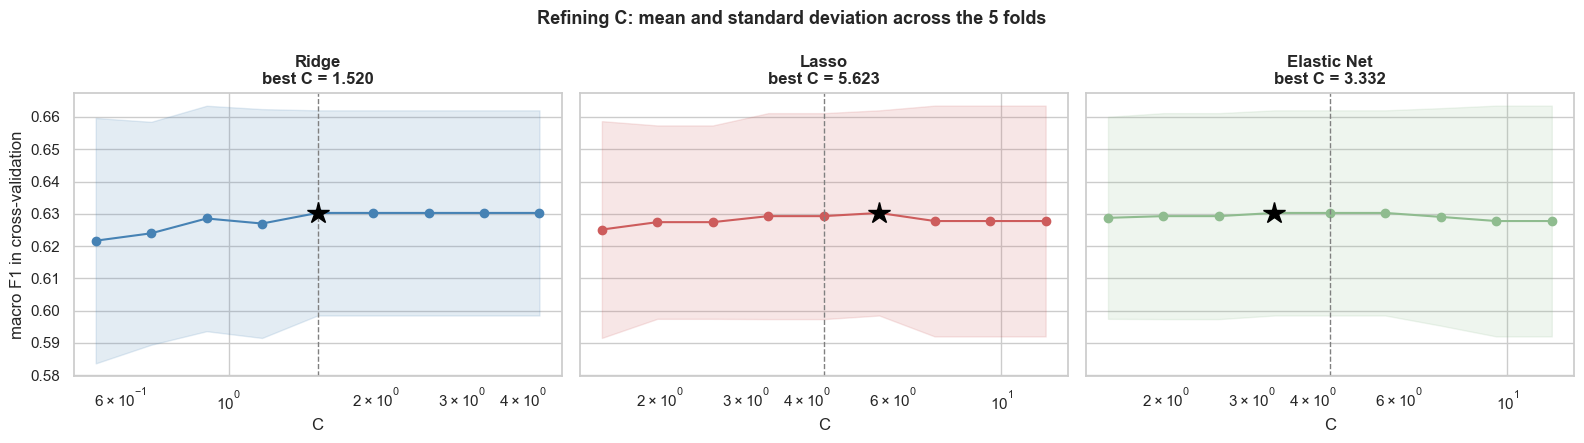

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colors = {'Ridge': 'steelblue', 'Lasso': 'indianred', 'Elastic Net': 'darkseagreen'}

for axis, (name, _) in zip(axes, MODELS):
    fine_path = fine_paths[name]
    mean = fine_path['F1 macro (CV)']
    sd = fine_path['sd (CV)']
    axis.plot(fine_path['C'], mean, 'o-', color=colors[name])
    axis.fill_between(fine_path['C'], mean - sd, mean + sd,
                      color=colors[name], alpha=0.15)
    axis.axvline(fits[name]['C'], ls='--', color='grey', lw=1)
    best = fine_path.loc[mean.idxmax()]
    axis.plot(best['C'], best['F1 macro (CV)'], '*', ms=16, color='black')
    axis.set_xscale('log')
    axis.set_xlabel('C')
    axis.set_title(f"{name}\nbest C = {best['C']:.3f}", weight='bold')

axes[0].set_ylabel('macro F1 in cross-validation')
fig.suptitle('Refining C: mean and standard deviation across the 5 folds',
             fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusions:** the refinement sweeps, for Ridge, the interval between `C` = 0.534 and 4.329, and for
Lasso and Elastic Net the interval between 1.520 and 12.329, which are in each case the two neighbours
of the value chosen on the coarse grid.

The results are practically null. **Ridge stays at 1.5199**, with none of the nine intermediate values
beating it. **Lasso moves to 5.6234**, with a gain of 0.0010, and **Elastic Net to 3.3322**, with zero
gain, tying with the previous value.

Curiously, after the refinement **the three end up with exactly the same performance**, 0.6303 macro F1
with a standard deviation of 0.0318. The small advantage that Ridge and Elastic Net had over Lasso
disappears once the latter finds its best value.

The decisive comparison is with the **standard deviation across the five folds**, of 0.0318, that is,
more than thirty times the single gain obtained. The bands in the chart make this visible: the curve is
**flat across the whole region** and any value of `C` between 1 and 10 produces statistically
indistinguishable performance.

The conclusion is not that the refinement was useless, but that **performance is insensitive to `C` in
this region**. That is useful information, because it means the choice of the hyperparameter is not a
weak point of the model, and that there is no point in searching any deeper: what limits performance is
the signal available in the variables and not the tuning of the penalty.

In [74]:
refined_fits = {name: fit_at(ratio, row['C (fine grid)'], X_train,
                             row['F1 macro (fine)'], row['sd (fine)'])
                for (name, ratio), (_, row) in zip(MODELS, C_comparison.iterrows())}

pd.DataFrame([summary(f, name, X_test, columns, len(num_cols) + len(cat_cols))
              for name, f in refined_fits.items()]).set_index('model').round(4)

,variables in set,C*,F1 macro (CV),sd (CV),F1 macro (test),accuracy,balanced acc,columns kept,recall DI_HT,recall DI_HY,recall HT
model,,,,,,,,,,,
Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Lasso,29,5.6234,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Elastic Net,29,3.3322,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621


**Conclusions:** refitting the models at the refined `C` and evaluating on the test set, the results are
**exactly the same as those of the coarse grid**: 0.9440 *accuracy*, 0.6185 balanced accuracy and
0.5978 macro F1 for all three.

This confirms the flatness observed in cross-validation. It was verified that, in the three models,
moving from the coarse `C` to the refined one **does not change a single one of the 500 test
predictions**.

The per-class *recalls* expose the real problem: 0.9933 in `DI_HY`, 0.8621 in `HT` and **0.0000 in
`DI_HT`**. The model does not detect a single case of the minority class, a limitation that section 24
addresses.

## 22. Coefficients and selected variables

We compare the magnitudes of the coefficients of the three penalties at the `C` refined in the previous
section. Since the problem has three classes, the model estimates a coefficient matrix with one row per
class, so we use the largest absolute value of the three as the measure of each column's influence.

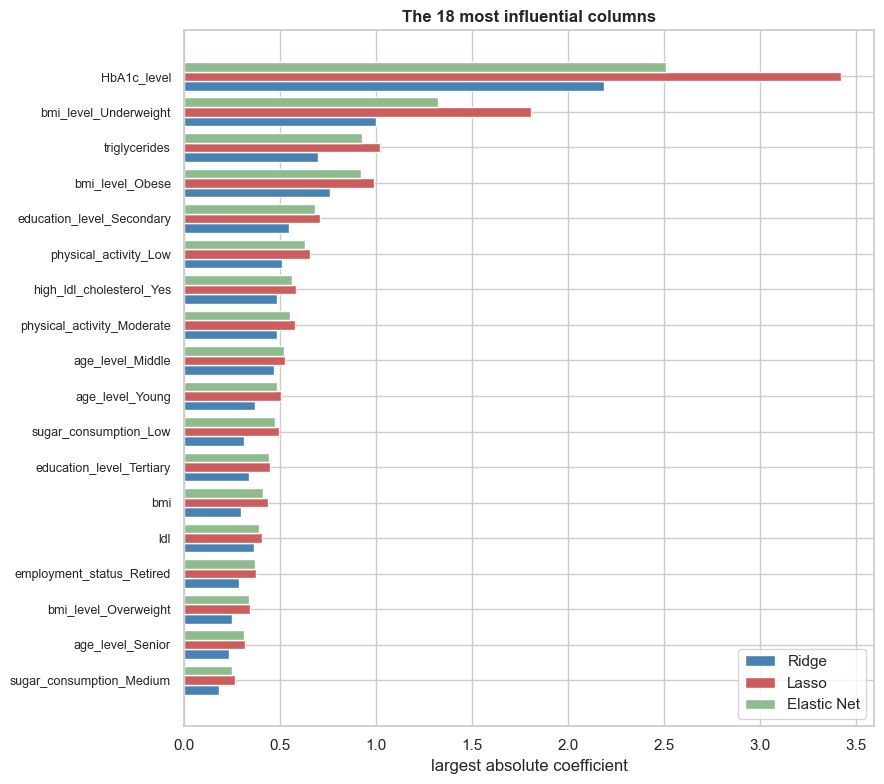

,Ridge,Lasso,Elastic Net
HbA1c_level,2.1857,3.4228,2.5093
bmi_level_Underweight,1.0014,1.8048,1.3216
triglycerides,0.6970,1.0225,0.9276
bmi_level_Obese,0.7577,0.9871,0.9231
education_level_Secondary,0.5477,0.7088,0.6841
physical_activity_Low,0.5101,0.6574,0.6271
high_ldl_cholesterol_Yes,0.4839,0.5799,0.5633
physical_activity_Moderate,0.4842,0.5796,0.5526
age_level_Middle,0.4658,0.5232,0.5221
age_level_Young,0.3695,0.5060,0.4815


In [75]:
coef_table = pd.DataFrame(
    {name: magnitudes(f['model']) for name, f in refined_fits.items()},
    index=columns
).sort_values('Lasso', ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
top = coef_table.head(18).iloc[::-1]
position = np.arange(len(top))
for offset, name, color in [(-0.27, 'Ridge', 'steelblue'),
                            (0.0, 'Lasso', 'indianred'),
                            (0.27, 'Elastic Net', 'darkseagreen')]:
    ax.barh(position + offset, top[name], height=0.27, label=name, color=color)
ax.set_yticks(position); ax.set_yticklabels(top.index, fontsize=9)
ax.set_xlabel('largest absolute coefficient')
ax.set_title('The 18 most influential columns', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

coef_table.round(4).head(12)

**Conclusions:** the three penalties agree on the ordering of the variables. `HbA1c_level` dominates by
a wide margin, with a maximum coefficient of 3.42 under Lasso, about twice the next one, which is
`bmi_level_Underweight` with 1.80. Then come `triglycerides` with 1.02, `bmi_level_Obese` with 0.99 and
`education_level_Secondary` with 0.71.

The Ridge magnitudes are **systematically smaller on the dominant variables**, with 2.19 against 3.42
for `HbA1c_level` and 1.00 against 1.80 for `bmi_level_Underweight`. This is the expected effect of the
L2 norm, which spreads the penalty across all coefficients instead of concentrating it on the small
ones. Elastic Net sits, here too, between the other two.

This hierarchy coincides with the one the exploratory analysis had established by statistical means, in
the Kruskal-Wallis tests, where `HbA1c_level` and `triglycerides` showed the largest effect sizes, with
η² of 0.410 and 0.105, and where `bmi_level` appeared among the categorical variables with the highest
Cramér's V. **Two independent methods identify the same variables as relevant.**

## 23. Full set vs. reduced sets

The assignment asks us to assess the **impact** of feature selection on performance. Impact is a
difference, and so the full set has to be compared with smaller sets, under the same conditions.

**Where the reduced sets come from.** They are not hand-picked nor taken from the conclusions of the
exploratory analysis. They are the sets that **Lasso itself selects** at two points of the path of
section 19, which requires only imposing a stronger penalty than the one that maximizes performance.

**Why these two points and not others.** The path has twelve values of `C`, but most of them are of no
use for this comparison:

| `C` | Variables kept | Why it does not serve, or does |
|---|---|---|
| 0.001 to 0.0028 | 0 | the model collapses onto the majority class |
| 0.0081 to 0.0231 | 2 to 4 | too violent a reduction, the model stops being usable |
| **0.0658** | **11** | **aggressive cut, little more than a third of the variables, and still functional** |
| **0.1874** | **15** | **intermediate cut, roughly half the variables** |
| 0.5337 | 23 | keeps 23 of 29, little reduction to measure |
| 1.5199 and above | 27 to 29 | practically no reduction |

The two points chosen are therefore **the only ones where a trade-off actually exists to be
quantified**: a moderate cut and an aggressive one, far enough apart for the difference between them to
be visible, and both above the threshold at which the model stops working.

**What this criterion is and what it is not.** It is a decision about the granularity of the
comparison, taken in view of the path, and not a statistical criterion. Formal rules exist for choosing
the level of penalization, but they are not part of the material covered in the course, and so we
prefer to own the judgement rather than invoke a rigour that was not applied. What is **not** our
decision is the composition of the sets: given the cut-off point, the variables that make it up are
determined entirely by Lasso.

Each set is evaluated with the three penalties, with `C` chosen again by the same two-phase procedure
of section 21 and the standardization redone inside each fold, so that the comparison is fair.

In [76]:
def columns_of_variables(variables_num, variables_cat):
    """Encoded columns corresponding to a set of original variables."""
    return [c for c in columns
            if c in variables_num or any(c.startswith(k + '_') for k in variables_cat)]

def lasso_selection(C):
    model = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                               max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    kept_num, kept_cat, _ = variables_kept(model, columns)
    return kept_num, kept_cat

def tune_two_phase(l1_ratio, X_train_df):
    """Coarse grid followed by refinement, as in section 21."""
    coarse = tune(l1_ratio, X_train_df)
    return tune(l1_ratio, X_train_df, grid=fine_grid(coarse['C']))

# Two points of the path of section 19: intermediate penalty and strong penalty
C_MEDIUM, C_STRONG = C_GRID[5], C_GRID[4]
medium_num, medium_cat = lasso_selection(C_MEDIUM)
strong_num, strong_cat = lasso_selection(C_STRONG)
n_medium = len(medium_num) + len(medium_cat)
n_strong = len(strong_num) + len(strong_cat)

SETS = {
    'Full': (num_cols, cat_cols),
    f'Reduced ({n_medium})': (medium_num, medium_cat),
    f'Reduced ({n_strong})': (strong_num, strong_cat),
}

print(f'Reduced set with {n_strong} variables (C = {C_STRONG:.4f}):')
print(' ', sorted(strong_num + strong_cat))
print(f'\nEliminated in the set of {n_medium} variables (C = {C_MEDIUM:.4f}):')
print(' ', sorted(set(num_cols + cat_cols) - set(medium_num + medium_cat)))

comparison_rows = []
for name, (v_num, v_cat) in SETS.items():
    set_cols = columns_of_variables(v_num, v_cat)
    for label, ratio in MODELS:
        fit = tune_two_phase(ratio, X_train[set_cols])
        comparison_rows.append(summary(fit, f'{name} | {label}', X_test[set_cols],
                                       set_cols, len(v_num) + len(v_cat)))

results = pd.DataFrame(comparison_rows).set_index('model')
results.round(4)

Reduced set with 11 variables (C = 0.0658):
  ['HbA1c_level', 'age', 'age_level', 'blood_pressure', 'bmi', 'bmi_level', 'crp_level', 'employment_status', 'low_hdl_cholesterol', 'smoking', 'triglycerides']

Eliminated in the set of 15 variables (C = 0.1874):
  ['age', 'alcohol_intake', 'bmi', 'cholesterol', 'diastolic_bp', 'family_history', 'gender', 'hdl', 'heart_rate', 'ldl', 'salt_intake', 'sleep_hours', 'stress_level', 'systolic_bp']


,variables in set,C*,F1 macro (CV),sd (CV),F1 macro (test),accuracy,balanced acc,columns kept,recall DI_HT,recall DI_HY,recall HT
model,,,,,,,,,,,
Full | Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Full | Lasso,29,5.6234,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Full | Elastic Net,29,3.3322,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Reduced (15) | Ridge,15,1.9745,0.6472,0.0247,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduced (15) | Lasso,15,4.3288,0.6458,0.0237,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduced (15) | Elastic Net,15,3.3322,0.6458,0.0237,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduced (11) | Ridge,11,0.6933,0.6152,0.0519,0.5967,0.9400,0.6170,17,0.0000,0.9889,0.8621
Reduced (11) | Lasso,11,0.9006,0.6201,0.0635,0.5967,0.9400,0.6170,16,0.0000,0.9889,0.8621
Reduced (11) | Elastic Net,11,1.1700,0.6152,0.0519,0.5967,0.9400,0.6170,17,0.0000,0.9889,0.8621


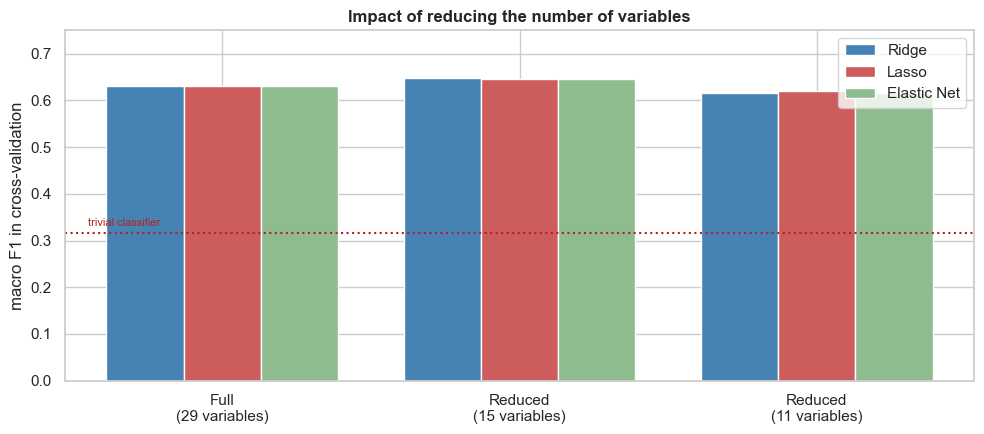

In [77]:
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.26
position = np.arange(len(SETS))
for offset, (label, _), color in zip([-width, 0, width], MODELS,
                                     ['steelblue', 'indianred', 'darkseagreen']):
    values = [results.loc[f'{name} | {label}', 'F1 macro (CV)'] for name in SETS]
    ax.bar(position + offset, values, width, label=label, color=color)
ax.set_xticks(position)
ax.set_xticklabels([f"{n.split(' (')[0]}\n({len(v[0]) + len(v[1])} variables)"
                    for n, v in SETS.items()])
# Reference: the worst point of the path, where the model predicts only the majority class
trivial = path_table['F1 macro (CV)'].min()
ax.axhline(trivial, ls=':', color='firebrick')
ax.text(-0.45, trivial + 0.015, 'trivial classifier', fontsize=8, color='firebrick')

ax.set_ylabel('macro F1 in cross-validation'); ax.set_ylim(0, 0.75)
ax.set_title('Impact of reducing the number of variables', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

**Conclusions:** the result is stronger than the mere absence of a cost.

| Set | Variables | Best macro F1 (CV) | Difference to the full set | sd (CV) |
|---|---|---|---|---|
| Full | 29 | 0.6303 | - | 0.0318 |
| Reduced | 15 | **0.6472** (Ridge) | **+0.0169** | 0.0247 |
| Reduced | 11 | 0.6201 (Lasso) | −0.0102 | 0.0635 |

**Cutting to almost half the variables improves performance.** The set of 15 variables reaches 0.6472
in cross-validation against 0.6303 for the full set, and it does so with a **smaller between-fold
standard deviation**, 0.0247 against 0.0318. On the test set the advantage holds, although smaller,
with 0.6020 against 0.5978. This is the classic behaviour of feature selection: removing variables with
no signal reduces the model's variance, and the gain outweighs the little that is lost in bias.

The obligatory caveat is that **+0.0169 is still smaller than the between-fold standard deviation**, so
the evidence points towards an improvement but does not establish it conclusively.

Going down to 11 variables does have a price, of 0.0102 relative to the full set, and above all it
makes the result **much more unstable**, with the standard deviation rising to 0.0635, twice that of
the full set. It is the sign that the cut went below what was needed.

**The sets are not nested, and that is informative.** The 11 variables are **not** a subset of the 15:
`age` and `bmi` enter at `C` = 0.0658 and leave at 0.1874. The reason is that the set of 15 includes
`age_level` and `bmi_level`, the discretized versions of the same quantities. With more penalty budget,
Lasso **swaps** the continuous variable for the categorical one, which captures the same information
more effectively for this problem. The Lasso path is therefore not a sequence of inclusions: variables
can enter and leave again.

**The selection agrees with the exploratory analysis.** Of the 14 variables eliminated in the set of
15, eleven, `alcohol_intake`, `cholesterol`, `diastolic_bp`, `gender`, `hdl`, `heart_rate`, `ldl`,
`salt_intake`, `sleep_hours`, `stress_level` and `systolic_bp`, **all appear** in the list of variables
that the statistical tests had classified as uninformative (p-value above 0.05 in the Kruskal-Wallis or
the χ² test). Of that list only `crp_level` and `plasma_value` escape the cut. The other three are `age`, `bmi` and
`family_history`, and the first two leave only because their discretized versions stayed, as explained
above.

The set of 11 keeps `HbA1c_level`, `triglycerides`, `age`, `bmi` and `blood_pressure`, five of the six
numeric variables with a significant effect in the exploratory analysis, plus `age_level`, `bmi_level`
and `low_hdl_cholesterol`, the latter the one with the highest Cramér's V. It does however include
`crp_level`, which the statistical tests had not singled out, with a p-value of 0.298. Selection by
penalization **does not remove all the noise**, which justifies always confronting it with the prior
statistical evidence.

Within each set the three penalties are practically equivalent, with maximum differences of 0.0049. The
*recall* of `DI_HT` is **zero in all nine combinations**, which shows that the imbalance problem is
solved neither by selecting variables nor by regularizing.

A methodological caveat: the reduced sets are defined by a Lasso fitted on the whole training set and
then evaluated by cross-validation on that same training set. The validation folds contributed
indirectly to the choice of the variables, so the values for the reduced sets are slightly optimistic.
The test set, for its part, never took part in any decision.

## 24. Effect of class balancing

All the previous models reach *accuracy* above 0.94 but a balanced accuracy of only 0.6185. The reason
is that they almost always get the majority class right and miss the minority one, a consequence of
about 90 per cent of the records belonging to a single class.

The `class_weight='balanced'` parameter weights each class by the inverse of its frequency, forcing the
model to give importance to the small classes. With 1348 `DI_HY` records, 88 `HT` and 64 `DI_HT` in the
training set, the weights assigned are 0.371, 5.682 and 7.812.

The two configurations are tuned by the **same two-phase procedure** used in sections 20 and 21.

This comparison uses only the **L2 penalty**, because the `saga` algorithm **does not converge** when
`class_weight` is applied.

The alternative would be `liblinear`, but that one stopped supporting multiclass problems from version
1.8 of scikit-learn onwards. `lbfgs`, which converges without difficulty, **supports only the L2
penalty**, so Lasso and Elastic Net are left without a viable solver for this comparison. We therefore
use `lbfgs` with L2 on both sides, which keeps the comparison internally coherent.

In [78]:
def evaluate_cv_lbfgs(C, class_weight):
    """The same manual cross-validation, with the lbfgs solver and the L2 penalty."""
    scores = []
    for train_idx, valid_idx in cv.split(X_train, y_train):
        fold_scaler = StandardScaler()
        X_a_scaled = fold_scaler.fit_transform(X_train.iloc[train_idx])
        X_b_scaled = fold_scaler.transform(X_train.iloc[valid_idx])
        model = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=C, max_iter=10000,
                                   class_weight=class_weight,
                                   random_state=RANDOM_STATE)
        model.fit(X_a_scaled, y_train.iloc[train_idx])
        scores.append(f1_score(y_train.iloc[valid_idx],
                               model.predict(X_b_scaled), average='macro'))
    return float(np.mean(scores)), float(np.std(scores))

def tune_lbfgs_two_phase(class_weight):
    """Coarse grid followed by refinement, as in sections 20 and 21."""
    coarse = max(((C,) + evaluate_cv_lbfgs(C, class_weight) for C in C_GRID),
                 key=lambda row: row[1])
    fine = max(((C,) + evaluate_cv_lbfgs(C, class_weight) for C in fine_grid(coarse[0])),
               key=lambda row: row[1])
    return coarse, fine

weight_comparison = []
predictions = {}
for weight in (None, 'balanced'):
    coarse, fine = tune_lbfgs_two_phase(weight)
    best_C, f1_cv, sd_cv = fine

    final_scaler = StandardScaler()
    X_scaled = final_scaler.fit_transform(X_train)
    model = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=best_C,
                               max_iter=10000, class_weight=weight,
                               random_state=RANDOM_STATE).fit(X_scaled, y_train)
    predicted = model.predict(final_scaler.transform(X_test))
    recalls = recall_score(y_test, predicted, average=None, labels=classes)
    weight_comparison.append({
        'class_weight': str(weight),
        'C (coarse grid)': coarse[0], 'F1 macro (coarse)': coarse[1],
        'C* (refined)': best_C,
        'F1 macro (CV)': f1_cv, 'sd (CV)': sd_cv,
        'F1 macro (test)': f1_score(y_test, predicted, average='macro'),
        'accuracy': accuracy_score(y_test, predicted),
        'balanced acc': balanced_accuracy_score(y_test, predicted),
        **{f'recall {c}': r for c, r in zip(classes, recalls)}})
    predictions[str(weight)] = predicted

pd.DataFrame(weight_comparison).set_index('class_weight').round(4)

,C (coarse grid),F1 macro (coarse),C* (refined),F1 macro (CV),sd (CV),F1 macro (test),accuracy,balanced acc,recall DI_HT,recall DI_HY,recall HT
class_weight,,,,,,,,,,,
None,1.5199,0.6303,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,0.0000,0.9933,0.8621
balanced,0.0081,0.6224,0.0137,0.6252,0.0302,0.6585,0.8460,0.7809,0.5238,0.8533,0.9655


=== without balancing ===
              precision    recall  f1-score   support

       DI_HT     0.0000    0.0000    0.0000        21
       DI_HY     0.9551    0.9933    0.9739       450
          HT     0.7812    0.8621    0.8197        29

    accuracy                         0.9440       500
   macro avg     0.5788    0.6185    0.5978       500
weighted avg     0.9049    0.9440    0.9240       500

=== with class_weight='balanced' ===
              precision    recall  f1-score   support

       DI_HT     0.1528    0.5238    0.2366        21
       DI_HY     0.9871    0.8533    0.9154       450
          HT     0.7179    0.9655    0.8235        29

    accuracy                         0.8460       500
   macro avg     0.6193    0.7809    0.6585       500
weighted avg     0.9365    0.8460    0.8815       500



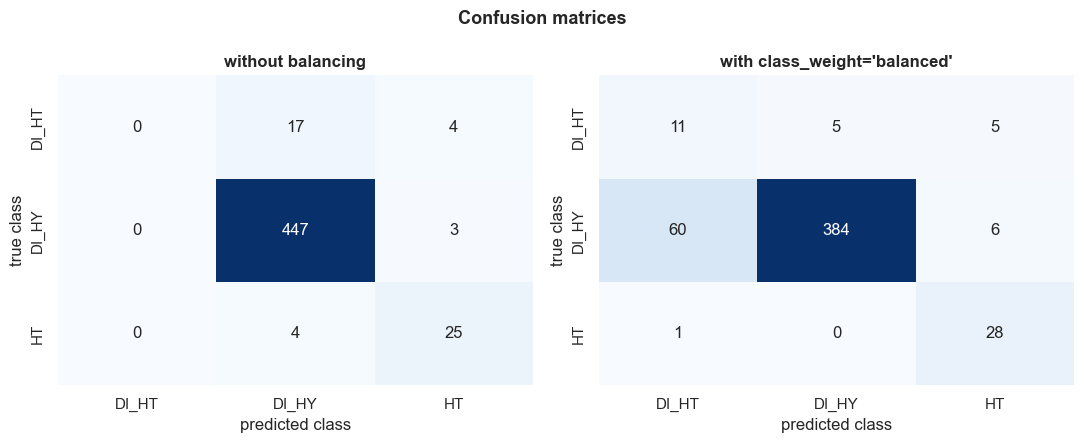

In [79]:
CONFIGURATIONS = [('None', 'without balancing'),
                  ('balanced', "with class_weight='balanced'")]

for label, title in CONFIGURATIONS:
    print(f'=== {title} ===')
    print(classification_report(y_test, predictions[label], labels=classes, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, (label, title) in zip(axes, CONFIGURATIONS):
    matrix = confusion_matrix(y_test, predictions[label], labels=classes)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=axis)
    axis.set_xlabel('predicted class'); axis.set_ylabel('true class')
    axis.set_title(title, weight='bold')
fig.suptitle('Confusion matrices', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusions:** this time the refinement does have an effect on the balanced side. Without balancing
the best `C` stays at **1.5199**, with zero gain. With `class_weight='balanced'`, the coarse grid
chooses 0.0081 and the refinement moves it to **0.0137**, with a gain of 0.0028, which is still ten
times smaller than the between-fold standard deviation.

The optimal penalty with balancing is about **a hundred times stronger** than without it. By giving a
weight of 7.812 to the 64 `DI_HT` observations, the model gains a much greater incentive to fit
individual cases, and needs considerably more aggressive regularization to stop it from doing so.

**The effect on the metrics is the most striking result in the whole notebook.** Without balancing, the
model reaches 0.9440 *accuracy* but **0.0000 *recall* on `DI_HT`**: it does not identify a single one
of the 21 occurrences of that class. With balancing, the *recall* rises to 0.5238, the balanced
accuracy from 0.6185 to 0.7809 and, contrary to what one would expect, **the macro F1 on the test set
also rises**, from 0.5978 to 0.6585. The *accuracy* drops to 0.8460.

In other words, **here balancing is not a trade-off, it is an improvement along almost the whole
line**. The reason is that a recall of zero on one of the three classes drags the macro F1 down: the F1
of that class is 0.0000 and enters the average with the same weight as the other two.

The confusion matrices show what lies behind this. Without balancing, of the 21 real occurrences of
`DI_HT` the model sends **17 to `DI_HY` and 4 to `HT`**, getting none of them right. With balancing it
identifies **11**, but in exchange it wrongly classifies **60 `DI_HY` records as `DI_HT`**. The effect
on precision is severe: on `DI_HT` it ends up at 0.1528, that is, when the model announces `DI_HT` it
is right in about one case out of seven.

Note also that balancing **benefits the `HT` class too**, whose *recall* rises from 0.8621 to 0.9655.

In both configurations the errors concentrate on the separation between `DI_HT` and `DI_HY`, the two
classes whose overlap the exploratory analysis had already identified.

The preferable configuration depends on the relative cost of the two kinds of error, information of a
clinical nature that the assignment does not provide. But here, unlike the usual case, balancing
improves the two metrics that give equal weight to the classes and only worsens *accuracy*, which is
precisely the least reliable metric in this problem.

## 25. Discussion

**The three penalties perform equivalently.** After the refinement, Ridge, Lasso and Elastic Net obtain
exactly the same cross-validated macro F1 on the full set, 0.6303, and on the reduced sets the
differences between them do not exceed 0.0049, a value far below the between-fold standard deviation,
which is around 0.03. Choosing between them cannot be justified, in this problem, by performance.

**Ridge never selects, and now one can see it.** In the sparsity panel of section 19 its line is a
horizontal at 29 variables for every value of `C`, while those of Lasso and Elastic Net come down. It
is the difference between shrinking coefficients and zeroing them, shown instead of asserted.

**Ridge had no advantage to offer.** Its reason for being is to stabilize coefficients when the
predictors are correlated. The exploratory analysis showed that, once the redundant columns are
removed, **the correlations between the retained variables are practically null**, with every variance
inflation factor below 1.05, the maximum being 1.0441, and the condition number falling from 1.75e+15
to 1.29 (Part 1, section 3.2). On datasets where the predictors are strongly correlated, Ridge
clearly beats the unregularized solution; here there is no collinearity to stabilize.

**Tuning `C` is not the limiting factor.** The refinement of section 21 showed that the whole interval
between `C` = 1 and 10 produces indistinguishable performance, with gains thirty times smaller than the
variation between folds. What limits the model is the signal available in the variables.

**Feature selection pays off, and more than expected.** Going from 29 to 15 variables **improves** the
cross-validated macro F1, from 0.6303 to 0.6472, and reduces the dispersion between folds from 0.0318
to 0.0247. It is the classic argument in favour of selection: fewer variables without signal mean less
variance. Cutting beyond that, down to 11 variables, reverses the effect and doubles the dispersion.

**The selection confirms the exploratory analysis.** Eleven of the fourteen variables eliminated at no
cost are exactly those that the statistical tests had classified as uninformative, and those that
survive the strongest penalties include `HbA1c_level` and `triglycerides`, the two with the largest
effect sizes. The agreement between an automatic method and an independent statistical analysis
reinforces both.

**The imbalance is the dominant limitation.** No combination of penalty and variable set detects a
single occurrence of `DI_HT`: the *recall* is zero in the nine combinations tested in section 23. Only
class balancing solves the problem, raising it to 0.5238. The limitation lies not in the regularization
but in the 85 occurrences that this class has in the dataset.

## 26. References

**Assignment and data**

- *Aprendizagem Automática (APRAU), Assignment*, ISEP, MEI, 2026/2027, version 1.0, section 5.
- `dataset_grupo_22.csv`, a subset of 2000 records provided to group 22.

**Course lectures** (Elsa Ferreira Gomes, ISEP, 2026/2027)

- *T5, Linear Model Selection and Regularization: Ridge Regression, the Lasso and Elastic Net*,
  including the section on regularization applied to classification.
- *TP5, Example: Ridge, Lasso and Elastic net Regression*, practical worksheet consulted.
- *T4, Evaluation and Resampling*, for the stratified cross-validation.
- *Classification Metrics: Confusion Matrix and Beyond*, for the choice of metrics.

**Bibliography**

- James, G., Witten, D., Hastie, T., Tibshirani, R., *An Introduction to Statistical Learning with
  Python*, chapter 6.

**Previous work by the group**

- `notebooks/01_EDA.ipynb`, the source of the removal of the redundant columns and of the expectations
  about which variables are informative.

**Libraries**

- pandas, NumPy, Matplotlib, seaborn and scikit-learn.